# Actividades 5 y 6. Pruebas de hipótesis, modelado y análisis multivariante

**Actividad 5:** Pruebas de Hipótesis y Visualización Interactiva  
**Actividad 6:** Análisis Multivariante y Creación de Dashboards Interactivos  
**Proyecto integrador:** fase 3, pruebas de hipótesis, modelado supervisado y análisis multivariante  
**Autor:** Julián Andrés Lasso Figueroa  
**Correo institucional:** jlasso96@unisalle.edu.co  
**Programa:** Maestría en Inteligencia Artificial, Universidad de La Salle  
**Asignatura:** Ciencia de Datos, Unidad 2, herramientas de visualización avanzada  
**Docente:** Fabián Camilo Castro Riveros  
**Fecha:** noviembre de 2026

---

## 0. Planteamiento y configuración

### 0.1. Preguntas, hipótesis y mapa del cuaderno

La fase 1 describió el Saber 11 de 2022-2 y planteó las preguntas del proyecto; la fase 2 preparó los datos, fijó la partición y dejó los modelos base que esta fase tiene que superar. Esta fase responde las tres preguntas secundarias:

- **S1 (regresión).** ¿Cuánto del puntaje global explican las condiciones del hogar y del colegio, sin usar los puntajes por área ni el de inglés?
- **S2 (clasificación).** ¿Qué tan separables son los perfiles de los estudiantes de colegios oficiales y no oficiales a partir de su hogar?
- **S3 (segmentación).** ¿Qué perfiles de desempeño por área existen y cómo se reparten por estrato, zona y naturaleza del colegio?

Antes de modelar, somete a prueba las cuatro hipótesis del proyecto, cada una con su tamaño de efecto y su intervalo:

| Hipótesis | Enunciado | Prueba principal | Efecto |
| --- | --- | --- | --- |
| H1 | El puntaje global medio es mayor con internet en el hogar | t de Welch | d de Cohen |
| H2 | El puntaje global difiere según la educación de la madre | ANOVA de Welch, con Kruskal-Wallis, Tukey y Games-Howell | η² y ε² |
| H3 | La brecha entre colegios oficiales y no oficiales se mantiene dentro de cada estrato | ANOVA de dos vías con interacción, tipo II, clásica y con HC3 | η² parcial |
| H4 | Estrato y naturaleza no son independientes; internet y zona tampoco | χ² de independencia | V de Cramér |

Mapa del cuaderno: §1 recupera lo que dejó la fase 2; §2 a §8 son las pruebas de hipótesis (marco, supuestos, H1 a H4, corrección de Holm y paridad con R); §9 a §15, el modelado supervisado (regularizados, ensambles, comparación estadística, clasificación, red neuronal, interpretabilidad y errores); §16 a §19, el análisis multivariante (PCA, K-Means, Ward, DBSCAN, perfiles y paridad con R); §20 y §21, la comparación de herramientas y los agregados del dashboard; §22, la única evaluación en prueba, y §23, las cifras y las comprobaciones. Cada cifra que cita el informe sale de una salida de este cuaderno y se exporta a `resultados/cifras-fase-3.tex`.

### 0.2. Entorno

El cuaderno corre en local con el entorno del repositorio (`uv sync`) y el paquete `saber11`. Antes de ejecutarlo se corren, en este orden, `uv run python -m saber11.intermedios`, `uv run python -m saber11.intermedios --fase 3` y los scripts de R de la fase 3, porque la paridad con R lee sus salidas (el orden completo está en el `README.md`). Con GPU, los modelos que la usan corren en la de más memoria; sin ella, en CPU, con más tiempo y con diferencias menores que el informe declara.

In [1]:
import json
import platform
import time
import warnings
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
import torch
from IPython.display import Image, display
from matplotlib.colors import ListedColormap, LogNorm, to_rgba
from matplotlib.patches import Patch, Rectangle
from matplotlib.patheffects import withStroke
from plotly.subplots import make_subplots
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import ElasticNet, ElasticNetCV, Lasso, LassoCV, Ridge, RidgeCV, lasso_path
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import KFold, train_test_split
from sklearn.svm import SVC
from statsmodels.stats.multitest import multipletests
from xgboost import XGBClassifier, XGBRegressor

from saber11 import ajuste, comparacion, datos, graficos, hipotesis, interpretabilidad, intermedios, limpieza, mlp, modelos, particion, segmentacion
from saber11 import variables as v
from saber11.cifras import Cifras, en_espanol
from saber11.comprobaciones import Comprobaciones

print(f"{'Python':<14}{platform.python_version()}")
for paquete in ("pandas", "numpy", "scipy", "statsmodels", "scikit-learn", "xgboost", "shap", "torch", "matplotlib", "seaborn", "plotly", "kaleido"):
    print(f"{paquete:<14}{version(paquete)}")

Python        3.13.15
pandas        3.1.1
numpy         2.5.4
scipy         1.18.1
statsmodels   0.15.0
scikit-learn  1.9.1
xgboost       3.4.1
shap          0.54.1
torch         2.11.0+cu130
matplotlib    3.11.2
seaborn       0.13.2
plotly        7.1.0
kaleido       1.5.0


### 0.3. Estilo, rutas, dispositivo, cifras y comprobaciones

Las figuras conservan la estética de las fases 1 y 2 (`saber11.graficos`) y ninguna dibuja un punto por estudiante. Las que van al informe se dibujan al ancho de una columna IEEE (`graficos.ANCHO_COLUMNA`, 3,45 pulgadas) con letra de 6,5 puntos (7 en los títulos), para que se impriman a ese tamaño sin reducirlas; las cuatro versiones de la comparación de herramientas (§20), al ancho de un cuarto de página. En ellas, la nota del pie solo da la fuente: el pie de figura del informe y el texto del cuaderno dan el resto. Las rutas se imprimen relativas a la raíz del repositorio. `comprobar` detiene el cuaderno si una condición falla. El registro de evaluaciones en prueba de esta fase (`resultados/evaluaciones-prueba-fase-3.json`) empieza vacío en cada ejecución y solo §22 escribe en él. Los cálculos costosos (los intervalos bootstrap y las búsquedas de hiperparámetros) se guardan con `ajuste.en_cache` en `data/intermedio/cache/`, con la versión del código en la clave: una nueva ejecución los reusa y un cambio de código los recalcula.

In [2]:
mlp.configurar_determinismo()
DISPOSITIVO = mlp.dispositivo()
graficos.aplicar_estilo(informe=True)
RAIZ = datos.RAIZ_PROYECTO
RUTA_FIGURAS = RAIZ / "figuras" / "fase-3"
RUTA_INTERACTIVAS = RUTA_FIGURAS / "interactivas"
RUTA_RESULTADOS = RAIZ / "resultados"
RUTA_PRUEBA = RUTA_RESULTADOS / "evaluaciones-prueba-fase-3.json"
FUENTE = "Fuente: ICFES, Saber 11, 2022-2 (datos.gov.co)."
SIN_DATO = intermedios.SIN_DATO
ALFA = 0.05

figuras = graficos.Figuras(RUTA_FIGURAS)
RUTA_INTERACTIVAS.mkdir(parents=True, exist_ok=True)
control = Comprobaciones()
comprobar = control.comprobar
cifras = Cifras()
cifra = cifras.cifra
modelos.iniciar_registro_prueba(RUTA_PRUEBA)

anova_welch = ajuste.en_cache(hipotesis.anova_welch)
kruskal = ajuste.en_cache(hipotesis.kruskal)
tukey = ajuste.en_cache(hipotesis.tukey)
dos_vias = ajuste.en_cache(hipotesis.dos_vias)
chi_cuadrado = ajuste.en_cache(hipotesis.chi_cuadrado)


def relativa(ruta):
    """Ruta relativa a la raíz del repositorio, para no imprimir rutas locales."""
    return ruta.relative_to(RAIZ).as_posix()


def formatear(valor: object, decimales: int) -> object:
    """Número con coma decimal; los enteros, sin decimales."""
    if isinstance(valor, (bool, np.bool_)) or not isinstance(valor, (int, float, np.integer, np.floating)) or pd.isna(valor):
        return valor
    return en_espanol(valor, 0 if float(valor).is_integer() else decimales)


def tabla(marco: pd.DataFrame, decimales: int = 2) -> None:
    """Imprime una tabla con coma decimal."""
    print(marco.to_string(formatters={c: (lambda x, d=decimales: formatear(x, d)) for c in marco.columns}))


def texto_p(p: float) -> str:
    """Valor p como se reporta: con tres decimales o "< 0,001"."""
    return "< 0,001" if p < 0.001 else en_espanol(p, 3)


def guardar_plotly(figura: go.Figure, nombre: str, png: bool = False) -> None:
    """HTML interactivo en `interactivas/` (Plotly desde la CDN) y, si se pide, su PNG en la carpeta de figuras."""
    for ruta in ([RUTA_FIGURAS / f"{nombre}.png"] if png else []) + [RUTA_INTERACTIVAS / f"{nombre}.html"]:
        graficos.exportar(figura, ruta)
        figuras.registrar(ruta)


nombre_gpu = torch.cuda.get_device_name(DISPOSITIVO) if DISPOSITIVO.type == "cuda" else "sin GPU"
print(f"Dispositivo: {DISPOSITIVO} ({nombre_gpu})")
print(f"Figuras en {relativa(RUTA_FIGURAS)}; cifras y registro de prueba en {relativa(RUTA_RESULTADOS)}")

Dispositivo: cuda:1 (NVIDIA GeForce RTX 5080)
Figuras en figuras/fase-3; cifras y registro de prueba en resultados


## 1. Punto de partida

Esta fase no vuelve a decidir nada de la preparación: recupera la partición y la muestra de la fase 2 y comprueba que son las mismas por su huella (el SHA-256 de la secuencia de conjuntos y de la pertenencia a la muestra, tomada sobre «1» y «0» como en la fase 2), y lee sus tres constantes (imputación, especificación y tratamiento de atípicos) y las métricas de sus cinco modelos base. Los conjuntos de entrenamiento, validación y prueba se separan aquí una sola vez; la prueba no se vuelve a leer hasta §22.

In [3]:
recorte = pd.read_parquet(datos.RECORTE_MODELADO)
limpio, exclusiones = limpieza.limpiar(recorte)
fase_2 = json.loads((RUTA_RESULTADOS / "cifras-fase-2.json").read_text(encoding="utf-8"))
niveles_fase_2 = json.loads(intermedios.RUTA_NIVELES.read_text(encoding="utf-8"))


def de_la_fase_2(clave: str) -> float | str:
    return fase_2[clave]["valor"]


tabla_exclusiones = pd.DataFrame([{"Motivo": e.motivo, "Filas": e.filas} for e in exclusiones]).set_index("Motivo")
tabla(tabla_exclusiones)
print(f"Recorte de modelado: {en_espanol(len(recorte))} filas; análisis: {en_espanol(len(limpio))}")
comprobar("El recorte y el análisis tienen las filas de la fase 2", len(recorte) == de_la_fase_2("filasRecorte") and len(limpio) == de_la_fase_2("filasAnalisis"))
comprobar("Las exclusiones de regla fija suman la diferencia entre el recorte y el análisis", tabla_exclusiones["Filas"].sum() == len(recorte) - len(limpio))
cifra("filasAnalisis", len(limpio))
cifra("filasExcluidas", int(tabla_exclusiones["Filas"].sum()))

conjuntos = particion.particionar(limpio[v.OBJETIVO_CLASIFICACION])
muestra = intermedios.muestra_de_la_fase_2(limpio, conjuntos)
huella_particion = particion.huella(conjuntos)
huella_muestra = particion.huella(muestra.map({True: "1", False: "0"}))
print(f"Huella de la partición: {huella_particion}")
print(f"Huella de la muestra:   {huella_muestra}")
comprobar("La partición tiene la huella de la fase 2", huella_particion == de_la_fase_2("huellaParticion"))
comprobar("La muestra tiene la huella de la fase 2", huella_muestra == de_la_fase_2("huellaMuestra"))
comprobar(
    f"La muestra tiene {en_espanol(de_la_fase_2('tamanoMuestra'))} filas, todas de entrenamiento",
    muestra.sum() == de_la_fase_2("tamanoMuestra") and conjuntos[muestra].eq(particion.ENTRENAMIENTO).all(),
)
cifra("huellaParticionCorta", huella_particion[:12])
cifra("huellaMuestraCorta", huella_muestra[:12])
cifra("tamanoMuestra", int(muestra.sum()))

constantes = pd.DataFrame(
    {
        "Esta fase (modelos.py)": [modelos.IMPUTACION, modelos.ESPECIFICACION, json.dumps(modelos.ATIPICOS, ensure_ascii=False)],
        "Fase 2 (fase-2-niveles.json)": [niveles_fase_2["imputacion"], niveles_fase_2["especificacion"], json.dumps(niveles_fase_2["atipicos"], ensure_ascii=False)],
    },
    index=["Imputación", "Especificación", "Atípicos"],
)
print()
print(constantes.to_string())
comprobar("Las tres constantes de la preparación son las de la fase 2", (constantes.iloc[:, 0] == constantes.iloc[:, 1]).all())

                                                                        Filas
Motivo                                                                       
Sin datos del colegio (naturaleza, zona, jornada, calendario ni género)     1
Puntaje global en cero, indistinguible de una prueba en blanco              4
Recorte de modelado: 532.566 filas; análisis: 532.561
[ok] El recorte y el análisis tienen las filas de la fase 2
[ok] Las exclusiones de regla fija suman la diferencia entre el recorte y el análisis


Huella de la partición: f2ef524a50955a63f10ee2464c097791e9d2652161f3763bc2a62946ef2c9f0b
Huella de la muestra:   b156f6d03f18b1436ad0cf766641039febf98024c2858dbaca47a9de0efd1bd4
[ok] La partición tiene la huella de la fase 2
[ok] La muestra tiene la huella de la fase 2
[ok] La muestra tiene 20.000 filas, todas de entrenamiento

                                                  Esta fase (modelos.py)                              Fase 2 (fase-2-niveles.json)
Imputación                                                          moda                                                      moda
Especificación                                               componentes                                               componentes
Atípicos        {"ESTU_EDAD": "winsorizar", "HACINAMIENTO": "conservar"}  {"ESTU_EDAD": "winsorizar", "HACINAMIENTO": "conservar"}
[ok] Las tres constantes de la preparación son las de la fase 2


In [4]:
es_ent, es_val, es_pru = (conjuntos.eq(c) for c in (particion.ENTRENAMIENTO, particion.VALIDACION, particion.PRUEBA))
OBJETIVOS = [v.OBJETIVO_REGRESION, v.OBJETIVO_CLASIFICACION]
X_entrenamiento, X_validacion, X_prueba = (limpio.loc[m, list(v.ENTRADA_REGRESION)] for m in (es_ent, es_val, es_pru))
y_entrenamiento, y_validacion, y_prueba = (limpio.loc[m, OBJETIVOS] for m in (es_ent, es_val, es_pru))
tamanos = pd.DataFrame(
    {"Filas": [len(X_entrenamiento), len(X_validacion), len(X_prueba)], "Fase 2": [de_la_fase_2(f"filas{c}") for c in ("Entrenamiento", "Validacion", "Prueba")]},
    index=["Entrenamiento", "Validación", "Prueba"],
)
tabla(tamanos)
comprobar("Los tres conjuntos tienen los tamaños de la fase 2", (tamanos["Filas"] == tamanos["Fase 2"]).all() and len(y_prueba) == len(X_prueba))
print(f"Predictores disponibles: {X_entrenamiento.shape[1]} (regresión); la clasificación usa los {len(v.ENTRADA_CLASIFICACION)} del hogar y del estudiante")

                Filas  Fase 2
Entrenamiento 372.792 372.792
Validación     79.884  79.884
Prueba         79.885  79.885
[ok] Los tres conjuntos tienen los tamaños de la fase 2
Predictores disponibles: 19 (regresión); la clasificación usa los 11 del hogar y del estudiante


Las bases de la fase 2 son el umbral que los modelos de esta fase tienen que superar. Sus métricas de validación salen de `cifras-fase-2.json` y las de prueba, de `evaluaciones-prueba.json`, donde la fase 2 evaluó cada base una sola vez; ninguna se vuelve a evaluar aquí.

In [5]:
registro_fase_2 = {fila["modelo"]: fila["metricas"] for fila in json.loads((RUTA_RESULTADOS / "evaluaciones-prueba.json").read_text(encoding="utf-8"))}
BASES_REGRESION = {"dummyRegresion": "Dummy", "linealSimple": "Simple", "regresionMultiple": "Multiple"}
BASES_CLASIFICACION = {"dummyClasificacion": "DummyClase", "logisticaBase": "Logistica"}
comprobar("El registro de prueba de la fase 2 tiene sus cinco bases", set(registro_fase_2) == set(BASES_REGRESION) | set(BASES_CLASIFICACION))
bases_regresion = pd.DataFrame({
    modelo: {
        "R² validación": de_la_fase_2(f"rCuadradoValidacion{sufijo}"), "RMSE validación": de_la_fase_2(f"rmseValidacion{sufijo}"), "MAE validación": de_la_fase_2(f"maeValidacion{sufijo}"),
        "R² prueba": registro_fase_2[modelo]["r2"], "RMSE prueba": registro_fase_2[modelo]["rmse"], "MAE prueba": registro_fase_2[modelo]["mae"],
    }
    for modelo, sufijo in BASES_REGRESION.items()
}).T
bases_clasificacion = pd.DataFrame({
    modelo: {
        "Exactitud validación": de_la_fase_2(f"accuracyValidacion{sufijo}"), "F1 validación": de_la_fase_2(f"fUnoValidacion{sufijo}"), "AUC validación": de_la_fase_2(f"aucValidacion{sufijo}"),
        "Exactitud prueba": registro_fase_2[modelo]["accuracy"], "F1 prueba": registro_fase_2[modelo]["f1"], "AUC prueba": registro_fase_2[modelo]["auc"],
    }
    for modelo, sufijo in BASES_CLASIFICACION.items()
}).T
tabla(bases_regresion, 3)
print()
tabla(bases_clasificacion, 3)

[ok] El registro de prueba de la fase 2 tiene sus cinco bases
                  R² validación RMSE validación MAE validación R² prueba RMSE prueba MAE prueba
dummyRegresion           -0,000          51,868         42,940    -0,000      51,828     43,022
linealSimple              0,105          49,060         40,229     0,106      48,991     40,303
regresionMultiple         0,319          42,811         34,708     0,319      42,783     34,755

                   Exactitud validación F1 validación AUC validación Exactitud prueba F1 prueba AUC prueba
dummyClasificacion                0,774             0          0,500            0,774         0      0,500
logisticaBase                     0,707         0,505          0,762            0,712     0,511      0,765


**Lectura.** Las huellas coinciden con las de la fase 2, así que los conjuntos y la muestra son exactamente los mismos y las métricas de esta fase se comparan con las de las bases sin ventaja para ninguna. El umbral de la regresión es la múltiple de la fase 2, con un R² cercano a 0,32 y un RMSE de unos 43 puntos en validación; el de la clasificación es la logística con pesos de clase, con un F1 de la clase no oficial cercano a 0,5 y un AUC de 0,76. El clasificador que siempre predice la clase mayoritaria acierta más del 77 %, con F1 de cero: la exactitud sola no sirve para comparar los clasificadores.

## 2. Marco inferencial y supuestos

### 2.1. Sobre qué se prueba

Las cuatro hipótesis se prueban sobre el 2022-2 completo después de las exclusiones de regla fija de la fase 2, con los valores observados, sin imputar, y con los casos completos de las variables de cada prueba. Como los datos cubren casi toda la cohorte, el valor p no se lee como inferencia sobre una muestra de ella, sino sobre el proceso que genera las cohortes; con cientos de miles de estudiantes cualquier diferencia mínima rechaza la hipótesis nula, así que lo que se interpreta es el tamaño del efecto y su intervalo. Las pruebas no entrenan ni eligen modelos, de modo que usar también las filas de prueba no gasta la evaluación única de §22.

Cada prueba deja fuera a quien no tiene registradas sus dos variables. Dos respuestas fuera de las escalas piden una decisión propia. En H2, «No sabe» y «No Aplica» no dicen un nivel educativo: la prueba usa los diez niveles de la escala y esas dos respuestas, con el faltante, quedan como grupos descriptivos, igual que el faltante de internet en H1, porque probarlas como categorías mezclaría el mecanismo de la respuesta con el efecto del nivel. «Sin Estrato», en cambio, sí describe el hogar (vive en una zona sin estratificación) y la fase 1 lo fijó como categoría: entra en H3 y H4 como séptimo nivel. Los niveles y su orden viven en `intermedios.MARCO_HIPOTESIS`, que también lee el script de R.

In [6]:
MARCO = intermedios.MARCO_HIPOTESIS
hip = intermedios.hipotesis(limpio)
y = hip[MARCO["objetivo"]].astype(float)
h1, h2, h3, h4 = (MARCO[k] for k in ("h1", "h2", "h3", "h4"))
internet, educacion = hip[h1["variable"]], hip[h2["variable"]]
estrato, naturaleza = hip[h3["a"]], hip[h3["b"]]
zona = hip[h4["internet_zona"]["columnas"]]

en_h1 = internet.isin(h1["grupos"])
en_h2 = educacion.isin(h2["niveles"])
en_h3 = estrato.isin(h3["niveles_a"]) & naturaleza.isin(h3["niveles_b"])
en_h4_internet = internet.isin(h4["internet_zona"]["niveles_filas"]) & zona.isin(h4["internet_zona"]["niveles_columnas"])
filas_marco = pd.DataFrame(
    [
        {"Prueba": "H1: internet", "Casos completos": en_h1.sum(), "Sin dato": internet.isna().sum(), "Fuera de la escala": 0},
        {"Prueba": "H2: educación de la madre", "Casos completos": en_h2.sum(), "Sin dato": educacion.isna().sum(), "Fuera de la escala": educacion.isin(h2["descriptivos"]).sum()},
        {"Prueba": "H3 y H4: estrato y naturaleza", "Casos completos": en_h3.sum(), "Sin dato": (estrato.isna() | naturaleza.isna()).sum(), "Fuera de la escala": 0},
        {"Prueba": "H4: internet y zona", "Casos completos": en_h4_internet.sum(), "Sin dato": (internet.isna() | zona.isna()).sum(), "Fuera de la escala": 0},
    ]
).set_index("Prueba")
filas_marco["% del análisis"] = 100 * filas_marco["Casos completos"] / len(hip)
tabla(filas_marco, 1)
comprobar("Cada prueba reparte todas las filas del análisis entre casos completos, sin dato y fuera de la escala", (filas_marco[["Casos completos", "Sin dato", "Fuera de la escala"]].sum(axis=1) == len(hip)).all())
comprobar("El puntaje global no tiene faltantes en el análisis", y.notna().all())
for prueba, sufijo in zip(filas_marco.index, ("HUno", "HDos", "HTres", "HCuatroInternet"), strict=True):
    cifra(f"pctCompletos{sufijo}", filas_marco.loc[prueba, "% del análisis"], 1)
cifra("fueraDeEscalaHDos", int(filas_marco.loc["H2: educación de la madre", "Fuera de la escala"]))

                              Casos completos Sin dato Fuera de la escala % del análisis
Prueba                                                                                  
H1: internet                          500.923   31.638                  0           94,1
H2: educación de la madre             487.836   30.994             13.731           91,6
H3 y H4: estrato y naturaleza         496.669   35.892                  0           93,3
H4: internet y zona                   500.923   31.638                  0           94,1
[ok] Cada prueba reparte todas las filas del análisis entre casos completos, sin dato y fuera de la escala
[ok] El puntaje global no tiene faltantes en el análisis


'13.731'

### 2.2. Homogeneidad de varianzas

La prueba de Levene centrada en la mediana (la variante de Brown y Forsythe, robusta a la asimetría) compara la dispersión de los grupos de cada hipótesis: Sí y No en H1, los diez niveles en H2 y las catorce celdas de estrato por naturaleza en H3. Shapiro-Wilk no se usa: con este n rechaza cualquier desviación de la normalidad, por pequeña que sea, y no dice si importa.

In [7]:
celda_h3 = estrato[en_h3] + " | " + naturaleza[en_h3]
contrastes_levene = {
    "H1": hipotesis.levene(y[en_h1], internet[en_h1]),
    "H2": hipotesis.levene(y[en_h2], educacion[en_h2]),
    "H3": hipotesis.levene(y[en_h3], celda_h3),
}
desviaciones = {
    "H1": y[en_h1].groupby(internet[en_h1]).std(),
    "H2": y[en_h2].groupby(educacion[en_h2]).std(),
    "H3": y[en_h3].groupby(celda_h3).std(),
}
homogeneidad = pd.DataFrame({
    hipotesis_: {"F": c.estadistico, "gl entre": c.gl[0], "gl dentro": c.gl[1], "p": texto_p(c.p), "Desviación mínima": desviaciones[hipotesis_].min(), "Desviación máxima": desviaciones[hipotesis_].max()}
    for hipotesis_, c in contrastes_levene.items()
}).T
homogeneidad["Razón máxima / mínima"] = homogeneidad["Desviación máxima"] / homogeneidad["Desviación mínima"]
tabla(homogeneidad, 2)
comprobar("Levene rechaza la igualdad de varianzas en H1, H2 y H3", all(c.p < ALFA for c in contrastes_levene.values()))
for hipotesis_, sufijo in (("H1", "HUno"), ("H2", "HDos"), ("H3", "HTres")):
    cifra(f"levene{sufijo}", contrastes_levene[hipotesis_].estadistico, 1)
    cifra(f"razonDesviaciones{sufijo}", homogeneidad.loc[hipotesis_, "Razón máxima / mínima"], 2)

         F gl entre gl dentro       p Desviación mínima Desviación máxima Razón máxima / mínima
H1 5498,32        1   500.921 < 0,001             44,37             51,56                  1,16
H2  581,60        9   487.826 < 0,001             41,51             54,07                  1,30
H3  398,10       13   496.655 < 0,001             41,42             62,72                  1,51
[ok] Levene rechaza la igualdad de varianzas en H1, H2 y H3


### 2.3. Normalidad de los residuos

La forma de la distribución se revisa con un gráfico de cuantiles: para cada hipótesis, los percentiles 1 a 99 de los residuos dentro de grupo (el puntaje menos la media de su grupo o celda, divididos por la desviación combinada) frente a los de una normal estándar. Son 99 resúmenes de cientos de miles de residuos, no puntos por estudiante. Con estos tamaños de grupo, el teorema central del límite hace que las medias sigan una normal aunque los puntajes no lo hagan; el gráfico dice cuánto se apartan las colas.

                           Asimetría Curtosis en exceso Percentil 1 Percentil 99
H1: internet                   0,221             -0,457      -1,955        2,291
H2: educación de la madre      0,152             -0,396      -2,066        2,271
H3: estrato por naturaleza     0,180             -0,421      -2,005        2,288
Normal estándar: percentiles 1 y 99 en ±2,326


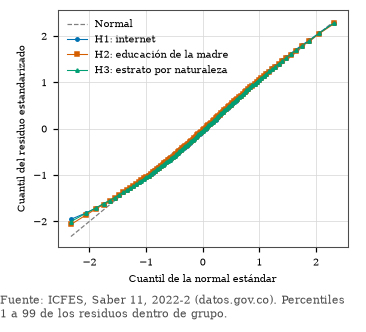

In [8]:
PROBABILIDADES = np.arange(1, 100) / 100


def residuos_dentro_de_grupo(valores: pd.Series, grupos: pd.Series) -> pd.Series:
    """Puntaje menos la media de su grupo, dividido por la desviación combinada (n menos k grados de libertad)."""
    residuo = valores - valores.groupby(grupos).transform("mean")
    return residuo / np.sqrt((residuo**2).sum() / (len(valores) - grupos.nunique()))


residuos_supuestos = {
    "H1: internet": residuos_dentro_de_grupo(y[en_h1], internet[en_h1]),
    "H2: educación de la madre": residuos_dentro_de_grupo(y[en_h2], educacion[en_h2]),
    "H3: estrato por naturaleza": residuos_dentro_de_grupo(y[en_h3], celda_h3),
}
forma = pd.DataFrame({
    nombre: {"Asimetría": stats.skew(r, bias=True), "Curtosis en exceso": stats.kurtosis(r, bias=True), "Percentil 1": np.quantile(r, 0.01), "Percentil 99": np.quantile(r, 0.99)}
    for nombre, r in residuos_supuestos.items()
}).T
tabla(forma, 3)
print(f"Normal estándar: percentiles 1 y 99 en ±{en_espanol(stats.norm.ppf(0.99), 3)}")

figura, eje = plt.subplots(figsize=(3.4, 2.8))
teoricos = stats.norm.ppf(PROBABILIDADES)
eje.plot([teoricos[0], teoricos[-1]], [teoricos[0], teoricos[-1]], color=graficos.COLOR_APOYO, linestyle="--", linewidth=0.8, label="Normal")
for (nombre, residuo), marcador in zip(residuos_supuestos.items(), ("o", "s", "^"), strict=True):
    eje.plot(teoricos, np.quantile(residuo, PROBABILIDADES), marker=marcador, markersize=2.2, linewidth=0.7, label=nombre)
eje.set(xlabel="Cuantil de la normal estándar", ylabel="Cuantil del residuo estandarizado")
eje.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje.legend(loc="upper left")
graficos.anotar_fuente(eje, f"{FUENTE} Percentiles 1 a 99 de los residuos dentro de grupo.")
figuras.guardar(figura, "supuestos-qq")
plt.show()
for nombre, sufijo in zip(residuos_supuestos, ("HUno", "HDos", "HTres"), strict=True):
    cifra(f"asimetria{sufijo}", forma.loc[nombre, "Asimetría"], 2)
    cifra(f"curtosis{sufijo}", forma.loc[nombre, "Curtosis en exceso"], 2)

**Lectura.** Las tres curvas se superponen y siguen la diagonal en el centro de la distribución; se apartan en las colas, que son más cortas que las de una normal, sobre todo la inferior: el percentil 1 de los residuos está cerca de -2,0, frente a -2,33 en la normal estándar. Eso coincide con una asimetría positiva leve (de 0,15 a 0,22) y una curtosis en exceso negativa (cerca de -0,4): el puntaje global está acotado y tiene colas más livianas que la normal. Con grupos de miles de estudiantes, esa forma no afecta la distribución de las medias ni la validez de t y F. Sí pesa la heterogeneidad de §2.2: Levene rechaza en las tres hipótesis, y en H3 la desviación de la celda más dispersa es 1,51 veces la de la menos dispersa. Por eso las pruebas principales son las que no suponen varianzas iguales (Welch, Games-Howell y HC3), con Kruskal-Wallis como contraste que no depende de la forma.

## 3. H1: internet en el hogar

La t de Welch compara la media del puntaje global de los estudiantes con internet en el hogar y sin él, sin suponer varianzas iguales (§2.2). La hipótesis es direccional, pero la prueba es bilateral: si la diferencia tiene el signo previsto, el p unilateral es la mitad del que se reporta. El efecto es la d de Cohen con la desviación combinada, con su intervalo analítico, y la diferencia de medias va en puntos con el intervalo de Welch. El faltante de internet es un tercer grupo descriptivo: no entra en la prueba, y su media se lee con el mecanismo de falta que midió la fase 2.

In [9]:
con_internet, sin_internet = (y[internet.eq(g)] for g in h1["grupos"])
contraste_h1 = hipotesis.welch(con_internet, sin_internet)
medias_h1 = hipotesis.medias_con_ic(y, internet.fillna(SIN_DATO)).reindex([*h1["grupos"], SIN_DATO])
tabla(medias_h1.rename(index=h1["etiquetas"]), 2)
print(
    f"\nt de Welch = {en_espanol(contraste_h1.estadistico, 2)} con {en_espanol(contraste_h1.gl[0], 1)} gl, p {texto_p(contraste_h1.p)}; "
    f"diferencia Sí menos No = {en_espanol(contraste_h1.detalle['diferencia'], 2)} puntos "
    f"(IC del 95 %: {en_espanol(contraste_h1.detalle['diferencia_inferior'], 2)} a {en_espanol(contraste_h1.detalle['diferencia_superior'], 2)}); "
    f"d de Cohen = {en_espanol(contraste_h1.valor, 3)} (IC del 95 %: {en_espanol(contraste_h1.ic[0], 3)} a {en_espanol(contraste_h1.ic[1], 3)})"
)
comprobar("H1 tiene el signo previsto: el puntaje medio es mayor con internet", contraste_h1.detalle["diferencia"] > 0 and contraste_h1.ic[0] > 0)
comprobar("La media sin dato de internet está más cerca de la del No que de la del Sí", abs(medias_h1.loc[SIN_DATO, "media"] - medias_h1.loc["No", "media"]) < abs(medias_h1.loc[SIN_DATO, "media"] - medias_h1.loc["Si", "media"]))
cifra("estadisticoHUno", contraste_h1.estadistico, 1)
cifra("glHUno", contraste_h1.gl[0], 0)
cifra("pHUno", texto_p(contraste_h1.p))
cifra("nHUno", contraste_h1.n)
cifra("efectoHUno", contraste_h1.valor, 3)
cifra("efectoInfHUno", contraste_h1.ic[0], 3)
cifra("efectoSupHUno", contraste_h1.ic[1], 3)
cifra("diferenciaHUno", contraste_h1.detalle["diferencia"], 1)
cifra("diferenciaInfHUno", contraste_h1.detalle["diferencia_inferior"], 1)
cifra("diferenciaSupHUno", contraste_h1.detalle["diferencia_superior"], 1)
for grupo, sufijo in (("Si", "Si"), ("No", "No"), (SIN_DATO, "SinDato")):
    cifra(f"mediaHUno{sufijo}", medias_h1.loc[grupo, "media"], 1)
    cifra(f"nHUno{sufijo}", int(medias_h1.loc[grupo, "n"]))
cifra("desviacionHUnoSi", medias_h1.loc["Si", "desviacion"], 1)
cifra("desviacionHUnoNo", medias_h1.loc["No", "desviacion"], 1)

                         n  media desviacion inferior superior
FAMI_TIENEINTERNET                                            
Sí                 363.657 260,15      51,56   259,99   260,32
No                 137.266 228,35      44,37   228,12   228,59
Sin dato            31.638 229,60      50,00   229,05   230,15

t de Welch = 216,12 con 284.889,4 gl, p < 0,001; diferencia Sí menos No = 31,80 puntos (IC del 95 %: 31,51 a 32,09); d de Cohen = 0,640 (IC del 95 %: 0,634 a 0,646)
[ok] H1 tiene el signo previsto: el puntaje medio es mayor con internet
[ok] La media sin dato de internet está más cerca de la del No que de la del Sí


'44,4'

**Lectura.** Los estudiantes con internet en el hogar obtienen en promedio 31,8 puntos más que quienes no lo tienen (IC del 95 %: 31,5 a 32,1), con una d de Cohen de 0,64, un efecto mediano; H1 se sostiene con el signo previsto. Es una asociación y no un efecto causal del internet: el acceso viaja con el estrato, la educación de los padres y la zona (H4), y en la regresión múltiple de la fase 2, con todo lo demás constante, la diferencia asociada a tener internet baja a unos 7 puntos. El grupo sin dato tiene una media de 229,6, a poco más de un punto del «No» y a más de 30 del «Sí», como encontró la fase 2 al estudiar el mecanismo de los faltantes; probarlo como tercera categoría habría mezclado ese mecanismo con el efecto.

## 4. H2: educación de la madre

La ANOVA de Welch (la de `oneway.test` en R) compara las medias de los diez niveles sin suponer varianzas iguales, y Kruskal-Wallis, con corrección por empates, compara sus distribuciones por rangos sin suponer normalidad. Los tamaños de efecto son η² (la proporción de la varianza del puntaje que separa a los grupos) y ε² (su análogo por rangos), con intervalos bootstrap percentil de 1.000 réplicas. Para saber qué niveles difieren, Tukey HSD compara los 45 pares con intervalos simultáneos (lo exige la paridad con R) y Games-Howell repite la comparación sin suponer varianzas iguales, que es lo que pide §2.2.

In [10]:
y_h2, g_h2 = y[en_h2].to_numpy(), educacion[en_h2].to_numpy()
welch_h2 = anova_welch(y_h2, g_h2)
kruskal_h2 = kruskal(y_h2, g_h2)
tukey_h2 = tukey(y[en_h2], educacion[en_h2], h2["niveles"])
games_howell_h2 = tukey(y[en_h2], educacion[en_h2], h2["niveles"], varianzas_iguales=False)
medias_h2 = hipotesis.medias_con_ic(y, educacion.fillna(SIN_DATO)).reindex([*h2["niveles"], *h2["descriptivos"], SIN_DATO])
tabla(medias_h2.rename(index=h2["etiquetas"]), 2)
for contraste in (welch_h2, kruskal_h2):
    print(
        f"\n{contraste.prueba}: {en_espanol(contraste.estadistico, 1)} con gl {' y '.join(en_espanol(g, 1) for g in contraste.gl)}, p {texto_p(contraste.p)}; "
        f"{contraste.efecto} = {en_espanol(contraste.valor, 4)} (IC del 95 %: {en_espanol(contraste.ic[0], 4)} a {en_espanol(contraste.ic[1], 4)})"
    )
pares = pd.DataFrame({
    "Tukey HSD": [(tukey_h2["p"] < ALFA).sum()],
    "Games-Howell": [(games_howell_h2["p"] < ALFA).sum()],
}, index=["Pares con p < 0,05"])
pares.loc["Pares en total"] = [len(tukey_h2), len(games_howell_h2)]
print()
print(pares.to_string())
comprobar("Tukey y Games-Howell comparan los mismos 45 pares con la misma diferencia de medias", len(tukey_h2) == len(games_howell_h2) == 45 and np.allclose(tukey_h2["diferencia"], games_howell_h2["diferencia"]))
comprobar("La media del puntaje sube con cada nivel de la escala", (np.diff(medias_h2.loc[h2["niveles"], "media"]) > 0).all())
cifra("estadisticoHDos", welch_h2.estadistico, 1)
cifra("glUnoHDos", welch_h2.gl[0], 0)
cifra("glDosHDos", welch_h2.gl[1], 0)
cifra("pHDos", texto_p(welch_h2.p))
cifra("nHDos", welch_h2.n)
cifra("efectoHDos", welch_h2.valor, 3)
cifra("efectoInfHDos", welch_h2.ic[0], 3)
cifra("efectoSupHDos", welch_h2.ic[1], 3)
cifra("estadisticoKruskal", kruskal_h2.estadistico, 0)
cifra("glKruskal", kruskal_h2.gl[0], 0)
cifra("pKruskal", texto_p(kruskal_h2.p))
cifra("efectoKruskal", kruskal_h2.valor, 3)
cifra("efectoInfKruskal", kruskal_h2.ic[0], 3)
cifra("efectoSupKruskal", kruskal_h2.ic[1], 3)
cifra("paresHDos", len(tukey_h2))
cifra("paresTukeySignificativos", int(pares.loc["Pares con p < 0,05", "Tukey HSD"]))
cifra("paresGamesHowellSignificativos", int(pares.loc["Pares con p < 0,05", "Games-Howell"]))
for nivel, sufijo in ((h2["niveles"][0], "Ninguno"), (h2["niveles"][-1], "Posgrado"), *((d, d.title().replace(" ", "")) for d in h2["descriptivos"]), (SIN_DATO, "SinDato")):
    cifra(f"mediaHDos{sufijo}", medias_h2.loc[nivel, "media"], 1)
cifra("diferenciaExtremosHDos", medias_h2.loc[h2["niveles"][-1], "media"] - medias_h2.loc[h2["niveles"][0], "media"], 1)

                          n  media desviacion inferior superior
FAMI_EDUCACIONMADRE                                            
Ninguno              10.258 211,19      41,51   210,38   211,99
Primaria inc.        62.853 228,85      43,06   228,51   229,19
Primaria comp.       42.105 233,43      45,49   233,00   233,87
Secundaria inc.      69.848 238,75      45,61   238,41   239,09
Secundaria comp.    143.664 249,38      48,28   249,13   249,63
Técnica inc.         17.972 259,87      47,54   259,18   260,57
Técnica comp.        52.269 267,99      48,32   267,58   268,41
Profesional inc.     15.207 271,70      51,52   270,88   272,52
Profesional comp.    62.291 278,39      54,00   277,96   278,81
Posgrado             11.369 307,50      54,07   306,51   308,50
No sabe              12.633 261,52      55,11   260,56   262,48
No aplica              1098 233,51      57,15   230,13   236,90
Sin dato             30.994 229,92      50,01   229,36   230,48

ANOVA de Welch: 8272,6 con gl 9,0 y 90.

'96,3'

La figura de medias pone las dos primeras hipótesis una sobre otra, con el mismo eje de puntaje. Cada punto es la media con su intervalo de confianza del 95 %, que con grupos de miles de estudiantes queda más angosto que el marcador; la barra gris clara, la media más o menos una desviación estándar, muestra cuánto se solapan los puntajes de grupos cuyas medias difieren con un p prácticamente nulo. Los grupos descriptivos van con marcador hueco y debajo de la línea punteada.

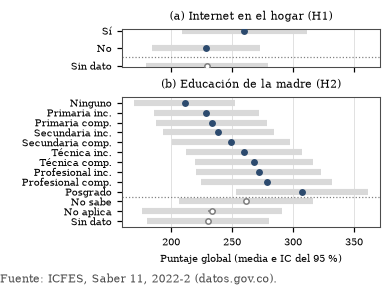

In [11]:
ESCALA_MEDIAS = "Puntaje global (media e IC del 95 %)"


def medias_matplotlib(eje: plt.Axes, medias: pd.DataFrame, etiquetas: dict, probados: list[str], titulo: str) -> None:
    """Medias con IC y una barra de más o menos una desviación, de arriba abajo en el orden de la tabla."""
    posiciones = np.arange(len(medias))[::-1]
    for posicion, (grupo, fila) in zip(posiciones, medias.iterrows(), strict=True):
        probado = grupo in probados
        color = graficos.COLOR_PRINCIPAL if probado else graficos.COLOR_APOYO
        eje.plot([fila["media"] - fila["desviacion"], fila["media"] + fila["desviacion"]], [posicion, posicion], color="#D9D9D9", linewidth=4, solid_capstyle="butt", zorder=1)
        eje.errorbar(fila["media"], posicion, xerr=[[fila["media"] - fila["inferior"]], [fila["superior"] - fila["media"]]], fmt="o", markersize=3.5, color=color, markerfacecolor=color if probado else "white", linewidth=1, zorder=3)
    eje.axhline(posiciones[len(probados) - 1] - 0.5, color=graficos.COLOR_APOYO, linestyle=":", linewidth=0.8)
    eje.set_yticks(posiciones, [etiquetas[g] for g in medias.index])
    eje.set(title=titulo)
    eje.xaxis.set_major_formatter(graficos.FORMATO_MILES)
    eje.grid(axis="y", visible=False)


# Los dos paneles, uno sobre otro y con el mismo eje de puntaje, caben en una columna del informe.
figura, (eje_h1, eje_h2) = plt.subplots(2, 1, figsize=(graficos.ANCHO_COLUMNA, 2.5), sharex=True, gridspec_kw={"height_ratios": [len(medias_h1) + 1.2, len(medias_h2) + 1.2]})
medias_matplotlib(eje_h1, medias_h1, h1["etiquetas"], h1["grupos"], "(a) Internet en el hogar (H1)")
medias_matplotlib(eje_h2, medias_h2, {**h2["etiquetas"], SIN_DATO: SIN_DATO}, h2["niveles"], "(b) Educación de la madre (H2)")
eje_h2.set_xlabel(ESCALA_MEDIAS)
figura.tight_layout(h_pad=0.6)
graficos.anotar_fuente(eje_h2, FUENTE)
figuras.guardar(figura, "medias-ic")
plt.show()

In [12]:
def medias_plotly(paneles: list[tuple[pd.DataFrame, dict, list[str], str]]) -> go.Figure:
    """Versión interactiva de la figura de medias: un panel por hipótesis, con n y desviación al pasar el cursor."""
    figura = make_subplots(rows=1, cols=len(paneles), subplot_titles=[titulo for *_, titulo in paneles], horizontal_spacing=0.18)
    for columna, (medias, etiquetas, probados, _) in enumerate(paneles, start=1):
        marco = medias.assign(etiqueta=[etiquetas[g] for g in medias.index], probado=[g in probados for g in medias.index])
        for probado, nombre in ((True, "Grupo de la prueba"), (False, "Grupo descriptivo")):
            parte = marco[marco["probado"].eq(probado)]
            figura.add_trace(go.Scatter(
                x=parte["media"], y=parte["etiqueta"], mode="markers", name=nombre, showlegend=columna == 1,
                marker={"color": graficos.COLOR_PRINCIPAL if probado else graficos.COLOR_APOYO, "size": 7, "symbol": "circle" if probado else "circle-open"},
                error_x={"type": "data", "array": parte["superior"] - parte["media"], "arrayminus": parte["media"] - parte["inferior"], "width": 0},
                customdata=parte[["n", "desviacion", "inferior", "superior"]],
                hovertemplate="%{y}: media %{x:.1f} (IC del 95 %: %{customdata[2]:.1f} a %{customdata[3]:.1f}); desviación %{customdata[1]:.1f}; %{customdata[0]:,.0f} estudiantes<extra></extra>",
            ), row=1, col=columna)
        figura.update_yaxes(categoryorder="array", categoryarray=marco["etiqueta"].tolist()[::-1], row=1, col=columna)
        figura.update_xaxes(title_text=ESCALA_MEDIAS, row=1, col=columna)
    figura.update_layout(template="simple_white", width=900, height=420, separators=",.", font={"family": "DejaVu Serif", "size": 13}, legend={"orientation": "h", "y": -0.25})
    return figura


guardar_plotly(medias_plotly([
    (medias_h1, h1["etiquetas"], h1["grupos"], "Internet en el hogar (H1)"),
    (medias_h2, {**h2["etiquetas"], SIN_DATO: SIN_DATO}, h2["niveles"], "Educación de la madre (H2)"),
]), "medias-ic")
print(f"Versión interactiva en {relativa(RUTA_INTERACTIVAS / 'medias-ic.html')}")

Versión interactiva en figuras/fase-3/interactivas/medias-ic.html


**Lectura.** En el panel (a), la diferencia entre «Sí» y «No» es enorme frente al intervalo de cada media, que no alcanza a verse, pero moderada frente a la dispersión: las barras de una desviación se solapan en buena parte, de modo que muchos estudiantes sin internet superan a muchos que lo tienen. Ese contraste entre significancia y relevancia es la razón para reportar el tamaño del efecto junto al valor p. En el panel (b) la media sube con cada nivel de educación de la madre, de 211,2 puntos con ninguna educación a 307,5 con posgrado, sin un solo retroceso. La ANOVA de Welch da un η² de 0,137 (IC del 95 %: 0,134 a 0,138): la educación de la madre, sola, separa cerca del 14 % de la varianza del puntaje, un efecto mediano en el límite de grande, y Kruskal-Wallis lo confirma por rangos (ε² de 0,128). Los grupos descriptivos no se ubican en la escala: «No sabe» tiene una media de 261,5, a la altura de la técnica incompleta, mientras que «No aplica» y el faltante quedan cerca de la primaria; tratarlos como niveles habría distorsionado la comparación.

La figura de Tukey muestra los nueve pares de niveles consecutivos, que responden a la pregunta práctica (¿cada nivel más de educación de la madre se asocia con un puntaje mayor?), con los intervalos simultáneos de Tukey y de Games-Howell uno junto al otro. Los 45 pares están en la tabla y en la versión interactiva.

                                          Tukey                           Games-Howell                          
                                     diferencia inferior superior       p   diferencia inferior superior       p
Ninguno → Primaria inc.                   17,66    16,05    19,28 < 0,001        17,66    16,26    19,07 < 0,001
Primaria inc. → Primaria comp.             4,59     3,63     5,54 < 0,001         4,59     3,70     5,47 < 0,001
Primaria comp. → Secundaria inc.           5,32     4,38     6,25 < 0,001         5,32     4,43     6,20 < 0,001
Secundaria inc. → Secundaria comp.        10,63     9,93    11,33 < 0,001        10,63     9,95    11,31 < 0,001
Secundaria comp. → Técnica inc.           10,49     9,29    11,69 < 0,001        10,49     9,30    11,69 < 0,001
Técnica inc. → Técnica comp.               8,12     6,81     9,43 < 0,001         8,12     6,81     9,42 < 0,001
Técnica comp. → Profesional inc.           3,71     2,31     5,10 < 0,001         3,71     2,22 

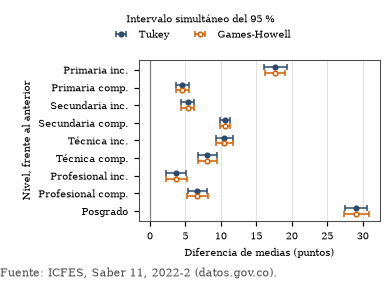

In [13]:
consecutivos = [(a, b) for a, b in zip(h2["niveles"], h2["niveles"][1:], strict=False)]


def pares_consecutivos(tabla_pares: pd.DataFrame) -> pd.DataFrame:
    return tabla_pares.set_index(["grupo_a", "grupo_b"]).loc[consecutivos]


comparacion_consecutivos = pd.concat({"Tukey": pares_consecutivos(tukey_h2), "Games-Howell": pares_consecutivos(games_howell_h2)}, axis=1)
etiqueta_par = {(a, b): f"{h2['etiquetas'][a]} → {h2['etiquetas'][b]}" for a, b in consecutivos}
vista_consecutivos = comparacion_consecutivos.set_axis([etiqueta_par[p] for p in consecutivos])
for metodo in ("Tukey", "Games-Howell"):
    vista_consecutivos[(metodo, "p")] = vista_consecutivos[(metodo, "p")].map(texto_p)
tabla(vista_consecutivos, 2)
comprobar("Los nueve pares consecutivos difieren con p < 0,05 en Tukey y en Games-Howell", (comparacion_consecutivos[[("Tukey", "p"), ("Games-Howell", "p")]] < ALFA).all().all())
salto_mayor = comparacion_consecutivos[("Tukey", "diferencia")].idxmax()
salto_menor = comparacion_consecutivos[("Tukey", "diferencia")].idxmin()
print(f"Mayor salto: {etiqueta_par[salto_mayor]}; menor: {etiqueta_par[salto_menor]}")
for nombre, par in (("Mayor", salto_mayor), ("Menor", salto_menor)):
    cifra(f"salto{nombre}HDos", comparacion_consecutivos.loc[par, ("Tukey", "diferencia")], 1)
    cifra(f"saltoInf{nombre}HDos", comparacion_consecutivos.loc[par, ("Games-Howell", "inferior")], 1)
    cifra(f"saltoSup{nombre}HDos", comparacion_consecutivos.loc[par, ("Games-Howell", "superior")], 1)
    cifra(f"salto{nombre}Desde", h2["etiquetas"][par[0]])
    cifra(f"salto{nombre}Hasta", h2["etiquetas"][par[1]])

ESCALA_TUKEY = "Diferencia de medias (puntos), intervalo simultáneo del 95 %"
figura, eje = plt.subplots(figsize=(graficos.ANCHO_COLUMNA, 2.0))
posiciones = np.arange(len(consecutivos))[::-1]
for desplazamiento, (metodo, color, relleno) in zip((0.16, -0.16), (("Tukey", graficos.COLOR_PRINCIPAL, True), ("Games-Howell", graficos.PALETA_CATEGORICA[1], False)), strict=True):
    parte = comparacion_consecutivos[metodo]
    eje.errorbar(
        parte["diferencia"], posiciones + desplazamiento, xerr=[parte["diferencia"] - parte["inferior"], parte["superior"] - parte["diferencia"]],
        fmt="o", markersize=3, color=color, markerfacecolor=color if relleno else "white", linewidth=1, capsize=2, label=metodo,
    )
eje.axvline(0, color=graficos.COLOR_APOYO, linewidth=0.8)
# Cada fila es un nivel frente al anterior: el nombre del nivel basta y cabe en la columna del informe.
eje.set_yticks(posiciones, [h2["etiquetas"][b] for _, b in consecutivos])
eje.set(xlabel="Diferencia de medias (puntos)", ylabel="Nivel, frente al anterior")
eje.xaxis.set_major_formatter(graficos.FORMATO_MILES)
eje.grid(axis="y", visible=False)
figura.tight_layout()
figura.legend(*eje.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, title="Intervalo simultáneo del 95 %")
graficos.anotar_fuente(eje, FUENTE)
figuras.guardar(figura, "tukey-h2")
plt.show()

In [14]:
def tukey_plotly(metodos: dict[str, pd.DataFrame], etiquetas: dict) -> go.Figure:
    """Los 45 pares con los intervalos de Tukey y de Games-Howell, con el p ajustado al pasar el cursor."""
    figura = go.Figure()
    for (metodo, pares_), color in zip(metodos.items(), (graficos.COLOR_PRINCIPAL, graficos.PALETA_CATEGORICA[1]), strict=True):
        etiquetas_par = [f"{etiquetas[a]} → {etiquetas[b]}" for a, b in zip(pares_["grupo_a"], pares_["grupo_b"], strict=True)]
        figura.add_trace(go.Scatter(
            x=pares_["diferencia"], y=etiquetas_par, orientation="h", mode="markers", name=metodo, marker={"color": color, "size": 6},
            error_x={"type": "data", "array": pares_["superior"] - pares_["diferencia"], "arrayminus": pares_["diferencia"] - pares_["inferior"], "width": 0},
            customdata=pares_[["inferior", "superior", "p"]],
            hovertemplate="%{y}: %{x:.1f} puntos (%{customdata[0]:.1f} a %{customdata[1]:.1f}); p ajustado %{customdata[2]:.2g}<extra>" + metodo + "</extra>",
        ))
    figura.add_vline(x=0, line={"color": graficos.COLOR_APOYO, "width": 1})
    figura.update_layout(
        template="simple_white", width=760, height=1000, separators=",.", font={"family": "DejaVu Serif", "size": 12}, scattermode="group",
        xaxis={"title": ESCALA_TUKEY, "showgrid": True}, yaxis={"autorange": "reversed"}, legend={"orientation": "h", "y": -0.06},
    )
    return figura


guardar_plotly(tukey_plotly({"Tukey": tukey_h2, "Games-Howell": games_howell_h2}, h2["etiquetas"]), "tukey-h2")
print(f"Versión interactiva en {relativa(RUTA_INTERACTIVAS / 'tukey-h2.html')}")

Versión interactiva en figuras/fase-3/interactivas/tukey-h2.html


**Lectura.** Los nueve saltos entre niveles consecutivos son positivos y ningún intervalo simultáneo toca el cero, ni con Tukey ni con Games-Howell, y los 45 pares difieren con los dos métodos. La diferencia de medias es la misma en ambos; Games-Howell ensancha el intervalo donde un grupo es más disperso que el promedio (el posgrado y la educación profesional) y lo angosta donde es menos disperso (ninguna educación), así que la conclusión no depende de suponer varianzas iguales. La escalera no es pareja: los saltos mayores están en el posgrado (29,1 puntos sobre la profesional completa), en tener alguna primaria frente a ninguna (17,7) y en terminar el bachillerato y empezar estudios técnicos (cerca de 10,5 cada uno); el menor, de 3,7 puntos, es el paso de la técnica completa a la profesional incompleta. Para un colegio o una secretaría de educación, el nivel educativo de la madre es un marcador fuerte del punto de partida de cada estudiante, útil para focalizar el acompañamiento, aunque la prueba no separa su efecto del de los demás rasgos del hogar.

## 5. H3: brecha entre colegios oficiales y no oficiales por estrato

El modelo es una ANOVA de dos vías con interacción, `puntaje ~ estrato * naturaleza`, con sumas de cuadrados tipo II, que no dependen del orden de los factores en un diseño desbalanceado como este. Como las varianzas difieren entre celdas (§2.2), cada F se reporta también con la matriz de covarianzas robusta HC3 (`anova_lm(typ=2, robust="hc3")`, la misma de `car::Anova(type = 2, white.adjust = "hc3")` en R). El efecto es el η² parcial de cada término, con intervalo bootstrap. La hipótesis se lee en dos partes: el término de naturaleza dice si hay brecha una vez descontado el estrato, y la interacción dice si su tamaño cambia de un estrato a otro; los efectos simples (la brecha dentro de cada estrato, con Welch y su intervalo) muestran si se mantiene en todos.

In [15]:
datos_h3 = pd.DataFrame({"y": y[en_h3], "estrato": estrato[en_h3], "naturaleza": naturaleza[en_h3]})
dos_vias_h3 = dos_vias(datos_h3["y"], datos_h3["estrato"], datos_h3["naturaleza"]).set_index("termino")
tabla(dos_vias_h3.drop(columns=["p", "p_hc3"]).assign(p=dos_vias_h3["p"].map(texto_p), p_hc3=dos_vias_h3["p_hc3"].map(texto_p)), 4)
NIVEL, REFERENCIA = h3["niveles_b"][1], h3["niveles_b"][0]
efectos_h3 = hipotesis.efectos_simples(datos_h3["y"], datos_h3["estrato"], datos_h3["naturaleza"], NIVEL, REFERENCIA).set_index("estrato").reindex(h3["niveles_a"])
print(f"\nEfectos simples: {h3['etiquetas_b'][NIVEL]} menos {h3['etiquetas_b'][REFERENCIA]} dentro de cada estrato")
tabla(efectos_h3.drop(columns="p").assign(p=efectos_h3["p"].map(texto_p)), 2)
medias_h3 = hipotesis.medias_con_ic(datos_h3["y"], datos_h3[["estrato", "naturaleza"]])
comprobar("Las 14 celdas de estrato por naturaleza tienen 10 o más estudiantes", len(medias_h3) == 14 and medias_h3["n"].min() >= 10)
comprobar("La tabla tipo II tiene los tres términos con su F clásica y con HC3", list(dos_vias_h3.index) == ["estrato", "naturaleza", "estrato:naturaleza"] and dos_vias_h3[["F", "F_hc3"]].notna().all().all())
comprobar("La brecha a favor de los no oficiales es positiva en los siete grupos de estrato, con todo su intervalo sobre cero", (efectos_h3["inferior"] > 0).all())
comprobar("La brecha crece con cada estrato, del 1 al 6", (np.diff(efectos_h3.loc[list(v.ESTRATOS), "diferencia"]) > 0).all())
oficiales = medias_h3.xs(REFERENCIA, level="naturaleza")["media"]
comprobar("En los colegios oficiales, la media del estrato 6 queda por debajo de la del estrato 1", oficiales[v.ESTRATOS[-1]] < oficiales[v.ESTRATOS[0]])

SUFIJO_ESTRATO = {**{f"Estrato {n}": f"Estrato{nombre}" for n, nombre in enumerate(("Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis"), start=1)}, limpieza.SIN_ESTRATO: "SinEstrato"}
for termino, sufijo in (("naturaleza", "HTres"), ("estrato:naturaleza", "HTresInteraccion"), ("estrato", "HTresEstrato")):
    fila = dos_vias_h3.loc[termino]
    cifra(f"estadistico{sufijo}", fila["F_hc3"], 1)
    cifra(f"estadisticoClasico{sufijo}", fila["F"], 1)
    cifra(f"gl{sufijo}", fila["gl"], 0)
    cifra(f"p{sufijo}", texto_p(fila["p_hc3"]))
    cifra(f"efecto{sufijo}", fila["eta_parcial"], 3)
    cifra(f"efectoInf{sufijo}", fila["inferior"], 3)
    cifra(f"efectoSup{sufijo}", fila["superior"], 3)
cifra("glResidualHTres", dos_vias_h3["gl_residual"].iloc[0], 0)
cifra("nHTres", len(datos_h3))
cifra("pctEstratoUnoHTres", 100 * datos_h3["estrato"].eq(v.ESTRATOS[0]).mean(), 1)
for (nivel_estrato, naturaleza_), fila in medias_h3.iterrows():
    cifra(f"mediaHTres{h3['etiquetas_b'][naturaleza_].title().replace(' ', '')}{SUFIJO_ESTRATO[nivel_estrato]}", fila["media"], 1)
for nivel_estrato, fila in efectos_h3.iterrows():
    sufijo = SUFIJO_ESTRATO[nivel_estrato]
    cifra(f"brecha{sufijo}", fila["diferencia"], 1)
    cifra(f"brechaInf{sufijo}", fila["inferior"], 1)
    cifra(f"brechaSup{sufijo}", fila["superior"], 1)
    cifra(f"dBrecha{sufijo}", fila["d"], 2)

                    suma_cuadrados gl gl_residual           F       F_hc3 eta_parcial inferior superior       p   p_hc3
termino                                                                                                                
estrato            41.618.820,1986  6     496.655   2921,3704   3461,7090      0,0341   0,0331   0,0351 < 0,001 < 0,001
naturaleza         50.106.732,4632  1     496.655 21.102,9994 18.195,0327      0,0408   0,0395   0,0420 < 0,001 < 0,001
estrato:naturaleza 31.084.546,9027  6     496.655   2181,9329   1852,0480      0,0257   0,0247   0,0266 < 0,001 < 0,001



Efectos simples: No oficial menos Oficial dentro de cada estrato
                  n diferencia inferior superior     t        gl    d d_inferior d_superior       p
estrato                                                                                            
Estrato 1   146.261       4,53     3,66     5,40 10,18 18.265,68 0,10       0,08       0,11 < 0,001
Estrato 2   180.019      15,38    14,78    15,99 49,52 49.161,40 0,32       0,31       0,33 < 0,001
Estrato 3   110.215      29,66    29,03    30,30 91,76 78.039,66 0,59       0,57       0,60 < 0,001
Estrato 4    28.080      63,97    62,72    65,22 99,98 27.795,57 1,19       1,17       1,22 < 0,001
Estrato 5      8445      83,74    81,52    85,96 73,94   8411,44 1,58       1,54       1,63 < 0,001
Estrato 6      3879      91,42    87,95    94,89 51,64   2933,91 1,74       1,66       1,81 < 0,001
Sin Estrato  19.770      18,43    15,91    20,95 14,32   2230,30 0,43       0,38       0,47 < 0,001
[ok] Las 14 celdas de estrato por 

La interacción se dibuja en Plotly: la media de cada celda con su intervalo, una línea por naturaleza del colegio y el estrato en el eje horizontal. Si las líneas fueran paralelas, la brecha sería la misma en cada estrato. La versión interactiva muestra el n y el intervalo de cada celda; la estática es la que va al informe.

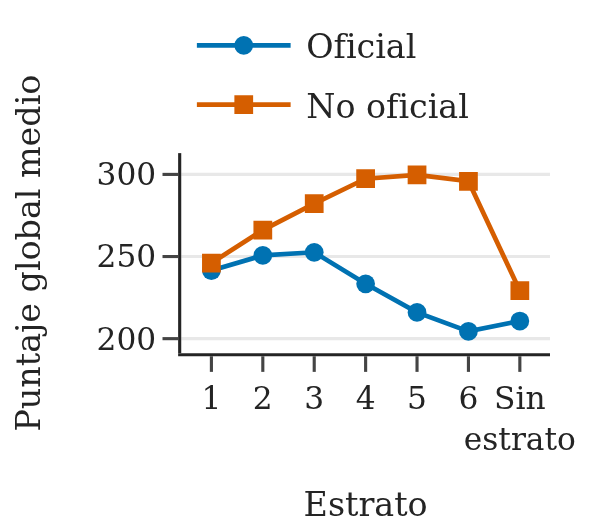

Versión interactiva en figuras/fase-3/interactivas/interaccion-h3.html


In [16]:
# Tamaño de un panel de la comparación de herramientas del informe (§20), cuatro por fila en el ancho de
# la página; el mismo en el script de R. La letra va en píxeles de Plotly (96 por pulgada): 8 y 7,5 puntos; los
# títulos de los ejes la fijan aparte, porque Plotly los agranda por defecto.
TAMANO_INTERACCION = (2.0, 1.75)
LETRA_PLOTLY = {"family": "DejaVu Serif", "size": 8 * graficos.PUNTOS_POR_PULGADA_PLOTLY / 72}
MARCAS_PLOTLY = {"size": 7.5 * graficos.PUNTOS_POR_PULGADA_PLOTLY / 72}
COLORES_NATURALEZA = {REFERENCIA: graficos.COLOR_OFICIAL, NIVEL: graficos.COLOR_NO_OFICIAL}


def interaccion_plotly(medias: pd.DataFrame) -> go.Figure:
    """Media del puntaje por estrato y naturaleza con su IC del 95 %, una línea por naturaleza."""
    figura = go.Figure()
    for naturaleza_, simbolo in zip(h3["niveles_b"], ("circle", "square"), strict=True):
        celdas = medias.xs(naturaleza_, level="naturaleza").reindex(h3["niveles_a"])
        figura.add_trace(go.Scatter(
            x=[h3["etiquetas_a"][e].replace(" ", "<br>") for e in celdas.index], y=celdas["media"], mode="lines+markers", name=h3["etiquetas_b"][naturaleza_],
            line={"color": COLORES_NATURALEZA[naturaleza_], "width": 1.5}, marker={"symbol": simbolo, "size": 6},
            error_y={"type": "data", "array": celdas["superior"] - celdas["media"], "arrayminus": celdas["media"] - celdas["inferior"], "width": 2, "thickness": 1},
            customdata=celdas[["n", "inferior", "superior"]],
            hovertemplate="%{x}: media %{y:.1f} (IC del 95 %: %{customdata[1]:.1f} a %{customdata[2]:.1f}); %{customdata[0]:,.0f} estudiantes<extra>%{fullData.name}</extra>",
        ))
    figura.update_layout(
        template="simple_white", width=TAMANO_INTERACCION[0] * graficos.PUNTOS_POR_PULGADA_PLOTLY, height=TAMANO_INTERACCION[1] * graficos.PUNTOS_POR_PULGADA_PLOTLY,
        xaxis={"title": {"text": "Estrato", "font": LETRA_PLOTLY}, "tickfont": MARCAS_PLOTLY, "tickangle": 0}, yaxis={"title": {"text": "Puntaje global medio", "font": LETRA_PLOTLY}, "showgrid": True, "tickfont": MARCAS_PLOTLY},
        separators=",.", font=LETRA_PLOTLY, margin={"l": 8, "r": 8, "t": 8, "b": 8}, legend={"orientation": "h", "x": 0, "y": 1.02, "yanchor": "bottom"},
    )
    return figura


guardar_plotly(interaccion_plotly(medias_h3), "interaccion-h3", png=True)
display(Image(filename=RUTA_FIGURAS / "interaccion-h3.png", width=420))
print(f"Versión interactiva en {relativa(RUTA_INTERACTIVAS / 'interaccion-h3.html')}")

**Lectura.** La brecha a favor de los colegios no oficiales aparece en los siete grupos de estrato, así que H3 se sostiene en su signo, pero no en su tamaño: la interacción es significativa (F con HC3 de 1852 con 6 y 496.655 grados de libertad) y la brecha crece con el estrato, de 4,5 puntos en el estrato 1 (d = 0,10) a 64,0 en el 4 y 91,4 en el 6 (d = 1,74); en los hogares sin estrato es de 18,4. La figura muestra por qué: la media de los no oficiales sube con el estrato hasta cerca de 300 puntos, mientras que la de los oficiales sube hasta el estrato 3 y luego baja, hasta quedar en el estrato 6 por debajo del estrato 1. Esa caída es la que la fase 1 trató como hipótesis de un cambio en el registro del estrato en los colegios oficiales desde 2017-2, no como un deterioro real, y obliga a leer con cautela la brecha de los estratos altos. Los η² parciales son pequeños (0,041 para la naturaleza y 0,026 para la interacción) porque los estratos altos tienen pocos estudiantes: en el estrato 1, que reúne a casi tres de cada diez estudiantes con estrato registrado, el tipo de colegio casi no cambia el puntaje. Para una secretaría de educación, la ventaja del colegio no oficial no es uniforme: entre los hogares de menos recursos los dos tipos de colegio rinden casi igual, y la diferencia se abre donde el hogar tiene más.

## 6. H4: estrato y naturaleza; internet y zona

La fase 1 ya rechazó la independencia en las dos tablas con la χ² de Pearson sin corrección de Yates y la V de Cramér sin corrección de sesgo. Aquí se vuelve a plantear como prueba formal sobre el marco de §2 (sin las cinco filas excluidas por la fase 2), con el intervalo bootstrap de la V (la tabla se remuestrea con una multinomial) y con los residuos estandarizados ajustados de cada celda, que dicen dónde está la dependencia: un residuo por encima de 2 o por debajo de -2 marca una celda con más o menos estudiantes de los que habría si las dos variables fueran independientes.

In [17]:
tablas_h4 = {
    nombre: pd.crosstab(hip[marco_["filas"]], hip[marco_["columnas"]]).reindex(index=marco_["niveles_filas"], columns=marco_["niveles_columnas"])
    for nombre, marco_ in h4.items()
}
contrastes_h4 = {nombre: chi_cuadrado(tabla_) for nombre, tabla_ in tablas_h4.items()}
residuos_h4 = {nombre: hipotesis.residuos_estandarizados(tabla_) for nombre, tabla_ in tablas_h4.items()}
for nombre, tabla_ in tablas_h4.items():
    contraste = contrastes_h4[nombre]
    print(f"\n{nombre}: χ² = {en_espanol(contraste.estadistico, 1)} con {en_espanol(contraste.gl[0])} gl, p {texto_p(contraste.p)}, n = {en_espanol(contraste.n)}; "
          f"V de Cramér = {en_espanol(contraste.valor, 4)} (IC del 95 %: {en_espanol(contraste.ic[0], 4)} a {en_espanol(contraste.ic[1], 4)})")
    tabla(pd.concat({"Estudiantes": tabla_, "Residuo ajustado": residuos_h4[nombre]}, axis=1), 1)
    comprobar(f"La tabla {nombre} no tiene celdas de menos de 10 estudiantes", tabla_.to_numpy().min() >= 10)
    comprobar(f"La tabla {nombre} tiene frecuencias esperadas de 5 o más", contraste.detalle["esperada_minima"] >= 5)

# La fase 1 probó lo mismo sobre el recorte completo: se reproducen sus cifras y se cuentan las filas que cambian.
fase_1 = json.loads((RUTA_RESULTADOS / "cifras-fase-1.json").read_text(encoding="utf-8"))
recorte_fase_1 = recorte.assign(**{v.ESTRATO: recorte[v.ESTRATO].replace(limpieza.FRASE_RURAL, limpieza.SIN_ESTRATO)})
comparacion_fase_1 = []
for nombre, sufijo in (("estrato_naturaleza", "EstratoNaturaleza"), ("internet_zona", "InternetZona")):
    marco_ = h4[nombre]
    tabla_fase_1 = pd.crosstab(recorte_fase_1[marco_["filas"]], recorte_fase_1[marco_["columnas"]]).reindex(index=marco_["niveles_filas"], columns=marco_["niveles_columnas"])
    chi_fase_1 = stats.chi2_contingency(tabla_fase_1.to_numpy(), correction=False).statistic
    comprobar(f"Se reproducen el n y la χ² de {nombre} de la fase 1", tabla_fase_1.to_numpy().sum() == fase_1[f"n{sufijo}"]["valor"] and abs(chi_fase_1 / fase_1[f"chiDos{sufijo}"]["valor"] - 1) < 1e-9)
    comparacion_fase_1.append({
        "Tabla": nombre, "n fase 1": fase_1[f"n{sufijo}"]["valor"], "n fase 3": contrastes_h4[nombre].n,
        "Filas excluidas en la tabla": fase_1[f"n{sufijo}"]["valor"] - contrastes_h4[nombre].n,
        "V fase 1": fase_1[f"vCramer{sufijo}"]["valor"], "V fase 3": contrastes_h4[nombre].valor,
    })
comparacion_fase_1 = pd.DataFrame(comparacion_fase_1).set_index("Tabla")
print()
tabla(comparacion_fase_1, 4)
comprobar(
    f"Las tablas de la fase 3 pierden a lo sumo las {en_espanol(int(tabla_exclusiones['Filas'].sum()))} filas excluidas",
    comparacion_fase_1["Filas excluidas en la tabla"].between(0, tabla_exclusiones["Filas"].sum()).all(),
)

for nombre, sufijo in (("estrato_naturaleza", "HCuatroEstrato"), ("internet_zona", "HCuatroInternet")):
    contraste = contrastes_h4[nombre]
    cifra(f"estadistico{sufijo}", contraste.estadistico, 0)
    cifra(f"gl{sufijo}", contraste.gl[0], 0)
    cifra(f"p{sufijo}", texto_p(contraste.p))
    cifra(f"n{sufijo}", contraste.n)
    cifra(f"efecto{sufijo}", contraste.valor, 3)
    cifra(f"efectoInf{sufijo}", contraste.ic[0], 3)
    cifra(f"efectoSup{sufijo}", contraste.ic[1], 3)
    cifra(f"filasExcluidas{sufijo}", int(comparacion_fase_1.loc[nombre, "Filas excluidas en la tabla"]))


estrato_naturaleza: χ² = 46.630,7 con 6 gl, p < 0,001, n = 496.669; V de Cramér = 0,3064 (IC del 95 %: 0,3037 a 0,3092)
                     Estudiantes            Residuo ajustado           
COLE_NATURALEZA          OFICIAL NO OFICIAL          OFICIAL NO OFICIAL
FAMI_ESTRATOVIVIENDA                                                   
Estrato 1                130.863     15.398            133,1     -133,1
Estrato 2                144.954     35.065             41,9      -41,9
Estrato 3                 70.704     39.511           -117,2      117,2
Estrato 4                 13.157     14.923           -124,8      124,8
Estrato 5                   3864       4581            -69,5       69,5
Estrato 6                   2152       1727            -32,4       32,4
Sin Estrato               17.790       1980             43,7      -43,7
[ok] La tabla estrato_naturaleza no tiene celdas de menos de 10 estudiantes
[ok] La tabla estrato_naturaleza tiene frecuencias esperadas de 5 o más

internet_z

Los residuos se dibujan en Seaborn como mapas de calor divergentes, con el cero en blanco, el valor de cada celda escrito y la misma escala de color en las dos tablas.

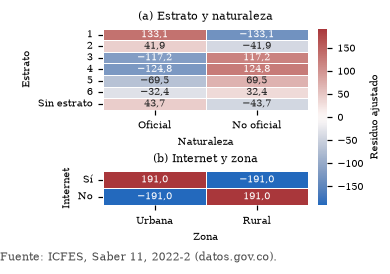

Versión interactiva en figuras/fase-3/interactivas/residuos-h4.html


In [18]:
ETIQUETAS_H4 = {
    "estrato_naturaleza": ({**h3["etiquetas_a"]}, h3["etiquetas_b"], "Estrato", "Naturaleza", "(a) Estrato y naturaleza"),
    "internet_zona": (h1["etiquetas"], {"URBANO": "Urbana", "RURAL": "Rural"}, "Internet", "Zona", "(b) Internet y zona"),
}
limite_color = max(np.abs(r.to_numpy()).max() for r in residuos_h4.values())
# Las dos tablas, una sobre otra, ocupan el ancho de la columna; la barra de color, común, va en un eje propio.
figura = plt.figure(figsize=(graficos.ANCHO_COLUMNA, 2.3))
malla_h4 = figura.add_gridspec(2, 2, width_ratios=[1, 0.04], height_ratios=[len(r) + 1.6 for r in residuos_h4.values()])
ejes = [figura.add_subplot(malla_h4[i, 0]) for i in range(len(residuos_h4))]
eje_barra = figura.add_subplot(malla_h4[:, 1])
for eje, (nombre, residuos_) in zip(ejes, residuos_h4.items(), strict=True):
    filas_, columnas_, nombre_filas, nombre_columnas, titulo = ETIQUETAS_H4[nombre]
    anotaciones = residuos_.map(lambda r: graficos.con_signo_menos(en_espanol(r, 1)))
    sns.heatmap(
        residuos_.rename(index=filas_, columns=columnas_), annot=anotaciones.to_numpy(), fmt="", cmap="vlag", center=0, vmin=-limite_color, vmax=limite_color,
        linewidths=0.5, linecolor="white", cbar=eje is ejes[-1], cbar_ax=eje_barra, cbar_kws={"label": "Residuo ajustado", "format": graficos.FORMATO_MILES}, annot_kws={"size": 6.5}, ax=eje,
    )
    eje.set(xlabel=nombre_columnas, ylabel=nombre_filas, title=titulo)
    eje.tick_params(axis="y", rotation=0)
figura.tight_layout(h_pad=0.6)
graficos.anotar_fuente(ejes[-1], FUENTE)
figuras.guardar(figura, "residuos-h4")
plt.show()


def residuos_plotly(residuos: dict[str, pd.DataFrame], conteos: dict[str, pd.DataFrame]) -> go.Figure:
    """Residuos ajustados de las dos tablas, con el número de estudiantes de cada celda al pasar el cursor."""
    figura = make_subplots(rows=1, cols=len(residuos), subplot_titles=[ETIQUETAS_H4[n][4] for n in residuos], horizontal_spacing=0.2)
    for columna, (nombre, residuos_) in enumerate(residuos.items(), start=1):
        filas_, columnas_, nombre_filas, nombre_columnas, _ = ETIQUETAS_H4[nombre]
        figura.add_trace(go.Heatmap(
            z=residuos_.to_numpy(), x=[columnas_[c] for c in residuos_.columns], y=[filas_[f] for f in residuos_.index], customdata=conteos[nombre].to_numpy(),
            zmid=0, zmin=-limite_color, zmax=limite_color, colorscale="RdBu_r", showscale=columna == len(residuos), texttemplate="%{z:.1f}",
            colorbar={"title": {"text": "Residuo ajustado", "side": "right"}},
            hovertemplate=nombre_filas + " %{y}, " + nombre_columnas.lower() + " %{x}: residuo %{z:.1f}; %{customdata:,.0f} estudiantes<extra></extra>",
        ), row=1, col=columna)
        figura.update_yaxes(autorange="reversed", title_text=nombre_filas, row=1, col=columna)
        figura.update_xaxes(title_text=nombre_columnas, row=1, col=columna)
    figura.update_layout(template="simple_white", width=820, height=420, separators=",.", font={"family": "DejaVu Serif", "size": 13})
    return figura


guardar_plotly(residuos_plotly(residuos_h4, tablas_h4), "residuos-h4")
print(f"Versión interactiva en {relativa(RUTA_INTERACTIVAS / 'residuos-h4.html')}")

**Lectura.** Las dos tablas son exactamente las de la fase 1: ninguna de las cinco filas excluidas tenía registradas las dos variables de alguna de ellas, así que el n, la χ² y la V no cambian. La V de Cramér de estrato y naturaleza es 0,306 (IC del 95 %: 0,304 a 0,309), una asociación mediana, y la de internet y zona es 0,270 (0,267 a 0,273), pequeña pero cerca de mediana. Los residuos muestran dónde está la dependencia: el estrato 1 y, en menor medida, el 2 y los hogares sin estrato tienen muchos más estudiantes en colegios oficiales de los que habría con independencia (residuos de 133,1, 41,9 y 43,7), mientras que los estratos 3 a 6 se cargan hacia los no oficiales, con el máximo en el 4 (124,8). En la otra tabla, las sedes rurales tienen muchos más estudiantes sin internet en el hogar de los esperados (residuo de 191,0). Para el MinTIC y las secretarías, la brecha de conectividad del hogar sigue siendo rural; y como el estrato decide en buena parte a qué tipo de colegio asiste un estudiante, la brecha entre oficiales y no oficiales tiene que leerse dentro de cada estrato, como en H3, y no en bruto.

## 7. Corrección de Holm y resumen de efectos

Las pruebas principales forman una familia de seis: la t de Welch de H1, la ANOVA de Welch de H2, los términos de naturaleza y de interacción de H3 (con HC3) y las dos χ² de H4. Kruskal-Wallis, Tukey, Games-Howell y los efectos simples son comprobaciones de robustez y de detalle, fuera de la familia. La corrección de Holm controla la probabilidad de cometer al menos un error de tipo I en la familia sin la pérdida de potencia de Bonferroni. Cada efecto se gradúa con los umbrales convencionales de Cohen (1988): 0,2, 0,5 y 0,8 para la d; 0,01, 0,06 y 0,14 para η², ε² y η² parcial, y 0,1, 0,3 y 0,5 para la V con un grado de libertad mínimo, que es el caso de las dos tablas.

In [19]:
UMBRALES_COHEN = {"d de Cohen": (0.2, 0.5, 0.8), "η²": (0.01, 0.06, 0.14), "ε²": (0.01, 0.06, 0.14), "η² parcial": (0.01, 0.06, 0.14), "V de Cramér": (0.1, 0.3, 0.5)}
MAGNITUDES = ("trivial", "pequeño", "mediano", "grande")


def magnitud(efecto: str, valor: float) -> str:
    return MAGNITUDES[int(np.searchsorted(UMBRALES_COHEN[efecto], abs(valor), side="right"))]


def fila_resumen(hipotesis_: str, prueba: str, estadistico: float, gl: str, p: float, efecto: str, valor: float, ic: tuple[float, float], n: int) -> dict:
    return {"Hipótesis": hipotesis_, "Prueba": prueba, "Estadístico": estadistico, "gl": gl, "p": p, "Efecto": efecto, "Valor": valor, "IC inferior": ic[0], "IC superior": ic[1], "n": n}


def gl_texto(*gl: float) -> str:
    return " y ".join(en_espanol(g, 0) for g in gl)


familia = []
familia.append(fila_resumen("H1", "t de Welch", contraste_h1.estadistico, gl_texto(*contraste_h1.gl), contraste_h1.p, contraste_h1.efecto, contraste_h1.valor, contraste_h1.ic, contraste_h1.n))
familia.append(fila_resumen("H2", "F de Welch", welch_h2.estadistico, gl_texto(*welch_h2.gl), welch_h2.p, welch_h2.efecto, welch_h2.valor, welch_h2.ic, welch_h2.n))
for termino, nombre in (("naturaleza", "H3: naturaleza"), ("estrato:naturaleza", "H3: interacción")):
    fila = dos_vias_h3.loc[termino]
    familia.append(fila_resumen(nombre, "F tipo II con HC3", fila["F_hc3"], gl_texto(fila["gl"], fila["gl_residual"]), fila["p_hc3"], "η² parcial", fila["eta_parcial"], (fila["inferior"], fila["superior"]), len(datos_h3)))
for nombre, etiqueta in (("estrato_naturaleza", "H4: estrato y naturaleza"), ("internet_zona", "H4: internet y zona")):
    contraste = contrastes_h4[nombre]
    familia.append(fila_resumen(etiqueta, "χ²", contraste.estadistico, gl_texto(*contraste.gl), contraste.p, contraste.efecto, contraste.valor, contraste.ic, contraste.n))
resumen_efectos = pd.DataFrame(familia).set_index("Hipótesis")
rechaza, p_holm, *_ = multipletests(resumen_efectos["p"], alpha=ALFA, method="holm")
resumen_efectos.insert(resumen_efectos.columns.get_loc("p") + 1, "p de Holm", p_holm)
resumen_efectos["Magnitud"] = [magnitud(e, valor) for e, valor in zip(resumen_efectos["Efecto"], resumen_efectos["Valor"], strict=True)]
robustez = pd.DataFrame([
    fila_resumen("H2 (robustez)", "H de Kruskal-Wallis", kruskal_h2.estadistico, gl_texto(*kruskal_h2.gl), kruskal_h2.p, kruskal_h2.efecto, kruskal_h2.valor, kruskal_h2.ic, kruskal_h2.n),
    fila_resumen("H3: estrato", "F tipo II con HC3", dos_vias_h3.loc["estrato", "F_hc3"], gl_texto(dos_vias_h3.loc["estrato", "gl"], dos_vias_h3.loc["estrato", "gl_residual"]), dos_vias_h3.loc["estrato", "p_hc3"], "η² parcial", dos_vias_h3.loc["estrato", "eta_parcial"], (dos_vias_h3.loc["estrato", "inferior"], dos_vias_h3.loc["estrato", "superior"]), len(datos_h3)),
]).set_index("Hipótesis")
robustez["Magnitud"] = [magnitud(e, valor) for e, valor in zip(robustez["Efecto"], robustez["Valor"], strict=True)]
resumen_completo = pd.concat([resumen_efectos, robustez])
tabla(resumen_completo.assign(**{c: resumen_completo[c].map(lambda p: texto_p(p) if pd.notna(p) else "") for c in ("p", "p de Holm")}), 3)
comprobar("La familia tiene las seis pruebas principales y cada una su efecto con IC bootstrap o analítico", len(resumen_efectos) == 6 and resumen_efectos[["Valor", "IC inferior", "IC superior"]].notna().all().all())
comprobar("Cada efecto de la familia queda dentro de su intervalo", ((resumen_efectos["IC inferior"] <= resumen_efectos["Valor"]) & (resumen_efectos["Valor"] <= resumen_efectos["IC superior"])).all())
cifra("pruebasFamilia", len(resumen_efectos))
cifra("rechazosHolm", int(rechaza.sum()))
cifra("pHolmMaximo", texto_p(float(p_holm.max())))
for hipotesis_, sufijo in zip(resumen_completo.index, ("HUno", "HDos", "HTres", "HTresInteraccion", "HCuatroEstrato", "HCuatroInternet", "Kruskal", "HTresEstrato"), strict=True):
    cifra(f"magnitud{sufijo}", resumen_completo.loc[hipotesis_, "Magnitud"])

                                      Prueba Estadístico          gl       p p de Holm      Efecto Valor IC inferior IC superior       n Magnitud
Hipótesis                                                                                                                                        
H1                                t de Welch     216,116     284.889 < 0,001   < 0,001  d de Cohen 0,640       0,634       0,646 500.923  mediano
H2                                F de Welch    8272,592  9 y 90.645 < 0,001   < 0,001          η² 0,137       0,134       0,138 487.836  mediano
H3: naturaleza             F tipo II con HC3  18.195,033 1 y 496.655 < 0,001   < 0,001  η² parcial 0,041       0,040       0,042 496.669  pequeño
H3: interacción            F tipo II con HC3    1852,048 6 y 496.655 < 0,001   < 0,001  η² parcial 0,026       0,025       0,027 496.669  pequeño
H4: estrato y naturaleza                  χ²  46.630,680           6 < 0,001   < 0,001 V de Cramér 0,306       0,304       0

**Lectura.** Las seis pruebas de la familia rechazan su hipótesis nula después de la corrección de Holm, con p ajustados por debajo de 0,001: con este n, el valor p no discrimina entre hipótesis. Lo que las ordena es el efecto. La d de H1 (0,64) y el η² de H2 (0,137) son medianos, como la asociación del estrato con la naturaleza del colegio (V = 0,306); la de internet con la zona es pequeña (0,270), y los términos de H3, pequeños en η² parcial, esconden la heterogeneidad que muestran los efectos simples. Kruskal-Wallis confirma H2 sin suponer normalidad (ε² = 0,128). En conjunto, el hogar (el internet y, sobre todo, la educación de la madre) se asocia con diferencias de puntaje de media desviación estándar o más, y la ventaja de los colegios no oficiales depende del estrato. Ninguna de estas pruebas descuenta las demás variables; eso lo hacen los modelos de §9 en adelante.

## 8. Paridad con R

`src/r/fase-3-hipotesis.R` repite las cuatro pruebas con `t.test`, `oneway.test`, `aov` con `TukeyHSD`, `kruskal.test`, `car::Anova` (tipo II, clásica y con `white.adjust = "hc3"`) y `chisq.test(correct = FALSE)`, sobre el mismo intermedio y con el mismo marco (`intermedios.MARCO_HIPOTESIS`, que `saber11.intermedios --fase 3` escribe junto al intermedio), y calcula los tamaños de efecto con las mismas fórmulas. Aquí se comparan sus resultados con los de scipy y statsmodels con las tolerancias del plan del proyecto: estadísticos (t, F, χ² y H), diferencias de medias, intervalos y tamaños de efecto con una diferencia relativa menor que 1e-6, y valores p ajustados de Tukey con una diferencia absoluta menor que 1e-4. Los intervalos bootstrap no entran, porque solo los calcula Python. El script también dibuja en ggplot2 las medias con su intervalo y la interacción de H3, y mide esta última para la comparación de herramientas de §20.

In [20]:
RUTA_R = RUTA_RESULTADOS / "r" / "fase-3-hipotesis.json"
comprobar(f"Existe la salida del script de R ({relativa(RUTA_R)})", RUTA_R.is_file())
salida_r = json.loads(RUTA_R.read_text(encoding="utf-8"))
print(f"R {salida_r['version_r']}, car {salida_r['version_car']} y ggplot2 {salida_r['version_ggplot2']}")
TOLERANCIA_RELATIVA, TOLERANCIA_P_TUKEY = 1e-6, 1e-4
filas_paridad = []


def paridad(nombre: str, python: list, r: list, absoluta: bool = False) -> bool:
    """Registra la mayor diferencia entre los valores de Python y de R y dice si cabe en su tolerancia."""
    a, b = np.asarray(python, dtype=float), np.asarray(r, dtype=float)
    diferencias = np.abs(a - b) if absoluta else np.abs(a - b) / np.maximum(np.maximum(np.abs(a), np.abs(b)), 1e-12)
    filas_paridad.append({"comparación": nombre, "valores": a.size, "mayor diferencia": float(diferencias.max()), "tipo": "absoluta" if absoluta else "relativa"})
    return float(diferencias.max()) < (TOLERANCIA_P_TUKEY if absoluta else TOLERANCIA_RELATIVA)


def columna(filas: list[dict], clave: str) -> list:
    return [fila[clave] for fila in filas]


r_h1, r_h2, r_h3, r_h4 = (salida_r[k] for k in ("h1", "h2", "h3", "h4"))
comprobar("Paridad con R: H1 (t de Welch y sus gl, diferencia de medias con su IC y d de Cohen)", all([
    r_h1["n_a"] == len(con_internet) and r_h1["n_b"] == len(sin_internet),
    paridad("H1: t y gl", [contraste_h1.estadistico, contraste_h1.gl[0]], [r_h1["t"], r_h1["gl"]]),
    paridad("H1: diferencia de medias e IC", [contraste_h1.detalle[k] for k in ("diferencia", "diferencia_inferior", "diferencia_superior")], [r_h1[k] for k in ("diferencia", "inferior", "superior")]),
    paridad("H1: d de Cohen", [contraste_h1.valor], [r_h1["d"]]),
]))
comprobar("Paridad con R: H2 (F de Welch y sus gl, η², H de Kruskal-Wallis y ε²)", all([
    r_h2["n"] == welch_h2.n,
    paridad("H2: F de Welch y gl", [welch_h2.estadistico, *welch_h2.gl], [r_h2["F"], r_h2["gl1"], r_h2["gl2"]]),
    paridad("H2: H de Kruskal-Wallis", [kruskal_h2.estadistico], [r_h2["H"]]),
    paridad("H2: η² y ε²", [welch_h2.valor, kruskal_h2.valor], [r_h2["eta2"], r_h2["epsilon2"]]),
]))
tukey_r = pd.DataFrame(r_h2["tukey"])
comprobar("Paridad con R: H2, Tukey HSD (45 pares en el mismo orden, diferencias, intervalos y p ajustados)", all([
    tukey_r[["grupo_a", "grupo_b"]].equals(tukey_h2[["grupo_a", "grupo_b"]]),
    paridad("H2: diferencias de Tukey", tukey_h2["diferencia"], tukey_r["diferencia"]),
    paridad("H2: intervalos de Tukey", tukey_h2[["inferior", "superior"]].to_numpy().ravel(), tukey_r[["inferior", "superior"]].to_numpy().ravel()),
    paridad("H2: p ajustados de Tukey", tukey_h2["p"], tukey_r["p"], absoluta=True),
]))
anova_r = pd.DataFrame(r_h3["anova"]).T.reindex(dos_vias_h3.index)
comprobar("Paridad con R: H3 (sumas de cuadrados, F tipo II clásica y con HC3, y η² parcial)", all([
    r_h3["n"] == len(datos_h3) and r_h3["gl_residual"] == dos_vias_h3["gl_residual"].iloc[0],
    paridad("H3: sumas de cuadrados tipo II", dos_vias_h3["suma_cuadrados"], anova_r["suma_cuadrados"]),
    paridad("H3: F clásica", dos_vias_h3["F"], anova_r["F"]),
    paridad("H3: F con HC3", dos_vias_h3["F_hc3"], anova_r["F_hc3"]),
    paridad("H3: η² parcial", dos_vias_h3["eta_parcial"], anova_r["eta_parcial"]),
]))
efectos_r = pd.DataFrame(r_h3["efectos_simples"]).set_index("estrato").reindex(efectos_h3.index)
comprobar("Paridad con R: H3, efectos simples (brecha, IC, t de Welch y d de Cohen en cada estrato)", paridad(
    "H3: efectos simples", efectos_h3[["diferencia", "inferior", "superior", "t", "gl", "d"]].to_numpy().ravel(), efectos_r[["diferencia", "inferior", "superior", "t", "gl", "d"]].to_numpy().ravel(),
))
comprobar("Paridad con R: H4 (χ², V de Cramér y residuos ajustados de las dos tablas)", all([
    all(r_h4[n]["n"] == contrastes_h4[n].n and r_h4[n]["gl"] == contrastes_h4[n].gl[0] for n in tablas_h4),
    paridad("H4: χ²", [contrastes_h4[n].estadistico for n in tablas_h4], [r_h4[n]["chi2"] for n in tablas_h4]),
    paridad("H4: V de Cramér", [contrastes_h4[n].valor for n in tablas_h4], [r_h4[n]["v"] for n in tablas_h4]),
    paridad(
        "H4: residuos ajustados",
        np.concatenate([residuos_h4[n].to_numpy().ravel() for n in tablas_h4]),
        np.concatenate([pd.DataFrame(r_h4[n]["residuos"]).T.reindex(index=residuos_h4[n].index, columns=residuos_h4[n].columns).to_numpy(dtype=float).ravel() for n in tablas_h4]),
    ),
]))
COLUMNAS_MEDIAS = ["n", "media", "desviacion", "inferior", "superior"]
medias_python = pd.concat([medias_h1, medias_h2, medias_h3.swaplevel().sort_index().reindex(pd.MultiIndex.from_product([h3["niveles_b"], h3["niveles_a"]]))])
medias_r = pd.concat([pd.DataFrame(salida_r["medias"][k]) for k in ("h1", "h2", "h3")])
comprobar("Paridad con R: medias con IC de las figuras de ggplot2 (H1, H2 y H3)", paridad(
    "Medias con IC de las figuras", medias_python[COLUMNAS_MEDIAS].to_numpy().ravel(), medias_r[COLUMNAS_MEDIAS].to_numpy().ravel(),
))
tabla_paridad = pd.DataFrame(filas_paridad).set_index("comparación")
print(tabla_paridad.to_string(formatters={"mayor diferencia": lambda x: f"{x:.1e}"}))
relativas = tabla_paridad[tabla_paridad["tipo"].eq("relativa")]
cifra("paridadValoresHipotesis", int(tabla_paridad["valores"].sum()))
cifra("paridadComparacionesHipotesis", len(tabla_paridad))
cifra("paridadMaxRelativaHipotesis", f"{relativas['mayor diferencia'].max():.1e}".replace(".", ","))
cifra("paridadMaxPTukey", f"{tabla_paridad.loc['H2: p ajustados de Tukey', 'mayor diferencia']:.1e}".replace(".", ","))
cifra("versionR", salida_r["version_r"])
cifra("versionCar", salida_r["version_car"])
cifra("versionGgplot", salida_r["version_ggplot2"])

[ok] Existe la salida del script de R (resultados/r/fase-3-hipotesis.json)
R 4.6.1, car 3.1.5 y ggplot2 4.0.3
[ok] Paridad con R: H1 (t de Welch y sus gl, diferencia de medias con su IC y d de Cohen)
[ok] Paridad con R: H2 (F de Welch y sus gl, η², H de Kruskal-Wallis y ε²)
[ok] Paridad con R: H2, Tukey HSD (45 pares en el mismo orden, diferencias, intervalos y p ajustados)
[ok] Paridad con R: H3 (sumas de cuadrados, F tipo II clásica y con HC3, y η² parcial)
[ok] Paridad con R: H3, efectos simples (brecha, IC, t de Welch y d de Cohen en cada estrato)
[ok] Paridad con R: H4 (χ², V de Cramér y residuos ajustados de las dos tablas)


[ok] Paridad con R: medias con IC de las figuras de ggplot2 (H1, H2 y H3)
                                valores mayor diferencia      tipo
comparación                                                       
H1: t y gl                            2          1.6e-15  relativa
H1: diferencia de medias e IC         3          1.5e-15  relativa
H1: d de Cohen                        1          5.2e-16  relativa
H2: F de Welch y gl                   3          4.8e-16  relativa
H2: H de Kruskal-Wallis               1          5.8e-16  relativa
H2: η² y ε²                           2          2.6e-15  relativa
H2: diferencias de Tukey             45          6.0e-11  relativa
H2: intervalos de Tukey              90          3.4e-08  relativa
H2: p ajustados de Tukey             45          1.0e-13  absoluta
H3: sumas de cuadrados tipo II        3          1.7e-12  relativa
H3: F clásica                         3          1.7e-12  relativa
H3: F con HC3                         3          3.7e-1

'4.0.3'

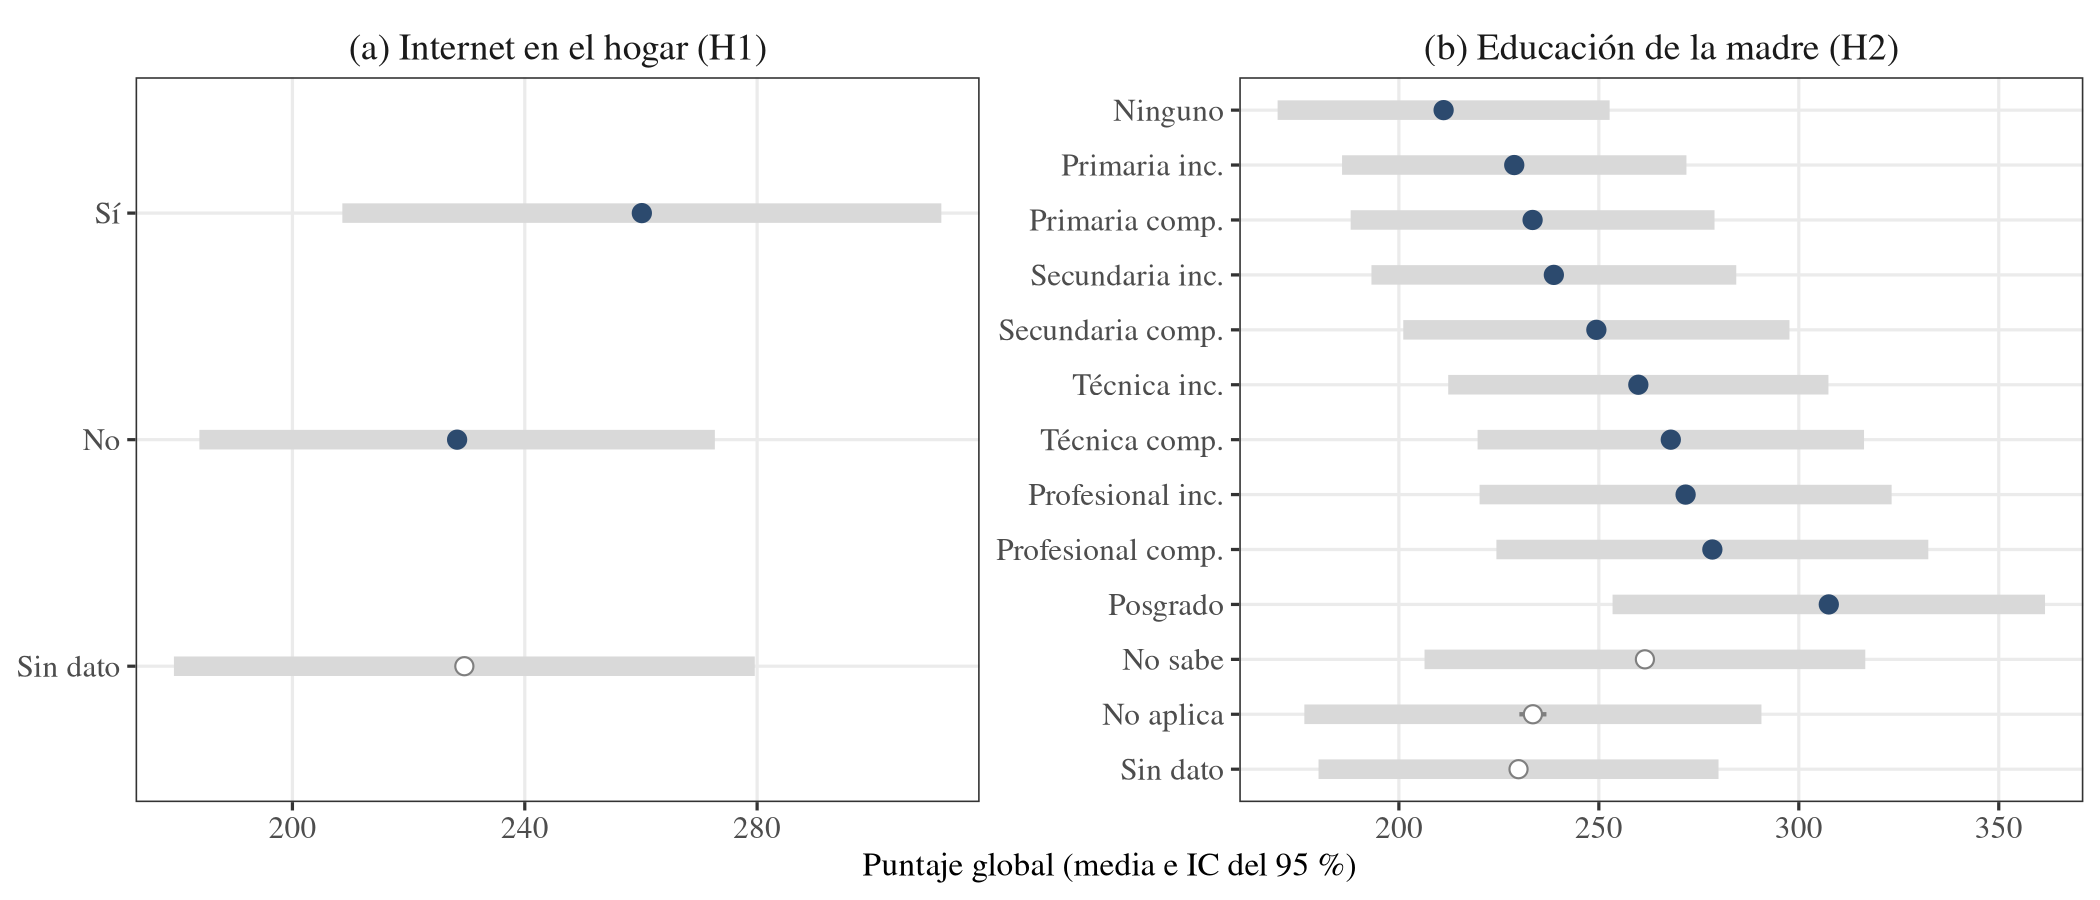

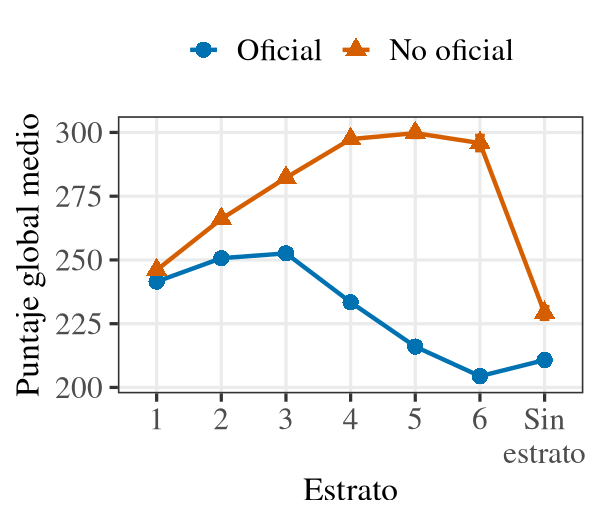

In [21]:
for nombre, ancho in (("medias-ic", 640), ("interaccion", 360)):
    ruta = RUTA_FIGURAS / "r" / f"{nombre}-ggplot2.png"
    figuras.registrar(ruta)
    display(Image(filename=ruta, width=ancho))

**Lectura.** Las dos implementaciones llegan a los mismos números. La mayor diferencia relativa está en los intervalos de Tukey, del orden de 1e-8, porque scipy y R calculan el cuantil del rango estudentizado con algoritmos distintos; en los estadísticos, las diferencias de medias, los tamaños de efecto y las medias de las figuras es del orden del error de redondeo, y los p ajustados de Tukey difieren en menos de 1e-12. Eso confirma que R recibió las mismas filas con los mismos niveles y que los resultados de H1 a H4 no dependen de la herramienta, incluida la ANOVA con HC3, donde statsmodels y `car` construyen la prueba de Wald con la misma matriz robusta. Las dos figuras de ggplot2 dibujan lo mismo que las de Python: las medias con su intervalo y la barra de una desviación, y la interacción, con la caída de los colegios oficiales en los estratos altos.

## 9. Regresión regularizada

S1 pregunta cuánto del puntaje global explican el hogar, el colegio y el estudiante sin los puntajes por área ni el de inglés, que lo reconstruyen (`variables.PROHIBIDOS_REGRESION`). La múltiple de la fase 2 responde con mínimos cuadrados; aquí se le suma una penalización al tamaño de los coeficientes. Ridge (L2) los encoge todos, Lasso (L1) lleva algunos a cero y ElasticNet mezcla las dos penalizaciones con `l1_ratio`. Cada uno elige su α con validación cruzada de 5 pliegues barajados sobre todo el entrenamiento (`RidgeCV`, `LassoCV` y `ElasticNetCV`), dentro del mismo `Pipeline` de la múltiple: imputación por moda, edad winsorizada, one-hot con las referencias de la fase 2 y `StandardScaler` en las numéricas, porque la penalización depende de la escala; las indicadoras quedan en 0 y 1, como en la múltiple. Ridge busca α en una rejilla logarítmica de 10⁻² a 10⁷. Lasso y ElasticNet recorren la trayectoria de 100 valores que calcula scikit-learn, desde el α que anula todos los coeficientes hasta 10⁻⁵ veces ese valor: con el extremo por omisión (10⁻³) el α elegido caía en el borde inferior de la rejilla, señal de que la validación cruzada pedía menos penalización de la que la rejilla ofrecía. Los modelos ajustados se guardan en la caché, con la versión del código en la clave.

In [22]:
PREDICTORES = v.PREDICTORES_REGRESION[modelos.ESPECIFICACION]
OBJETIVO = v.OBJETIVO_REGRESION
y_ent_regresion, y_val_regresion = y_entrenamiento[OBJETIVO], y_validacion[OBJETIVO]
PLIEGUES = KFold(n_splits=ajuste.PLIEGUES, shuffle=True, random_state=ajuste.SEMILLA)
ALFAS_RIDGE = np.logspace(-2, 7, 37)
EPS_TRAYECTORIA = 1e-5
L1_RATIOS = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99]
NOMBRE_MODELO = {
    "ridge": "Ridge",
    "lasso": "Lasso",
    "elasticNet": "ElasticNet",
    "randomForestSinAjuste": "Random Forest sin ajuste",
    "randomForestMuestra": "Random Forest ajustado, en la muestra",
    "randomForestRegresion": "Random Forest ajustado",
    "xgboostRegresion": "XGBoost ajustado",
}
SUFIJO_REGRESION = {
    "ridge": "Ridge",
    "lasso": "Lasso",
    "elasticNet": "ElasticNet",
    "randomForestSinAjuste": "RandomForestSinAjuste",
    "randomForestMuestra": "RandomForestMuestra",
    "randomForestRegresion": "RandomForest",
    "xgboostRegresion": "Xgboost",
}
ajustado = ajuste.en_cache(ajuste.ajustado)


def decimales_significativos(valor: float, significativas: int = 3) -> int:
    """Decimales que dejan `significativas` cifras significativas (al menos cero)."""
    return max(0, significativas - 1 - int(np.floor(np.log10(abs(valor)))))


def cifra_parametro(prefijo: str, parametro: str, valor: object) -> str:
    """Cifra de un hiperparámetro elegido: `modelo__max_depth` con prefijo `bosque` da `bosqueMaxDepth`."""
    clave = prefijo + "".join(parte.capitalize() for parte in parametro.removeprefix("modelo__").split("_"))
    if valor is None:
        return cifra(clave, "sin límite")
    if isinstance(valor, str):
        return cifra(clave, valor)
    return cifra(clave, valor, 0 if float(valor).is_integer() else decimales_significativos(valor))


penalizados = {
    "ridge": RidgeCV(alphas=ALFAS_RIDGE, cv=PLIEGUES),
    "lasso": LassoCV(eps=EPS_TRAYECTORIA, cv=PLIEGUES, n_jobs=-1),
    "elasticNet": ElasticNetCV(l1_ratio=L1_RATIOS, eps=EPS_TRAYECTORIA, cv=PLIEGUES, n_jobs=-1),
}
regularizados = {nombre: ajustado(modelos.pipeline(PREDICTORES, estimador), X_entrenamiento, y_ent_regresion).modelo for nombre, estimador in penalizados.items()}
estimadores = {nombre: tuberia.named_steps["modelo"] for nombre, tuberia in regularizados.items()}
rejillas = {
    "ridge": ALFAS_RIDGE,
    "lasso": estimadores["lasso"].alphas_,
    "elasticNet": estimadores["elasticNet"].alphas_[L1_RATIOS.index(estimadores["elasticNet"].l1_ratio_)],
}
penalizacion = pd.DataFrame({
    NOMBRE_MODELO[nombre]: {
        "α elegido": e.alpha_,
        "l1_ratio": {"ridge": 0.0, "lasso": 1.0}.get(nombre, getattr(e, "l1_ratio_", None)),
        "α mínimo de la rejilla": rejillas[nombre].min(),
        "α máximo de la rejilla": rejillas[nombre].max(),
        "Coeficientes distintos de cero": int(np.sum(e.coef_ != 0)),
        "Columnas codificadas": len(e.coef_),
    }
    for nombre, e in estimadores.items()
}).T
print(penalizacion.to_string(formatters={c: (lambda x: f"{x:.3g}".replace(".", ",")) for c in ("α elegido", "α mínimo de la rejilla", "α máximo de la rejilla")}))
comprobar(
    "El α elegido por validación cruzada queda dentro de su rejilla, sin tocar sus bordes",
    all(rejillas[n].min() < e.alpha_ < rejillas[n].max() for n, e in estimadores.items()),
)
for nombre, e in estimadores.items():
    sufijo = SUFIJO_REGRESION[nombre]
    cifra(f"alfa{sufijo}", e.alpha_, decimales_significativos(e.alpha_))
    cifra(f"coeficientesNoNulos{sufijo}", int(np.sum(e.coef_ != 0)))
cifra("columnasCodificadas", len(estimadores["ridge"].coef_))
cifra("lUnoRatioElasticNet", estimadores["elasticNet"].l1_ratio_, 2);

           α elegido  l1_ratio α mínimo de la rejilla α máximo de la rejilla  Coeficientes distintos de cero  Columnas codificadas
Ridge           5,62      0.00                   0,01                  1e+07                            95.0                  95.0
Lasso       0,000328      1.00               0,000145                   14,5                            93.0                  95.0
ElasticNet  0,000295      0.99               0,000147                   14,7                            93.0                  95.0
[ok] El α elegido por validación cruzada queda dentro de su rejilla, sin tocar sus bordes


Las métricas de cada modelo se calculan en las filas con que se ajustó (todo el entrenamiento, salvo los bosques ajustados en la muestra) y en validación. La diferencia entre las dos dice cuánto se sobreajusta; la de validación frente a la múltiple de la fase 2, cuánto aporta el modelo sobre la base.

In [23]:
resultados_regresion: dict[str, dict] = {}


def evaluar_regresion(nombre: str, modelo, X_ajuste: pd.DataFrame, y_ajuste: pd.Series) -> None:
    """R², RMSE y MAE en las filas de ajuste y en validación; registra sus cifras."""
    metricas = {"entrenamiento": modelos.metricas_regresion(y_ajuste, modelo.predict(X_ajuste)), "validación": modelos.metricas_regresion(y_val_regresion, modelo.predict(X_validacion))}
    resultados_regresion[nombre] = {"Filas de ajuste": len(X_ajuste), **{f"{m} {c}": valor for c, fila in metricas.items() for m, valor in fila.items()}}
    for conjunto, fila in metricas.items():
        for metrica, valor in fila.items():
            prefijo = {"r2": "rCuadrado"}.get(metrica, metrica)
            cifra(f"{prefijo}{'Entrenamiento' if conjunto == 'entrenamiento' else 'Validacion'}{SUFIJO_REGRESION[nombre]}", valor, 3 if metrica == "r2" else 2)


for nombre, tuberia in regularizados.items():
    evaluar_regresion(nombre, tuberia, X_entrenamiento, y_ent_regresion)
tabla(pd.DataFrame(resultados_regresion).T.rename(index=NOMBRE_MODELO), 3)

           Filas de ajuste r2 entrenamiento rmse entrenamiento mae entrenamiento r2 validación rmse validación mae validación
Ridge              372.792            0,318             42,803            34,716         0,319          42,811         34,709
Lasso              372.792            0,318             42,803            34,716         0,319          42,811         34,709
ElasticNet         372.792            0,318             42,803            34,716         0,319          42,811         34,709


### 9.1. Trayectoria de los coeficientes

La figura repite el ejercicio de la clase con estos datos: recorre α y dibuja cómo cambia cada coeficiente. Los de Ridge salen de la descomposición en valores singulares de la matriz codificada y centrada (β(α) = V diag(s / (s² + α)) Uᵀy, la misma solución que `Ridge`); los de Lasso, de `lasso_path` sobre la trayectoria que recorrió `LassoCV`. Se destacan las seis columnas con mayor coeficiente absoluto en el Lasso elegido; las demás van en gris. Los coeficientes están en puntos del puntaje global: por categoría frente a su referencia y, en las numéricas, por desviación estándar.

[ok] La trayectoria de Ridge reproduce los coeficientes del Ridge elegido
                                α en que Lasso la anula
Sin dato: Edad                                   0,0085
Departamento: Chocó                              0,2787
Departamento: Magdalena                          0,4438
Educación del padre: Posgrado                    0,4985
Educación de la madre: Posgrado                  0,7067
Jornada: Sabatina                                0,8917
[ok] Entre las seis destacadas, Lasso anula primero el indicador de edad sin dato y las otras cinco dentro de un mismo orden de magnitud de α


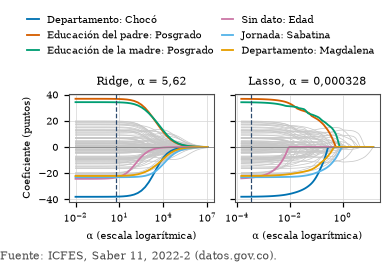

In [24]:
ETIQUETA_VARIABLE = {
    v.ESTRATO: "Estrato",
    v.EDUCACION_MADRE: "Educación de la madre",
    v.EDUCACION_PADRE: "Educación del padre",
    "FAMI_TIENEINTERNET": "Internet",
    "FAMI_TIENECOMPUTADOR": "Computador",
    "FAMI_TIENEAUTOMOVIL": "Automóvil",
    "FAMI_TIENELAVADORA": "Lavadora",
    v.CUARTOS_HOGAR: "Cuartos",
    v.PERSONAS_HOGAR: "Personas en el hogar",
    "COLE_NATURALEZA": "Naturaleza",
    "COLE_AREA_UBICACION": "Zona",
    "COLE_JORNADA": "Jornada",
    "COLE_CALENDARIO": "Calendario",
    "COLE_CARACTER": "Carácter",
    "COLE_BILINGUE": "Bilingüe",
    "COLE_GENERO": "Género del colegio",
    v.DEPARTAMENTO: "Departamento",
    "ESTU_GENERO": "Género",
    v.EDAD: "Edad",
}


# Los datos traen los departamentos en mayúsculas y sin tildes, y algunos niveles con la grafía del
# cuestionario («Sin Estrato», «Postgrado»); las tablas y las figuras usan la forma correcta.
NIVEL_LEGIBLE = {"Si": "Sí", "S": "Sí", "N": "No", "UNICA": "Única", limpieza.SIN_ESTRATO: "Sin estrato", "Postgrado": "Posgrado"}
DEPARTAMENTO_LEGIBLE = {
    "ATLANTICO": "Atlántico", "BOLIVAR": "Bolívar", "BOYACA": "Boyacá", "CAQUETA": "Caquetá", "CHOCO": "Chocó", "CORDOBA": "Córdoba",
    "GUAINIA": "Guainía", "NORTE SANTANDER": "Norte de Santander", "QUINDIO": "Quindío", "SAN ANDRES": "San Andrés", "VALLE": "Valle del Cauca", "VAUPES": "Vaupés",
}


def nivel_legible(variable: str, nivel: str) -> str:
    """Nivel como se escribe en tablas y figuras: con tildes y mayúscula inicial; los departamentos, con su nombre propio."""
    if variable == v.DEPARTAMENTO:
        return DEPARTAMENTO_LEGIBLE.get(nivel, nivel.title())
    if nivel in NIVEL_LEGIBLE:
        return NIVEL_LEGIBLE[nivel]
    return nivel.capitalize() if nivel.isupper() else nivel


def etiqueta_columna(columna: str) -> str:
    """Nombre legible de una columna codificada: «Variable: nivel», la numérica o «Sin dato: variable»."""
    if columna.startswith(v.PREFIJO_FALTA):
        return f"Sin dato: {ETIQUETA_VARIABLE.get(columna.removeprefix(v.PREFIJO_FALTA), columna)}"
    variable, _, nivel = modelos.clave_termino(columna).partition("=")
    nombre = ETIQUETA_VARIABLE.get(variable, variable)
    return f"{nombre}: {nivel_legible(variable, nivel)}" if nivel else nombre


preparado = regularizados["lasso"][:-1].transform(X_entrenamiento)
centrado = (preparado - preparado.mean()).to_numpy(dtype=float)
y_centrado = (y_ent_regresion - y_ent_regresion.mean()).to_numpy(dtype=float)
U, s, Vt = np.linalg.svd(centrado, full_matrices=False)
proyeccion = U.T @ y_centrado
trayectoria_ridge = np.array([Vt.T @ (s / (s**2 + alfa) * proyeccion) for alfa in ALFAS_RIDGE])
alfas_lasso, trayectoria_lasso, _ = lasso_path(centrado, y_centrado, alphas=rejillas["lasso"])
del U, centrado
posicion_ridge = int(np.argmin(np.abs(ALFAS_RIDGE - estimadores["ridge"].alpha_)))
comprobar(
    "La trayectoria de Ridge reproduce los coeficientes del Ridge elegido",
    list(preparado.columns) == list(regularizados["ridge"].named_steps["codificacion"].get_feature_names_out()) and np.allclose(trayectoria_ridge[posicion_ridge], estimadores["ridge"].coef_, rtol=1e-6, atol=1e-6),
)
destacadas = np.argsort(-np.abs(estimadores["lasso"].coef_))[:6]
# α desde el que Lasso anula cada columna destacada: `lasso_path` recorre α de mayor a menor, así que es
# el mayor α en que su coeficiente todavía no es cero.
anulacion = pd.Series({etiqueta_columna(preparado.columns[i]): alfas_lasso[np.flatnonzero(trayectoria_lasso[i]).min()] for i in destacadas}).sort_values()
tabla(anulacion.rename("α en que Lasso la anula").to_frame(), 4)
comprobar(
    "Entre las seis destacadas, Lasso anula primero el indicador de edad sin dato y las otras cinco dentro de un mismo orden de magnitud de α",
    anulacion.index[0] == f"Sin dato: {ETIQUETA_VARIABLE[v.EDAD]}" and anulacion.iloc[1:].max() / anulacion.iloc[1:].min() < 10,
)

# Dos paneles al ancho de una columna, con la leyenda encima de los dos.
figura, (eje_ridge, eje_lasso) = plt.subplots(1, 2, figsize=(graficos.ANCHO_COLUMNA, 1.7), sharey=True)
for eje, alfas, trayectoria, nombre in ((eje_ridge, ALFAS_RIDGE, trayectoria_ridge, "ridge"), (eje_lasso, alfas_lasso, trayectoria_lasso.T, "lasso")):
    eje.plot(alfas, np.delete(trayectoria, destacadas, axis=1), color="#C8C8C8", linewidth=0.5)
    for color, indice in zip(graficos.PALETA_CATEGORICA, destacadas, strict=False):
        eje.plot(alfas, trayectoria[:, indice], color=color, linewidth=1.2, label=etiqueta_columna(preparado.columns[indice]))
    eje.axvline(estimadores[nombre].alpha_, color=graficos.COLOR_PRINCIPAL, linestyle="--", linewidth=0.8)
    eje.axhline(0, color=graficos.COLOR_APOYO, linewidth=0.5)
    eje.set(xscale="log", xlabel="α (escala logarítmica)", title=f"{NOMBRE_MODELO[nombre]}, α = {en_espanol(estimadores[nombre].alpha_, decimales_significativos(estimadores[nombre].alpha_))}")
eje_ridge.set_ylabel("Coeficiente (puntos)")
eje_ridge.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
figura.tight_layout(w_pad=0.8)
figura.legend(*eje_lasso.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=6.5, handlelength=1.2, columnspacing=0.8)
graficos.anotar_fuente(eje_ridge, FUENTE)
figuras.guardar(figura, "regularizacion-trayectorias")
plt.show()
cifra("coeficienteMayorLasso", float(np.abs(estimadores["lasso"].coef_).max()), 1)
cifra("variableMayorLasso", etiqueta_columna(preparado.columns[destacadas[0]]))
del preparado

**Lectura.** La penalización no cambia nada en estos datos. Los tres modelos eligen un α pequeño (5,62 en Ridge y del orden de 3·10⁻⁴ en Lasso y ElasticNet, este con `l1_ratio` de 0,99, casi un Lasso); Lasso y ElasticNet solo anulan 2 de las 95 columnas codificadas, y el RMSE de validación (42,81) coincide con el de la múltiple de la fase 2 hasta el tercer decimal. Con 372.792 estudiantes y 95 coeficientes la varianza de la estimación ya es mínima: no hay sobreajuste que corregir (la brecha entre entrenamiento y validación es de 0,008 puntos), y el límite del modelo lineal está en su forma, no en el tamaño de los coeficientes.

La trayectoria muestra lo que pasaría con más penalización. En Ridge todos los coeficientes se encogen a la vez y solo se acercan a cero con α del orden de 10⁶; en Lasso salen del modelo uno a uno. Los seis coeficientes más grandes son categorías poco frecuentes: Chocó y Magdalena (unos 38 y 22 puntos por debajo de su referencia), la jornada sabatina, la edad sin dato y los padres con posgrado (unos 35 puntos por encima). Lasso anula primero la edad sin dato, cerca de α = 0,01, y luego, entre 0,3 y 1, Chocó, Magdalena, la jornada sabatina y la educación de los padres, mientras otras variables, en gris, siguen en el modelo hasta α cercano a 10. Un coeficiente grande no es una variable importante: su peso en el error depende de cuántos estudiantes tienen esa categoría, y estas cubren a pocos. La importancia por variable se mide en §14.

## 10. Ensambles de árboles: Random Forest y XGBoost

El flujo sigue los cinco pasos de la clase: Random Forest sin ajuste como primer ensamble, `RandomizedSearchCV` para ajustarlo, XGBoost ajustado, validación cruzada con la prueba aparte e importancia de variables (esta última en §14). Random Forest busca en la muestra de 20.000 estudiantes de la fase 2, porque cada configuración se ajusta cinco veces, y la mejor configuración se reajusta una sola vez con todo el entrenamiento. XGBoost busca sobre todo el entrenamiento en la GPU. Las dos búsquedas usan validación cruzada de 5 pliegues barajados con el RMSE como puntuación, sin reajuste interno (`ajuste.buscar`), y se guardan en la caché.

### 10.1. Presupuesto de las búsquedas

Cuántas configuraciones prueba cada búsqueda no se decide a ojo. Se mide el tiempo de un ajuste con la configuración central del espacio (la mediana de cada distribución y el elemento del medio de cada lista; `ajuste.configuracion_central`), sobre las filas donde se busca, y `N_ITER` es el mayor entero hasta 30 cuya búsqueda estimada (5 pliegues por ese tiempo) cabe en 15 minutos. El número quedó fijado en `ajuste.N_ITER` con la primera medición, para que las cifras no dependan del tiempo de cada corrida; la comprobación lo ata a la regla con un margen del 25 % en el tiempo medido, que es lo que varía entre corridas. Los tiempos dependen de la máquina y llevan el prefijo `medida` en las cifras.

In [25]:
# XGBoost entrena en la GPU y recibe los datos en CPU para predecir: avisa que pasa por una
# DMatrix intermedia, lo que solo cambia la memoria y el tiempo de esa predicción.
warnings.filterwarnings("ignore", message=".*Falling back to prediction using DMatrix due to mismatched devices")
# En la muestra y en algunos pliegues faltan niveles raros de alguna variable categórica; al
# predecir, el one-hot de la fase 2 (`handle_unknown="ignore"`) los codifica en ceros y avisa
# cada vez. El aviso no cambia el resultado.
warnings.filterwarnings("ignore", message="Found unknown categories in columns", category=UserWarning)
MARGEN_MEDICION = 0.25
en_muestra = muestra.loc[X_entrenamiento.index].to_numpy()
X_muestra, y_muestra = X_entrenamiento[en_muestra], y_entrenamiento[en_muestra]
buscar = ajuste.en_cache(ajuste.buscar)


def presupuesto(busquedas: dict[str, tuple]) -> pd.DataFrame:
    """Ajuste medido con la configuración central, `n_iter` que da la regla y la constante fijada, por modelo."""
    filas = {}
    for nombre, (tuberia, X, y_) in busquedas.items():
        segundos = ajuste.segundos_de_ajuste(clone(tuberia).set_params(**ajuste.configuracion_central(ajuste.ESPACIOS[nombre])), X, y_)
        filas[nombre] = {
            "Filas": len(X),
            "Ajuste medido (s)": segundos,
            "n_iter con la medida": ajuste.n_iter_que_cabe(segundos),
            "n_iter admisible, mínimo": ajuste.n_iter_que_cabe(segundos * (1 + MARGEN_MEDICION)),
            "n_iter admisible, máximo": ajuste.n_iter_que_cabe(segundos / (1 + MARGEN_MEDICION)),
            "N_ITER fijado": ajuste.N_ITER[nombre],
            "Búsqueda proyectada (min)": ajuste.PLIEGUES * segundos * ajuste.N_ITER[nombre] / 60,
        }
    return pd.DataFrame(filas).T


tuberias_regresion = {
    "randomForestRegresion": modelos.pipeline(PREDICTORES, RandomForestRegressor(n_jobs=-1, random_state=ajuste.SEMILLA)),
    "xgboostRegresion": modelos.pipeline(PREDICTORES, XGBRegressor(device=str(DISPOSITIVO), random_state=ajuste.SEMILLA)),
}
filas_busqueda = {"randomForestRegresion": (X_muestra, y_muestra[OBJETIVO]), "xgboostRegresion": (X_entrenamiento, y_ent_regresion)}
presupuesto_regresion = presupuesto({nombre: (tuberias_regresion[nombre], *filas_busqueda[nombre]) for nombre in tuberias_regresion})
tabla(presupuesto_regresion.rename(index=NOMBRE_MODELO), 2)
for nombre in tuberias_regresion:
    print(f"Configuración central de {NOMBRE_MODELO[nombre]}: {ajuste.configuracion_central(ajuste.ESPACIOS[nombre])}")
comprobar(
    "N_ITER de Random Forest y de XGBoost es el que da la regla con el ajuste medido (margen del 25 %)",
    all(fila["n_iter admisible, mínimo"] <= fila["N_ITER fijado"] <= fila["n_iter admisible, máximo"] for _, fila in presupuesto_regresion.iterrows()),
)
for nombre, fila in presupuesto_regresion.iterrows():
    sufijo = SUFIJO_REGRESION[nombre]
    cifra(f"nIter{sufijo}", int(fila["N_ITER fijado"]))
    cifra(f"medidaAjuste{sufijo}", fila["Ajuste medido (s)"], 1)
    cifra(f"medidaBusquedaProyectada{sufijo}", fila["Búsqueda proyectada (min)"], 1)
cifra("presupuestoBusquedaMinutos", ajuste.PRESUPUESTO_S / 60)
cifra("maximoNIter", ajuste.MAXIMO_N_ITER);

                         Filas Ajuste medido (s) n_iter con la medida n_iter admisible, mínimo n_iter admisible, máximo N_ITER fijado Búsqueda proyectada (min)
Random Forest ajustado  20.000              0,90                   30                       30                       30            30                      2,26
XGBoost ajustado       372.792              4,95                   30                       29                       30            30                     12,37
Configuración central de Random Forest ajustado: {'modelo__n_estimators': 300, 'modelo__max_depth': 20, 'modelo__min_samples_leaf': 10, 'modelo__max_features': 0.5}
Configuración central de XGBoost ajustado: {'modelo__n_estimators': 600, 'modelo__learning_rate': 0.05477225575051663, 'modelo__max_depth': 6, 'modelo__min_child_weight': 4.472135954999579, 'modelo__subsample': 0.8, 'modelo__colsample_bytree': 0.8, 'modelo__reg_lambda': 1.0000000000000004}
[ok] N_ITER de Random Forest y de XGBoost es el que da la regla 

### 10.2. Random Forest: sin ajuste, ajustado en la muestra y reajustado

El primer paso es el bosque con los valores por omisión de scikit-learn (100 árboles sin límite de profundidad, todas las columnas en cada división y hojas de un estudiante), ajustado en la muestra. Luego `RandomizedSearchCV` prueba `N_ITER` configuraciones de número de árboles, profundidad, tamaño mínimo de hoja y fracción de columnas por división. La mejor se ajusta en la muestra y se reajusta con todo el entrenamiento si el reajuste estimado cabe en 15 minutos (`ajuste.REAJUSTE_RANDOM_FOREST`): el tiempo del ajuste en la muestra se proyecta al entrenamiento completo con la escala n log n de la construcción de un árbol.

In [26]:
bosque_sin_ajuste = clone(tuberias_regresion["randomForestRegresion"]).fit(X_muestra, y_muestra[OBJETIVO])
evaluar_regresion("randomForestSinAjuste", bosque_sin_ajuste, X_muestra, y_muestra[OBJETIVO])
del bosque_sin_ajuste

busquedas_regresion = {
    nombre: buscar(tuberias_regresion[nombre], ajuste.ESPACIOS[nombre], ajuste.N_ITER[nombre], *filas_busqueda[nombre], ajuste.PUNTUACION["regresion"])
    for nombre in tuberias_regresion
}
mejores_regresion = {nombre: clone(tuberias_regresion[nombre]).set_params(**b.mejores) for nombre, b in busquedas_regresion.items()}
segundos_bosque_muestra = ajuste.segundos_de_ajuste(mejores_regresion["randomForestRegresion"], X_muestra, y_muestra[OBJETIVO])
reajuste_proyectado = ajuste.proyectar_segundos(segundos_bosque_muestra, len(X_muestra), len(X_entrenamiento))
print(f"Mejor configuración de Random Forest en la muestra: {busquedas_regresion['randomForestRegresion'].mejores}")
print(f"RMSE de validación cruzada: {en_espanol(-busquedas_regresion['randomForestRegresion'].puntuacion, 2)}")
print(
    f"Ajuste en la muestra: {en_espanol(segundos_bosque_muestra, 1)} s; reajuste proyectado a {en_espanol(len(X_entrenamiento))} filas: "
    f"{en_espanol(reajuste_proyectado / 60, 1)} min; REAJUSTE_RANDOM_FOREST = {ajuste.REAJUSTE_RANDOM_FOREST}"
)
comprobar(
    "REAJUSTE_RANDOM_FOREST es el que da la regla con el ajuste medido (margen del 25 %)",
    ajuste.REAJUSTE_RANDOM_FOREST in {ajuste.reajuste_cabe(reajuste_proyectado * (1 + MARGEN_MEDICION)), ajuste.reajuste_cabe(reajuste_proyectado / (1 + MARGEN_MEDICION))},
)
bosque_muestra = ajustado(mejores_regresion["randomForestRegresion"], X_muestra, y_muestra[OBJETIVO]).modelo
evaluar_regresion("randomForestMuestra", bosque_muestra, X_muestra, y_muestra[OBJETIVO])
if ajuste.REAJUSTE_RANDOM_FOREST:
    reajuste = ajustado(mejores_regresion["randomForestRegresion"], X_entrenamiento, y_ent_regresion)
    bosque_regresion = reajuste.modelo
    evaluar_regresion("randomForestRegresion", bosque_regresion, X_entrenamiento, y_ent_regresion)
    print(f"Reajuste real (primera ejecución, guardada en la caché): {en_espanol(reajuste.segundos / 60, 1)} min, {en_espanol(reajuste.segundos / reajuste_proyectado, 1)} veces lo proyectado")
    cifra("medidaReajusteRealMinutos", reajuste.segundos / 60, 1)
else:
    bosque_regresion = bosque_muestra
    evaluar_regresion("randomForestRegresion", bosque_regresion, X_muestra, y_muestra[OBJETIVO])
del bosque_muestra
cifra("medidaReajusteProyectadoMinutos", reajuste_proyectado / 60, 1)
cifra("reajusteRandomForest", "sí" if ajuste.REAJUSTE_RANDOM_FOREST else "no")
cifra("rmseValidacionCruzadaRandomForest", -busquedas_regresion["randomForestRegresion"].puntuacion, 2);

Mejor configuración de Random Forest en la muestra: {'modelo__max_depth': 30, 'modelo__max_features': 0.33, 'modelo__min_samples_leaf': 6, 'modelo__n_estimators': 485}
RMSE de validación cruzada: 42,79
Ajuste en la muestra: 1,1 s; reajuste proyectado a 372.792 filas: 0,4 min; REAJUSTE_RANDOM_FOREST = True
[ok] REAJUSTE_RANDOM_FOREST es el que da la regla con el ajuste medido (margen del 25 %)


Reajuste real (primera ejecución, guardada en la caché): 2,1 min, 4,8 veces lo proyectado


### 10.3. XGBoost en la GPU

XGBoost construye los árboles en serie, cada uno sobre los errores de los anteriores, con tasa de aprendizaje, profundidad, peso mínimo por hoja, submuestreo de filas y columnas y penalización L2 como hiperparámetros. Corre con el histograma de la GPU (`device`), y la búsqueda usa todo el entrenamiento. La mejor configuración se ajusta una vez con todo el entrenamiento.

Los modelos finales de XGBoost entrenan en la GPU, pero predicen en la CPU. En esta máquina, la predicción en la GPU con datos que llegan desde la CPU falla con un acceso ilegal a memoria cuando el lote es grande: con 80.000 filas ya falla, y los pliegues de la búsqueda, de 74.559 filas o menos, pasan; validación tiene 79.884. En la CPU tarda unos segundos sobre todo el entrenamiento; la comprobación mide, en 50.000 filas de validación, cuánto difieren las dos predicciones, que solo cambian por el orden de las sumas en precisión simple.

In [27]:
FILAS_CONTROL_GPU = 50_000


def predecir_en_cpu(tuberia, salida=lambda modelo, X: modelo.predict(X), X_control: pd.DataFrame | None = None) -> float:
    """Pasa a la CPU la predicción de un XGBoost ya ajustado; devuelve la mayor diferencia con la GPU en filas de validación."""
    control = (X_validacion if X_control is None else X_control).iloc[:FILAS_CONTROL_GPU]
    en_gpu = salida(tuberia, control)
    tuberia.set_params(modelo__device="cpu")
    return float(np.max(np.abs(salida(tuberia, control) - en_gpu)))


xgboost_regresion = ajustado(mejores_regresion["xgboostRegresion"], X_entrenamiento, y_ent_regresion).modelo
diferencia_cpu_regresion = predecir_en_cpu(xgboost_regresion)
print(f"Mayor diferencia entre la predicción en CPU y en GPU ({en_espanol(FILAS_CONTROL_GPU)} filas de validación): {diferencia_cpu_regresion:.2e} puntos")
comprobar("La predicción de XGBoost en la CPU coincide con la de la GPU a menos de 0,01 puntos", diferencia_cpu_regresion < 0.01)
evaluar_regresion("xgboostRegresion", xgboost_regresion, X_entrenamiento, y_ent_regresion)
print(f"Mejor configuración de XGBoost: {busquedas_regresion['xgboostRegresion'].mejores}")
print(f"RMSE de validación cruzada: {en_espanol(-busquedas_regresion['xgboostRegresion'].puntuacion, 2)}")
cifra("rmseValidacionCruzadaXgboost", -busquedas_regresion["xgboostRegresion"].puntuacion, 2)
for nombre, busqueda in busquedas_regresion.items():
    for parametro, valor in busqueda.mejores.items():
        cifra_parametro(f"mejor{SUFIJO_REGRESION[nombre]}", parametro, valor)

Mayor diferencia entre la predicción en CPU y en GPU (50.000 filas de validación): 1.19e-03 puntos
[ok] La predicción de XGBoost en la CPU coincide con la de la GPU a menos de 0,01 puntos


Mejor configuración de XGBoost: {'modelo__colsample_bytree': np.float64(0.8281775897621597), 'modelo__learning_rate': np.float64(0.05879431781724018), 'modelo__max_depth': 8, 'modelo__min_child_weight': np.float64(2.6501137707458966), 'modelo__n_estimators': 919, 'modelo__reg_lambda': np.float64(3.1234907221207773), 'modelo__subsample': np.float64(0.815876852955632)}
RMSE de validación cruzada: 40,93


### 10.4. Comparación con las bases y sobreajuste

La tabla pone juntas las bases de la fase 2 (con sus métricas de `cifras-fase-2.json`) y los modelos de esta fase. La brecha es el RMSE de validación menos el de las filas de ajuste: si es grande, el modelo memoriza; la diferencia frente a la múltiple es lo que el modelo gana en validación sobre la base lineal.

In [28]:
bases_tabla = pd.DataFrame({
    nombre: {
        "Filas de ajuste": de_la_fase_2("filasEntrenamiento"),
        **{f"{m} {c}": de_la_fase_2(f"{ {'r2': 'rCuadrado'}.get(m, m)}{'Entrenamiento' if c == 'entrenamiento' else 'Validacion'}{sufijo}") for c in ("entrenamiento", "validación") for m in ("r2", "rmse", "mae")},
    }
    for nombre, sufijo in BASES_REGRESION.items()
}).T.rename(index={"dummyRegresion": "Media (base)", "linealSimple": "Lineal simple (base)", "regresionMultiple": "Múltiple (base)"})
comparacion_regresion = pd.concat([bases_tabla, pd.DataFrame(resultados_regresion).T.rename(index=NOMBRE_MODELO)])
rmse_multiple = de_la_fase_2("rmseValidacionMultiple")
comparacion_regresion["Brecha de RMSE"] = comparacion_regresion["rmse validación"] - comparacion_regresion["rmse entrenamiento"]
comparacion_regresion["RMSE frente a la múltiple"] = comparacion_regresion["rmse validación"] - rmse_multiple
tabla(comparacion_regresion, 3)
mejor_regresion = min(("ridge", "lasso", "elasticNet", "randomForestRegresion", "xgboostRegresion"), key=lambda n: resultados_regresion[n]["rmse validación"])
print(f"\nMenor RMSE de validación: {NOMBRE_MODELO[mejor_regresion]}")
comprobar("Los regularizados quedan a menos de 0,05 puntos de RMSE de la múltiple de la fase 2", all(abs(resultados_regresion[n]["rmse validación"] - rmse_multiple) < 0.05 for n in regularizados))
comprobar("El mejor ensamble supera a la múltiple de la fase 2 en RMSE de validación", min(resultados_regresion[n]["rmse validación"] for n in ("randomForestRegresion", "xgboostRegresion")) < rmse_multiple)
for nombre in resultados_regresion:
    sufijo = SUFIJO_REGRESION[nombre]
    cifra(f"brechaRmse{sufijo}", comparacion_regresion.loc[NOMBRE_MODELO[nombre], "Brecha de RMSE"], 2)
    cifra(f"mejoraRmse{sufijo}", -comparacion_regresion.loc[NOMBRE_MODELO[nombre], "RMSE frente a la múltiple"], 2)
cifra("mejorRegresion", NOMBRE_MODELO[mejor_regresion]);

                                      Filas de ajuste r2 entrenamiento rmse entrenamiento mae entrenamiento r2 validación rmse validación mae validación Brecha de RMSE RMSE frente a la múltiple
Media (base)                                  372.792                0             51,832            42,949        -0,000          51,868         42,940          0,036                     9,057
Lineal simple (base)                          372.792            0,106             49,018            40,240         0,105          49,060         40,229          0,042                     6,248
Múltiple (base)                               372.792            0,318             42,803            34,716         0,319          42,811         34,708          0,008                         0
Ridge                                         372.792            0,318             42,803            34,716         0,319          42,811         34,709          0,008                     0,000
Lasso                         

El panel de arriba resume la tabla: el RMSE en las filas de ajuste y en validación de cada modelo, con la múltiple de la fase 2 como referencia. El de abajo es el ejercicio de la clase de graficar tiempo contra mejora: el mejor RMSE de validación cruzada que lleva cada búsqueda frente al tiempo acumulado de ajuste.

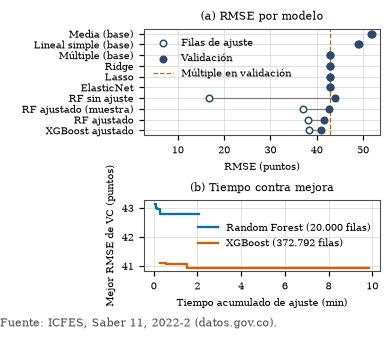

In [29]:
orden = ["Media (base)", "Lineal simple (base)", "Múltiple (base)", *(NOMBRE_MODELO[n] for n in resultados_regresion)]
puntos = comparacion_regresion.loc[orden[::-1]]
# Los dos paneles, uno sobre otro, caben en una columna del informe.
figura, (eje_rmse, eje_tiempo) = plt.subplots(2, 1, figsize=(graficos.ANCHO_COLUMNA, 2.9), gridspec_kw={"height_ratios": [1.5, 1]})
posiciones = np.arange(len(puntos))
eje_rmse.hlines(posiciones, puntos["rmse entrenamiento"], puntos["rmse validación"], color=graficos.COLOR_APOYO, linewidth=0.8)
eje_rmse.scatter(puntos["rmse entrenamiento"], posiciones, facecolors="white", edgecolors=graficos.COLOR_PRINCIPAL, s=18, zorder=3, label="Filas de ajuste")
eje_rmse.scatter(puntos["rmse validación"], posiciones, color=graficos.COLOR_PRINCIPAL, s=18, zorder=3, label="Validación")
eje_rmse.axvline(rmse_multiple, color=graficos.PALETA_CATEGORICA[1], linestyle="--", linewidth=0.8, label="Múltiple en validación")
# Random Forest se abrevia RF para que los nombres no le quiten el ancho al panel.
eje_rmse.set_yticks(posiciones, puntos.index.str.replace("Random Forest", "RF").str.replace(", en la muestra", " (muestra)"))
eje_rmse.set(xlabel="RMSE (puntos)", title="(a) RMSE por modelo")
eje_rmse.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
# Margen a la izquierda para que la leyenda no tape ningún punto.
menor, mayor = puntos[["rmse entrenamiento", "rmse validación"]].min().min(), puntos[["rmse entrenamiento", "rmse validación"]].max().max()
eje_rmse.set_xlim(menor - 0.4 * (mayor - menor), mayor + 0.05 * (mayor - menor))
eje_rmse.legend(loc="upper left")
for (nombre, busqueda), color in zip(busquedas_regresion.items(), graficos.PALETA_CATEGORICA, strict=False):
    resultados = busqueda.resultados
    minutos = (ajuste.PLIEGUES * (resultados["mean_fit_time"] + resultados["mean_score_time"])).cumsum() / 60
    eje_tiempo.step(minutos, -resultados["mean_test_score"].cummax(), where="post", color=color, label=f"{NOMBRE_MODELO[nombre].removesuffix(' ajustado')} ({en_espanol(len(filas_busqueda[nombre][0]))} filas)")
eje_tiempo.set(xlabel="Tiempo acumulado de ajuste (min)", ylabel="Mejor RMSE de VC (puntos)", title="(b) Tiempo contra mejora")
eje_tiempo.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_tiempo.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_tiempo.legend(loc="center right")
figura.tight_layout(h_pad=1.0)
graficos.anotar_fuente(eje_tiempo, FUENTE)
figuras.guardar(figura, "regresion-comparacion")
plt.show()
for nombre, busqueda in busquedas_regresion.items():
    cifra(f"medidaBusqueda{SUFIJO_REGRESION[nombre]}Minutos", busqueda.segundos / 60, 1)

**Lectura.** El flujo de la clase se ve paso a paso. El Random Forest sin ajuste memoriza: con hojas de un estudiante, su RMSE es de 16,8 puntos en la muestra donde se ajustó y de 43,9 en validación, peor que la múltiple (42,8). La búsqueda lo corrige con hojas de al menos 6 estudiantes, profundidad 30 y un tercio de las columnas por división: ajustado en la misma muestra queda en 42,7 en validación, apenas por debajo de la múltiple, y el reajuste con todo el entrenamiento baja a 41,7 (R² de 0,354). XGBoost ajustado es el mejor, con un RMSE de 40,8 y un R² de 0,380 en validación, 2,0 puntos menos que la múltiple, y su brecha entre entrenamiento y validación (2,4 puntos) es menor que la del bosque (3,6). Los ensambles ganan porque captan interacciones y relaciones no lineales que la múltiple no tiene, como la brecha de naturaleza que crece con el estrato (H3). La ganancia es real pero modesta: el hogar, el colegio y el estudiante explican cerca del 38 % de la varianza del puntaje global; el resto depende de lo que estos datos no miden.

La figura de tiempo contra mejora muestra rendimientos decrecientes: el bosque encuentra su mejor configuración en el primer medio minuto de su búsqueda y no vuelve a mejorar, y XGBoost hace casi todo su avance en los dos primeros minutos y después solo gana centésimas. El reajuste real del bosque tardó unas cinco veces lo proyectado con la escala n log n, probablemente porque con más filas los árboles llegan más a menudo a su profundidad máxima y tienen más hojas; aun así quedó lejos del presupuesto de 15 minutos, así que `REAJUSTE_RANDOM_FOREST` no cambia.

## 11. Comparación estadística: t corregido de Nadeau y Bengio

La diferencia de RMSE entre el mejor regularizado y el mejor ensamble en validación es una sola cifra; para saber si se sostiene, los dos modelos se comparan con validación cruzada repetida (5 repeticiones de 5 pliegues, 25 diferencias) sobre el entrenamiento, cada uno con sus hiperparámetros ya elegidos. La t de Student sobre esas 25 diferencias subestima la varianza, porque los conjuntos de entrenamiento de los pliegues se solapan; la corrección de Nadeau y Bengio la multiplica por (1/J + n de prueba / n de entrenamiento) en lugar de 1/J. Si el mejor ensamble fuera Random Forest, la comparación iría sobre la muestra, donde se buscó. La diferencia es el RMSE del regularizado menos el del ensamble: positiva, gana el ensamble.

In [30]:
mejor_regularizado = min(regularizados, key=lambda n: resultados_regresion[n]["rmse validación"])
mejor_ensamble = min(("randomForestRegresion", "xgboostRegresion"), key=lambda n: resultados_regresion[n]["rmse validación"])
PENALIZADO_FIJO = {"ridge": Ridge, "lasso": Lasso, "elasticNet": ElasticNet}
elegido = estimadores[mejor_regularizado]
lineal_fijo = PENALIZADO_FIJO[mejor_regularizado](alpha=elegido.alpha_, **({"l1_ratio": elegido.l1_ratio_} if mejor_regularizado == "elasticNet" else {}))
X_nb, y_nb = (X_muestra, y_muestra[OBJETIVO]) if mejor_ensamble == "randomForestRegresion" else (X_entrenamiento, y_ent_regresion)
diferencias_por_pliegue = ajuste.en_cache(comparacion.diferencias_por_pliegue)
pliegues_nb = diferencias_por_pliegue(modelos.pipeline(PREDICTORES, lineal_fijo), mejores_regresion[mejor_ensamble], X_nb, y_nb)
contraste_nb = comparacion.nadeau_bengio(pliegues_nb["diferencia"], pliegues_nb["n_entrenamiento"].mean(), pliegues_nb["n_prueba"].mean())
ingenuo = stats.ttest_1samp(pliegues_nb["diferencia"], 0)
resumen_nb = pd.DataFrame({
    "t sin corregir": {"t": ingenuo.statistic, "gl": len(pliegues_nb) - 1, "p": texto_p(ingenuo.pvalue)},
    "t de Nadeau y Bengio": {"t": contraste_nb.estadistico, "gl": contraste_nb.gl[0], "p": texto_p(contraste_nb.p)},
}).T
print(f"{NOMBRE_MODELO[mejor_regularizado]} frente a {NOMBRE_MODELO[mejor_ensamble]}, sobre {en_espanol(len(X_nb))} filas")
tabla(pliegues_nb[["metrica_a", "metrica_b", "diferencia"]].describe().loc[["mean", "std", "min", "max"]].rename(index={"mean": "media", "std": "desviación", "min": "mínimo", "max": "máximo"}), 3)
tabla(resumen_nb, 2)
print(f"Diferencia media de RMSE: {en_espanol(contraste_nb.detalle['diferencia_media'], 3)} puntos (error estándar corregido: {en_espanol(contraste_nb.detalle['error_estandar'], 3)})")
comprobar("Nadeau y Bengio usa 25 diferencias (5 repeticiones de 5 pliegues)", len(pliegues_nb) == comparacion.REPETICIONES * comparacion.PLIEGUES and contraste_nb.gl[0] == len(pliegues_nb) - 1)
comprobar("La corrección agranda el error estándar frente a la t sin corregir", abs(contraste_nb.estadistico) < abs(ingenuo.statistic))
cifra("pNadeauBengio", texto_p(contraste_nb.p))
cifra("tNadeauBengio", contraste_nb.estadistico, 2)
cifra("glNadeauBengio", contraste_nb.gl[0])
cifra("diferenciaNadeauBengio", contraste_nb.detalle["diferencia_media"], 2)
cifra("errorNadeauBengio", contraste_nb.detalle["error_estandar"], 3)
cifra("tSinCorregirNadeauBengio", ingenuo.statistic, 1)
cifra("pliegueMinimoNadeauBengio", pliegues_nb["diferencia"].min(), 2)
cifra("mejorRegularizado", NOMBRE_MODELO[mejor_regularizado])
cifra("mejorEnsamble", NOMBRE_MODELO[mejor_ensamble]);

Lasso frente a XGBoost ajustado, sobre 372.792 filas
           metrica_a metrica_b diferencia
media         42,815    40,931      1,884
desviación     0,099     0,096      0,049
mínimo        42,604    40,708      1,791
máximo        42,983    41,118      1,993
                          t gl       p
t sin corregir       193,36 24 < 0,001
t de Nadeau y Bengio  71,81 24 < 0,001
Diferencia media de RMSE: 1,884 puntos (error estándar corregido: 0,026)
[ok] Nadeau y Bengio usa 25 diferencias (5 repeticiones de 5 pliegues)
[ok] La corrección agranda el error estándar frente a la t sin corregir


**Lectura.** La ventaja de XGBoost sobre el mejor regularizado (Lasso) se sostiene en los 25 pliegues: en promedio, 1,88 puntos menos de RMSE, y en el pliegue menos favorable, 1,79. La corrección de Nadeau y Bengio multiplica el error estándar por algo menos de 3 (la t baja de 193,4 a 71,8), porque cada modelo se entrena en el 80 % de las filas y los conjuntos de entrenamiento se solapan; aun así, p < 0,001. Con este n la significación no está en duda y lo que importa es el tamaño: 1,9 puntos sobre un error típico de unos 43 es un 4,4 % menos de error. Para S1, el modelo no lineal predice mejor, pero no cambia la respuesta: las condiciones del hogar y del colegio explican entre un tercio y dos quintos de la variación del puntaje.

## 12. Clasificación supervisada: colegio oficial o no oficial

S2 pregunta qué tan separables son los estudiantes de colegios oficiales y no oficiales a partir de su hogar. Los predictores son los once del hogar y del estudiante (`v.PREDICTORES_CLASIFICACION`), los mismos de la logística base de la fase 2 y con el mismo `Pipeline`; ninguno describe el colegio. Al `Pipeline` le llegan solo esas once columnas: si recibiera las 19 de la regresión, la imputación agregaría los indicadores de faltante de dos variables del colegio (carácter y bilingüe), que sí dicen algo de su naturaleza, y el clasificador dejaría de responder S2. La clase positiva es «NO OFICIAL», cerca del 23 % del entrenamiento. Como la logística base, los clasificadores compensan el desbalance con pesos de clase y no con remuestreo: Random Forest y la SVM con `class_weight="balanced"`, y XGBoost con `scale_pos_weight` igual al cociente entre oficiales y no oficiales del entrenamiento, que da el mismo peso relativo.

El flujo repite el de la regresión. Random Forest busca en la muestra, con `criterion` gini o entropía dentro del espacio, y la mejor configuración se reajusta con todo el entrenamiento según `ajuste.REAJUSTE_RANDOM_FOREST`; XGBoost busca sobre todo el entrenamiento en la GPU. La SVM con kernel RBF busca C y γ y se queda en la muestra, porque su costo crece entre el cuadrado y el cubo de las filas; los ajustes de su búsqueda corren en paralelo en los núcleos de la CPU, así que tarda menos de lo proyectado. El análisis discriminante lineal (LDA), que la unidad 2 presenta con el análisis multivariante, se ajusta con todo el entrenamiento como contraste lineal de la logística. Las búsquedas usan validación cruzada estratificada de 5 pliegues con el AUC-ROC como puntuación, que no depende del umbral, y su número de configuraciones sale de la regla de §10.1.

In [31]:
PREDICTORES_CLASE = v.PREDICTORES_CLASIFICACION
POSITIVA = v.CLASE_POSITIVA
y_ent_clase, y_val_clase = (y[v.OBJETIVO_CLASIFICACION].eq(POSITIVA).astype(int) for y in (y_entrenamiento, y_validacion))
y_muestra_clase = y_ent_clase[en_muestra]
COLUMNAS_CLASE = list(PREDICTORES_CLASE)
X_ent_clase, X_val_clase, X_muestra_clase = (X[COLUMNAS_CLASE] for X in (X_entrenamiento, X_validacion, X_muestra))
peso_no_oficial = float((y_ent_clase == 0).sum() / (y_ent_clase == 1).sum())
NOMBRE_MODELO |= {
    "logisticaUmbral": "Logística base, umbral de F1",
    "randomForestClasificacion": "Random Forest",
    "xgboostClasificacion": "XGBoost",
    "svmClasificacion": "SVM con RBF, en la muestra",
    "ldaClasificacion": "LDA",
}
ETIQUETA_CORTA = {"logisticaUmbral": "Logística base", "randomForestClasificacion": "Random Forest", "xgboostClasificacion": "XGBoost", "svmClasificacion": "SVM en la muestra", "ldaClasificacion": "LDA"}
SUFIJO_CLASIFICACION = {
    "logisticaUmbral": "LogisticaUmbral",
    "randomForestClasificacion": "RandomForestClasificacion",
    "xgboostClasificacion": "XgboostClasificacion",
    "svmClasificacion": "Svm",
    "ldaClasificacion": "Lda",
}
tuberias_clasificacion = {
    "randomForestClasificacion": modelos.pipeline(PREDICTORES_CLASE, RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=ajuste.SEMILLA)),
    "xgboostClasificacion": modelos.pipeline(PREDICTORES_CLASE, XGBClassifier(device=str(DISPOSITIVO), scale_pos_weight=peso_no_oficial, random_state=ajuste.SEMILLA)),
    "svmClasificacion": modelos.pipeline(PREDICTORES_CLASE, SVC(kernel="rbf", class_weight="balanced")),
}
filas_busqueda_clase = {
    "randomForestClasificacion": (X_muestra_clase, y_muestra_clase),
    "xgboostClasificacion": (X_ent_clase, y_ent_clase),
    "svmClasificacion": (X_muestra_clase, y_muestra_clase),
}
EN_PARALELO = {"svmClasificacion": -1}
presupuesto_clasificacion = presupuesto({nombre: (tuberias_clasificacion[nombre], *filas_busqueda_clase[nombre]) for nombre in tuberias_clasificacion})
tabla(presupuesto_clasificacion.rename(index=NOMBRE_MODELO), 2)
print(f"Peso de la clase no oficial en XGBoost (scale_pos_weight): {en_espanol(peso_no_oficial, 3)}")
comprobar(
    "N_ITER de los tres clasificadores es el que da la regla con el ajuste medido (margen del 25 %)",
    all(fila["n_iter admisible, mínimo"] <= fila["N_ITER fijado"] <= fila["n_iter admisible, máximo"] for _, fila in presupuesto_clasificacion.iterrows()),
)
for nombre, fila in presupuesto_clasificacion.iterrows():
    sufijo = SUFIJO_CLASIFICACION[nombre]
    cifra(f"nIter{sufijo}", int(fila["N_ITER fijado"]))
    cifra(f"medidaAjuste{sufijo}", fila["Ajuste medido (s)"], 1)
    cifra(f"medidaBusquedaProyectada{sufijo}", fila["Búsqueda proyectada (min)"], 1)
cifra("pesoNoOficialXgboost", peso_no_oficial, 2);

                             Filas Ajuste medido (s) n_iter con la medida n_iter admisible, mínimo n_iter admisible, máximo N_ITER fijado Búsqueda proyectada (min)
Random Forest               20.000              0,71                   30                       30                       30            30                      1,77
XGBoost                    372.792              2,88                   30                       30                       30            30                      7,21
SVM con RBF, en la muestra  20.000              9,77                   18                       14                       23            21                     17,09
Peso de la clase no oficial en XGBoost (scale_pos_weight): 3,422
[ok] N_ITER de los tres clasificadores es el que da la regla con el ajuste medido (margen del 25 %)


### 12.1. Búsquedas y gini frente a entropía

La tabla da, por modelo, el AUC-ROC medio de validación cruzada de la mejor configuración. Como el criterio de división del bosque entra en el espacio de búsqueda, la comparación entre gini y entropía sale de la misma búsqueda: el mejor AUC y el medio entre las configuraciones de cada criterio.

In [32]:
busquedas_clasificacion = {
    nombre: buscar(tuberias_clasificacion[nombre], ajuste.ESPACIOS[nombre], ajuste.N_ITER[nombre], *filas_busqueda_clase[nombre], ajuste.PUNTUACION["clasificacion"], n_jobs=EN_PARALELO.get(nombre))
    for nombre in tuberias_clasificacion
}
tabla(pd.DataFrame({
    NOMBRE_MODELO[nombre]: {"Filas": len(filas_busqueda_clase[nombre][0]), "Configuraciones": ajuste.N_ITER[nombre], "AUC de validación cruzada": b.puntuacion, "Búsqueda (min)": b.segundos / 60}
    for nombre, b in busquedas_clasificacion.items()
}).T, 3)
for nombre, busqueda in busquedas_clasificacion.items():
    sufijo = SUFIJO_CLASIFICACION[nombre]
    print(f"Mejor configuración de {NOMBRE_MODELO[nombre]}: {busqueda.mejores}")
    cifra(f"aucValidacionCruzada{sufijo}", busqueda.puntuacion, 3)
    cifra(f"medidaBusqueda{sufijo}Minutos", busqueda.segundos / 60, 1)
    for parametro, valor in busqueda.mejores.items():
        cifra_parametro(f"mejor{sufijo}", parametro, valor)

CRITERIO = {"gini": "Gini", "entropy": "Entropía"}
por_criterio = (
    busquedas_clasificacion["randomForestClasificacion"].resultados.groupby("param_modelo__criterion")["mean_test_score"]
    .agg(["count", "max", "mean"])
    .rename(index=CRITERIO, columns={"count": "Configuraciones", "max": "Mejor AUC", "mean": "AUC medio"})
)
print()
tabla(por_criterio, 4)
comprobar("La búsqueda del bosque probó los dos criterios de división", set(por_criterio.index) == set(CRITERIO.values()))
for criterio, fila in por_criterio.iterrows():
    sufijo = "Gini" if criterio == "Gini" else "Entropia"
    cifra(f"mejorAuc{sufijo}", fila["Mejor AUC"], 4)
    cifra(f"aucMedio{sufijo}", fila["AUC medio"], 4)
    cifra(f"configuraciones{sufijo}", int(fila["Configuraciones"]))
cifra("diferenciaGiniEntropia", abs(por_criterio.loc["Gini", "Mejor AUC"] - por_criterio.loc["Entropía", "Mejor AUC"]), 4);

                             Filas Configuraciones AUC de validación cruzada Búsqueda (min)
Random Forest               20.000              30                     0,762          1,688
XGBoost                    372.792              30                     0,776          6,583
SVM con RBF, en la muestra  20.000              21                     0,763          7,398
Mejor configuración de Random Forest: {'modelo__criterion': 'gini', 'modelo__max_depth': 30, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 15, 'modelo__n_estimators': 206}
Mejor configuración de XGBoost: {'modelo__colsample_bytree': np.float64(0.7727780074568463), 'modelo__learning_rate': np.float64(0.02692655251486473), 'modelo__max_depth': 5, 'modelo__min_child_weight': np.float64(3.3130738627811245), 'modelo__n_estimators': 675, 'modelo__reg_lambda': np.float64(8.861577452533075), 'modelo__subsample': np.float64(0.6931085361721216)}
Mejor configuración de SVM con RBF, en la muestra: {'modelo__C': np.float64(

### 12.2. Ajuste final, umbral y métricas

Las mejores configuraciones se ajustan una vez: el bosque con todo el entrenamiento si su reajuste cabe en el presupuesto (la regla y la constante son las de §10.2), XGBoost y el LDA con todo el entrenamiento y la SVM en la muestra; XGBoost entrena en la GPU y, como en §10.3, predice en la CPU. La logística base de la fase 2 se vuelve a ajustar con el mismo `Pipeline` solo para dibujar su curva y darle también su umbral; su AUC de validación tiene que coincidir con el que registró la fase 2, y ninguna base se evalúa en prueba.

El umbral de cada modelo no es 0,5: es el puntaje que maximiza el F1 de la clase no oficial en validación (en la SVM, sobre la función de decisión, cuyo umbral por omisión es 0). Como se elige en validación, el F1 de validación con ese umbral es algo optimista; la estimación honesta es la de prueba en §22, con el mismo umbral. El AUC-ROC y el AUC-PR no dependen del umbral. Las métricas son las de la fase 2 con la clase no oficial como positiva (exactitud, precisión, exhaustividad, F1 y AUC-ROC), más el F1 macro, que promedia el de las dos clases, y el AUC-PR, que con una clase minoritaria es más exigente que el AUC-ROC.

In [33]:
mejores_clasificacion = {nombre: clone(tuberias_clasificacion[nombre]).set_params(**b.mejores) for nombre, b in busquedas_clasificacion.items()}
segundos_bosque_clase = ajuste.segundos_de_ajuste(mejores_clasificacion["randomForestClasificacion"], X_muestra_clase, y_muestra_clase)
reajuste_clase_proyectado = ajuste.proyectar_segundos(segundos_bosque_clase, len(X_muestra), len(X_entrenamiento))
print(
    f"Bosque de clasificación: ajuste en la muestra {en_espanol(segundos_bosque_clase, 1)} s; reajuste proyectado a {en_espanol(len(X_entrenamiento))} filas: "
    f"{en_espanol(reajuste_clase_proyectado / 60, 1)} min; REAJUSTE_RANDOM_FOREST = {ajuste.REAJUSTE_RANDOM_FOREST}"
)
comprobar(
    "REAJUSTE_RANDOM_FOREST es también el que da la regla con el bosque de clasificación (margen del 25 %)",
    ajuste.REAJUSTE_RANDOM_FOREST in {ajuste.reajuste_cabe(reajuste_clase_proyectado * (1 + MARGEN_MEDICION)), ajuste.reajuste_cabe(reajuste_clase_proyectado / (1 + MARGEN_MEDICION))},
)
cifra("medidaReajusteClasificacionProyectadoMinutos", reajuste_clase_proyectado / 60, 1)

filas_ajuste_clase = {
    "randomForestClasificacion": (X_ent_clase, y_ent_clase) if ajuste.REAJUSTE_RANDOM_FOREST else (X_muestra_clase, y_muestra_clase),
    "xgboostClasificacion": (X_ent_clase, y_ent_clase),
    "svmClasificacion": (X_muestra_clase, y_muestra_clase),
    "ldaClasificacion": (X_ent_clase, y_ent_clase),
}
por_ajustar = {**mejores_clasificacion, "ldaClasificacion": modelos.pipeline(PREDICTORES_CLASE, LinearDiscriminantAnalysis())}
clasificadores = {nombre: ajustado(por_ajustar[nombre], *filas_ajuste_clase[nombre]).modelo for nombre in filas_ajuste_clase}
diferencia_cpu_clasificacion = predecir_en_cpu(clasificadores["xgboostClasificacion"], lambda modelo, X: modelo.predict_proba(X)[:, 1], X_val_clase)
print(f"Mayor diferencia de probabilidad entre la CPU y la GPU en XGBoost ({en_espanol(FILAS_CONTROL_GPU)} filas de validación): {diferencia_cpu_clasificacion:.2e}")
comprobar("La probabilidad de XGBoost en la CPU coincide con la de la GPU a menos de 1e-4", diferencia_cpu_clasificacion < 1e-4)
logistica = ajustado(modelos.logistica_base(), X_ent_clase, y_ent_clase).modelo
comprobar(
    "Ningún clasificador recibe variables del colegio, ni sus indicadores de faltante",
    not any("COLE_" in columna for modelo in (logistica, *clasificadores.values()) for columna in modelo.named_steps["codificacion"].get_feature_names_out()),
)


def puntaje(modelo, X: pd.DataFrame) -> np.ndarray:
    """Puntaje de la clase no oficial: la probabilidad o, en la SVM, la función de decisión."""
    if isinstance(modelo.named_steps["modelo"], SVC):
        return modelo.decision_function(X)
    return modelo.predict_proba(X)[:, 1]


def umbral_de_f1(y: pd.Series, puntajes: np.ndarray) -> float:
    """Puntaje de corte que maximiza el F1 de la clase no oficial."""
    precision, exhaustividad, cortes = precision_recall_curve(y, puntajes)
    f1 = 2 * precision[:-1] * exhaustividad[:-1] / np.maximum(precision[:-1] + exhaustividad[:-1], np.finfo(float).tiny)
    return float(cortes[np.argmax(f1)])


def metricas_con_umbral(y: pd.Series, puntajes: np.ndarray, umbral: float) -> dict[str, float]:
    """Las métricas de la fase 2 con la clase no oficial como positiva, más el F1 macro y el AUC-PR."""
    prediccion = (puntajes >= umbral).astype(int)
    return {
        "accuracy": float(accuracy_score(y, prediccion)),
        "precision": float(precision_score(y, prediccion, zero_division=0)),
        "recall": float(recall_score(y, prediccion)),
        "f1": float(f1_score(y, prediccion)),
        "f1Macro": float(f1_score(y, prediccion, average="macro")),
        "auc": float(roc_auc_score(y, puntajes)),
        "aucPr": float(average_precision_score(y, puntajes)),
    }


PREFIJO_METRICA = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "fUno", "f1Macro": "fUnoMacro", "auc": "auc", "aucPr": "aucPr"}
UMBRAL_POR_OMISION = {"svmClasificacion": 0.0}
evaluados = {"logisticaUmbral": (logistica, X_ent_clase, y_ent_clase), **{nombre: (modelo, *filas_ajuste_clase[nombre]) for nombre, modelo in clasificadores.items()}}
umbrales: dict[str, float] = {}
puntajes_validacion: dict[str, np.ndarray] = {}
resultados_clasificacion: dict[str, dict] = {}
f1_por_omision: dict[str, float] = {}
for nombre, (modelo, X_ajuste, y_ajuste) in evaluados.items():
    puntajes_validacion[nombre] = puntaje(modelo, X_val_clase)
    umbrales[nombre] = umbral_de_f1(y_val_clase, puntajes_validacion[nombre])
    metricas = {
        "entrenamiento": metricas_con_umbral(y_ajuste, puntaje(modelo, X_ajuste), umbrales[nombre]),
        "validación": metricas_con_umbral(y_val_clase, puntajes_validacion[nombre], umbrales[nombre]),
    }
    f1_por_omision[nombre] = metricas_con_umbral(y_val_clase, puntajes_validacion[nombre], UMBRAL_POR_OMISION.get(nombre, 0.5))["f1"]
    resultados_clasificacion[nombre] = {"Filas de ajuste": len(X_ajuste), "Umbral": umbrales[nombre], **{f"{m} {c}": valor for c, fila in metricas.items() for m, valor in fila.items()}}
    sufijo = SUFIJO_CLASIFICACION[nombre]
    for conjunto, fila in metricas.items():
        for metrica, valor in fila.items():
            cifra(f"{PREFIJO_METRICA[metrica]}{'Entrenamiento' if conjunto == 'entrenamiento' else 'Validacion'}{sufijo}", valor, 3)
    cifra(f"umbral{sufijo}", umbrales[nombre], 3)
    cifra(f"fUnoUmbralPorOmision{sufijo}", f1_por_omision[nombre], 3)

comprobar(
    "La logística base reajustada da en validación el AUC que registró la fase 2",
    abs(resultados_clasificacion["logisticaUmbral"]["auc validación"] - de_la_fase_2("aucValidacionLogistica")) < 1e-4,
)
comprobar(
    "Cada umbral elegido da en validación un F1 de la clase no oficial al menos igual al del umbral por omisión",
    all(resultados_clasificacion[n]["f1 validación"] >= f1_por_omision[n] for n in evaluados),
)

Bosque de clasificación: ajuste en la muestra 0,5 s; reajuste proyectado a 372.792 filas: 0,2 min; REAJUSTE_RANDOM_FOREST = True
[ok] REAJUSTE_RANDOM_FOREST es también el que da la regla con el bosque de clasificación (margen del 25 %)


Mayor diferencia de probabilidad entre la CPU y la GPU en XGBoost (50.000 filas de validación): 0.00e+00
[ok] La probabilidad de XGBoost en la CPU coincide con la de la GPU a menos de 1e-4
[ok] Ningún clasificador recibe variables del colegio, ni sus indicadores de faltante


[ok] La logística base reajustada da en validación el AUC que registró la fase 2
[ok] Cada umbral elegido da en validación un F1 de la clase no oficial al menos igual al del umbral por omisión


La tabla pone juntas las bases de la fase 2, con su umbral por omisión y sus métricas de `cifras-fase-2.json`, la logística base con su umbral de F1 y los cuatro clasificadores, todo en validación. La segunda tabla mide el sobreajuste: el AUC y el F1 en las filas de ajuste frente a validación.

In [34]:
METRICAS_CLASE = ["accuracy", "precision", "recall", "f1", "f1Macro", "auc", "aucPr"]
bases_clase = pd.DataFrame({
    etiqueta: {"Umbral": umbral, **{m: de_la_fase_2(f"{PREFIJO_METRICA[m]}Validacion{sufijo}") if m in ("accuracy", "precision", "recall", "f1", "auc") else np.nan for m in METRICAS_CLASE}}
    for etiqueta, sufijo, umbral in (("Clase mayoritaria (base)", "DummyClase", np.nan), ("Logística (base, umbral 0,5)", "Logistica", 0.5))
}).T
modelos_clase = pd.DataFrame({NOMBRE_MODELO[n]: {"Umbral": fila["Umbral"], **{m: fila[f"{m} validación"] for m in METRICAS_CLASE}} for n, fila in resultados_clasificacion.items()}).T
comparacion_clasificacion = pd.concat([bases_clase, modelos_clase])[["Umbral", *METRICAS_CLASE]]
comparacion_clasificacion = comparacion_clasificacion.astype(object).where(comparacion_clasificacion.notna(), "n. d.")
tabla(comparacion_clasificacion.rename(columns={"accuracy": "Exactitud", "precision": "Precisión", "recall": "Exhaustividad", "f1": "F1", "f1Macro": "F1 macro", "auc": "AUC-ROC", "aucPr": "AUC-PR"}), 3)
print()
sobreajuste_clase = pd.DataFrame({
    NOMBRE_MODELO[n]: {
        "Filas de ajuste": fila["Filas de ajuste"],
        "AUC ajuste": fila["auc entrenamiento"], "AUC validación": fila["auc validación"], "Brecha de AUC": fila["auc entrenamiento"] - fila["auc validación"],
        "F1 ajuste": fila["f1 entrenamiento"], "F1 validación": fila["f1 validación"],
    }
    for n, fila in resultados_clasificacion.items()
}).T
tabla(sobreajuste_clase, 3)

CANDIDATOS_CLASE = ("randomForestClasificacion", "xgboostClasificacion", "svmClasificacion", "ldaClasificacion")
mejor_clasificacion = max(CANDIDATOS_CLASE, key=lambda n: resultados_clasificacion[n]["auc validación"])
orden_clasificacion = sorted(CANDIDATOS_CLASE, key=lambda n: -resultados_clasificacion[n]["auc validación"])
print(f"\nMayor AUC-ROC de validación: {NOMBRE_MODELO[mejor_clasificacion]}; orden: {', '.join(NOMBRE_MODELO[n] for n in orden_clasificacion)}")
auc_logistica_fase_2 = de_la_fase_2("aucValidacionLogistica")
comprobar(
    "Random Forest y XGBoost superan el AUC-ROC de validación de la logística base de la fase 2",
    all(resultados_clasificacion[n]["auc validación"] > auc_logistica_fase_2 for n in ("randomForestClasificacion", "xgboostClasificacion")),
)
for nombre in resultados_clasificacion:
    sufijo = SUFIJO_CLASIFICACION[nombre]
    cifra(f"mejoraAuc{sufijo}", resultados_clasificacion[nombre]["auc validación"] - auc_logistica_fase_2, 3)
    cifra(f"mejoraFUno{sufijo}", resultados_clasificacion[nombre]["f1 validación"] - resultados_clasificacion["logisticaUmbral"]["f1 validación"], 3)
    cifra(f"brechaAuc{sufijo}", sobreajuste_clase.loc[NOMBRE_MODELO[nombre], "Brecha de AUC"], 3)
cifra("mejorClasificacion", NOMBRE_MODELO[mejor_clasificacion])
cifra("umbralElegido", umbrales[mejor_clasificacion], 3)
cifra("prevalenciaNoOficialValidacion", 100 * y_val_clase.mean(), 1);

                             Umbral Exactitud Precisión Exhaustividad    F1 F1 macro AUC-ROC AUC-PR
Clase mayoritaria (base)      n. d.     0,774         0             0     0    n. d.   0,500  n. d.
Logística (base, umbral 0,5)  0,500     0,707     0,409         0,660 0,505    n. d.   0,762  n. d.
Logística base, umbral de F1  0,564     0,750     0,458         0,580 0,512    0,672   0,762  0,543
Random Forest                 0,546     0,758     0,472         0,572 0,517    0,678   0,769  0,556
XGBoost                       0,577     0,769     0,491         0,554 0,520    0,684   0,772  0,560
SVM con RBF, en la muestra    0,203     0,754     0,465         0,580 0,516    0,676   0,759  0,529
LDA                           0,260     0,753     0,462         0,559 0,506    0,671   0,756  0,540

                             Filas de ajuste AUC ajuste AUC validación Brecha de AUC F1 ajuste F1 validación
Logística base, umbral de F1         372.792      0,766          0,762         0,003     0

### 12.3. Curvas ROC y PR y matriz de confusión

Las curvas se calculan en validación. En la ROC, la diagonal es un clasificador al azar; en la PR, la línea horizontal es la proporción de no oficiales, la precisión que tendría el azar. El punto sobre cada curva es el umbral elegido. La matriz de confusión compara la logística base con el clasificador de mayor AUC, cada uno con su umbral, por filas: qué parte de los estudiantes de cada tipo de colegio queda en cada predicción.

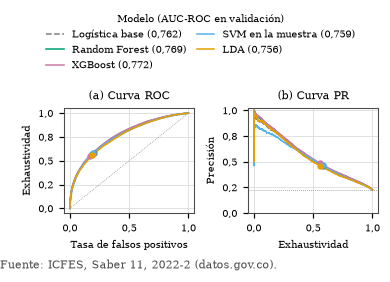

In [35]:
COLOR_CLASE = {"logisticaUmbral": graficos.COLOR_APOYO, **dict(zip(CANDIDATOS_CLASE, graficos.PALETA_CATEGORICA[2:], strict=False))}
prevalencia = y_val_clase.mean()
# Dos paneles al ancho de una columna; la leyenda, común, va encima con el AUC-ROC de cada modelo (el AUC-PR está en la tabla).
figura, (eje_roc, eje_pr) = plt.subplots(1, 2, figsize=(graficos.ANCHO_COLUMNA, 1.65))
for nombre, puntajes in puntajes_validacion.items():
    tasa_fp, tasa_vp, _ = roc_curve(y_val_clase, puntajes)
    precision, exhaustividad, _ = precision_recall_curve(y_val_clase, puntajes)
    # Sin los puntos de exhaustividad cero (el que agrega scikit-learn y los de umbrales sin aciertos), que
    # dibujarían una raya vertical sobre el eje.
    con_aciertos = exhaustividad > 0
    estilo = {"color": COLOR_CLASE[nombre], "linewidth": 1.0, "linestyle": "--" if nombre == "logisticaUmbral" else "-"}
    fila = resultados_clasificacion[nombre]
    eje_roc.plot(tasa_fp, tasa_vp, label=f"{ETIQUETA_CORTA[nombre]} ({en_espanol(fila['auc validación'], 3)})", **estilo)
    eje_pr.plot(exhaustividad[con_aciertos], precision[con_aciertos], **estilo)
    predicho = puntajes >= umbrales[nombre]
    eje_roc.scatter((predicho & (y_val_clase == 0)).sum() / (y_val_clase == 0).sum(), fila["recall validación"], color=COLOR_CLASE[nombre], s=10, zorder=3)
    eje_pr.scatter(fila["recall validación"], fila["precision validación"], color=COLOR_CLASE[nombre], s=10, zorder=3)
eje_roc.plot([0, 1], [0, 1], color=graficos.COLOR_APOYO, linewidth=0.5, linestyle=":")
eje_pr.axhline(prevalencia, color=graficos.COLOR_APOYO, linewidth=0.5, linestyle=":")
eje_roc.set(xlabel="Tasa de falsos positivos", ylabel="Exhaustividad", title="(a) Curva ROC")
eje_pr.set(xlabel="Exhaustividad", ylabel="Precisión", title="(b) Curva PR", ylim=(0, 1.02))
for eje in (eje_roc, eje_pr):
    eje.xaxis.set_major_formatter(graficos.formato_fijo(1))
    eje.yaxis.set_major_formatter(graficos.formato_fijo(1))
figura.tight_layout(w_pad=1.0)
figura.legend(*eje_roc.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, title="Modelo (AUC-ROC en validación)", handlelength=1.8, columnspacing=1.0)
graficos.anotar_fuente(eje_roc, FUENTE)
figuras.guardar(figura, "clasificacion-curvas")
plt.show()

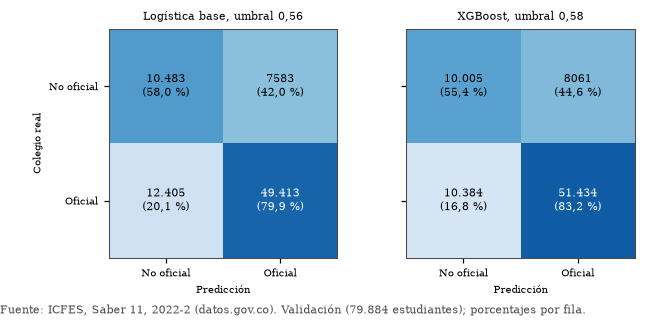

In [36]:
matrices = {nombre: confusion_matrix(y_val_clase, (puntajes_validacion[nombre] >= umbrales[nombre]).astype(int), labels=[1, 0]) for nombre in ("logisticaUmbral", mejor_clasificacion)}
figura, ejes = plt.subplots(1, 2, figsize=(6.4, 2.7))
for eje, (nombre, matriz) in zip(ejes, matrices.items(), strict=True):
    proporcion = matriz / matriz.sum(axis=1, keepdims=True)
    eje.imshow(proporcion, cmap="Blues", vmin=0, vmax=1)
    eje.grid(False)
    for i in range(2):
        for j in range(2):
            eje.text(j, i, f"{en_espanol(int(matriz[i, j]))}\n({en_espanol(100 * proporcion[i, j], 1)} %)", ha="center", va="center", fontsize=7, color="white" if proporcion[i, j] > 0.6 else "black")
    eje.set_xticks([0, 1], ["No oficial", "Oficial"])
    eje.set_yticks([0, 1], ["No oficial", "Oficial"])
    eje.set(xlabel="Predicción", title=f"{ETIQUETA_CORTA[nombre]}, umbral {en_espanol(umbrales[nombre], 2)}")
ejes[0].set_ylabel("Colegio real")
ejes[1].tick_params(labelleft=False)
graficos.anotar_fuente(ejes[0], f"{FUENTE} Validación ({en_espanol(len(y_val_clase))} estudiantes); porcentajes por fila.")
figuras.guardar(figura, "clasificacion-confusion")
plt.show()
matriz_mejor = matrices[mejor_clasificacion]
cifra("verdaderosPositivosMejor", int(matriz_mejor[0, 0]))
cifra("falsosNegativosMejor", int(matriz_mejor[0, 1]))
cifra("falsosPositivosMejor", int(matriz_mejor[1, 0]))
cifra("verdaderosNegativosMejor", int(matriz_mejor[1, 1]))
cifra("noOficialesValidacion", int(matriz_mejor[0].sum()));

**Lectura.** Los cuatro clasificadores quedan muy cerca entre sí y de la logística base. XGBoost tiene el mayor AUC-ROC de validación (0,772, frente a 0,762 de la logística), seguido del Random Forest (0,769), la SVM (0,759, entrenada con 20.000 estudiantes) y el LDA (0,756), que supone normalidad con covarianza común y queda por debajo de la logística. Las curvas ROC casi se superponen; en la PR solo la SVM queda claramente por debajo en la zona de precisión alta. Ninguno sobreajusta de forma apreciable: la mayor brecha de AUC entre las filas de ajuste y validación es la del bosque (0,019). En la búsqueda del bosque, gini y entropía empatan: el mejor AUC de validación cruzada difiere en 0,0009 a favor de gini (13 configuraciones frente a 17), y el AUC medio es algo mayor con entropía (0,749 frente a 0,746). El criterio de división no es lo que limita al modelo.

La exactitud engaña aquí, como advirtió la clase. El `DummyClassifier` que siempre dice «oficial» acierta en el 77,4 % de validación sin encontrar a un solo estudiante de colegio no oficial; la logística base con umbral 0,5 baja a 70,7 % de exactitud y encuentra a dos de cada tres. Con su umbral de F1, XGBoost llega a 76,9 % de exactitud, todavía por debajo del Dummy, con un F1 de la clase no oficial de 0,520 y un AUC-PR de 0,560, frente al 0,226 que daría el azar (la proporción de no oficiales). La matriz de confusión lo concreta: de los 18.066 estudiantes de colegios no oficiales de validación, XGBoost identifica 10.005 (55,4 %) y deja 8061 como oficiales, y marca como no oficiales a 10.384 estudiantes de colegios oficiales (16,8 %). Frente a la logística con su propio umbral, cambia exhaustividad por precisión (de 0,458 a 0,491) y mejora el F1 en 0,008.

Respuesta a S2: el hogar separa los dos tipos de colegio solo en parte. Con el estrato, la educación de los padres, los bienes, el tamaño del hogar, el género y la edad, el mejor modelo ordena bien a un par tomado al azar de un estudiante de colegio oficial y otro de no oficial en el 77 % de los casos, y la ventaja de los ensambles sobre un modelo lineal es de un punto de AUC: la relación entre el hogar y la naturaleza del colegio es casi aditiva. Que un estudiante de hogar acomodado estudie en un colegio oficial, o al revés, es frecuente; la naturaleza del colegio no está determinada por el hogar. Los umbrales se eligieron en validación, así que estas métricas son algo optimistas; la cifra honesta es la de prueba (§22), con el mismo umbral.

## 13. Red neuronal: perceptrón multicapa

El perceptrón multicapa (`saber11.mlp`, en PyTorch) completa la respuesta a S1 con un modelo que aprende interacciones y relaciones no lineales sin árboles. Recibe las mismas 95 columnas que los regularizados, transformadas por su `Pipeline` ya ajustado en entrenamiento (imputación por moda, edad winsorizada, one-hot con las referencias de la fase 2 y numéricas estandarizadas), y aprende el puntaje global estandarizado con la media y la desviación de entrenamiento; sus predicciones vuelven a la escala del puntaje. La arquitectura y el entrenamiento se fijaron antes de ver resultados: dos capas ocultas de 128 y 64 neuronas con ReLU y abandono (*dropout*) de 0,1, Adam con tasa de aprendizaje de 10⁻³, pérdida MSE, lotes de 4.096 estudiantes y hasta 200 épocas. La parada temprana vigila la pérdida de validación: si pasan 10 épocas seguidas sin mejorarla, el entrenamiento se detiene y la red vuelve a los pesos de su mejor época. Corre en precisión simple (fp32) en la GPU.

Para que la red sea reproducible, §0.3 fija `CUBLAS_WORKSPACE_CONFIG` y activa `torch.use_deterministic_algorithms(True)` antes de iniciar CUDA, y `mlp.entrenar` fija la semilla justo antes de crear la red, para que nada de lo que corre antes en el cuaderno cambie su inicialización. La comprobación entrena dos veces unas pocas épocas en la GPU y exige pesos idénticos. El entrenamiento completo se guarda en la caché.

In [37]:
EPOCAS_CONTROL = 3
NOMBRE_MODELO["mlpRegresion"] = "MLP"
SUFIJO_REGRESION["mlpRegresion"] = "Mlp"
preparacion_red = regularizados["ridge"][:-1]
X_red_ent, X_red_val = (preparacion_red.transform(X).to_numpy(dtype=np.float32) for X in (X_entrenamiento, X_validacion))
y_red_ent, y_red_val = (y.to_numpy(dtype=float) for y in (y_ent_regresion, y_val_regresion))
inicio = time.perf_counter()
control_a, control_b = (mlp.entrenar(X_red_ent, y_red_ent, X_red_val, y_red_val, en=DISPOSITIVO, epocas=EPOCAS_CONTROL) for _ in range(2))
segundos_por_epoca = (time.perf_counter() - inicio) / (2 * EPOCAS_CONTROL)
comprobar(
    f"Dos entrenamientos de {EPOCAS_CONTROL} épocas en {DISPOSITIVO} con la misma semilla dan los mismos pesos y las mismas pérdidas",
    control_a.estado.keys() == control_b.estado.keys()
    and all(torch.equal(control_a.estado[c], control_b.estado[c]) for c in control_a.estado)
    and control_a.perdidas_validacion == control_b.perdidas_validacion,
)
del control_a, control_b
# La línea base de memoria va después de la comprobación, que ya reservó el espacio de trabajo
# de cuBLAS (CUBLAS_WORKSPACE_CONFIG); lo que se mide es lo que dejan el entrenamiento y la predicción.
memoria_inicial = torch.cuda.memory_allocated(DISPOSITIVO) if DISPOSITIVO.type == "cuda" else 0

entrenar_red = ajuste.en_cache(mlp.entrenar)
red = entrenar_red(X_red_ent, y_red_ent, X_red_val, y_red_val, en=DISPOSITIVO)


class RedAjustada:
    """El MLP con la preparación que lo alimenta, con el `predict` de los demás modelos de regresión."""

    def __init__(self, preparacion, entrenamiento: mlp.Entrenamiento) -> None:
        self.preparacion = preparacion
        self.entrenamiento = entrenamiento

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        return mlp.predecir(self.entrenamiento, self.preparacion.transform(X).to_numpy(dtype=np.float32), DISPOSITIVO)


red_regresion = RedAjustada(preparacion_red, red)
evaluar_regresion("mlpRegresion", red_regresion, X_entrenamiento, y_ent_regresion)
perdida_restaurada = float(np.mean(((y_red_val - red_regresion.predict(X_validacion)) / red.escala) ** 2))
memoria_final = torch.cuda.memory_allocated(DISPOSITIVO) if DISPOSITIVO.type == "cuda" else 0
del X_red_ent, X_red_val

print(f"Épocas corridas: {red.epocas_corridas} de {mlp.EPOCAS}; mejor época: {red.epoca_mejor}; parámetros: {en_espanol(sum(t.numel() for t in red.estado.values()))}")
print(f"Pérdida de validación en la mejor época: {en_espanol(min(red.perdidas_validacion), 4)}; con los pesos restaurados: {en_espanol(perdida_restaurada, 4)}")
print(f"Tiempo por época en {DISPOSITIVO} ({nombre_gpu}): {en_espanol(segundos_por_epoca, 2)} s")
print(f"Memoria de la GPU ocupada por tensores de PyTorch: {en_espanol(memoria_inicial)} bytes antes del entrenamiento y {en_espanol(memoria_final)} después de predecir")
comprobar(
    "La parada temprana se activó al cumplir la paciencia, o el entrenamiento llegó al máximo de épocas",
    red.epocas_corridas == red.epoca_mejor + mlp.PACIENCIA or red.epocas_corridas == mlp.EPOCAS,
)
comprobar("La red quedó con los pesos de su mejor época (su pérdida de validación es la mínima de la curva)", np.isclose(perdida_restaurada, min(red.perdidas_validacion), rtol=1e-4))
comprobar("Entrenar y predecir con la red no deja tensores en la GPU", memoria_final == memoria_inicial)
cifra("epocaParada", red.epocas_corridas)
cifra("epocaMejorMlp", red.epoca_mejor)
cifra("epocasMaximasMlp", mlp.EPOCAS)
cifra("pacienciaMlp", mlp.PACIENCIA)
cifra("parametrosMlp", sum(t.numel() for t in red.estado.values()))
cifra("perdidaValidacionMlp", min(red.perdidas_validacion), 3)
cifra("medidaEpocaMlpSegundos", segundos_por_epoca, 2);

[ok] Dos entrenamientos de 3 épocas en cuda:1 con la misma semilla dan los mismos pesos y las mismas pérdidas


Épocas corridas: 45 de 200; mejor época: 35; parámetros: 20.609
Pérdida de validación en la mejor época: 0,6214; con los pesos restaurados: 0,6214
Tiempo por época en cuda:1 (NVIDIA GeForce RTX 5080): 0,24 s
Memoria de la GPU ocupada por tensores de PyTorch: 68.157.440 bytes antes del entrenamiento y 68.157.440 después de predecir
[ok] La parada temprana se activó al cumplir la paciencia, o el entrenamiento llegó al máximo de épocas
[ok] La red quedó con los pesos de su mejor época (su pérdida de validación es la mínima de la curva)
[ok] Entrenar y predecir con la red no deja tensores en la GPU


La curva de pérdida muestra, época por época, el error cuadrático medio en entrenamiento y en validación, en la escala estandarizada del objetivo; el eje de la derecha lo traduce a RMSE en puntos. La pérdida de entrenamiento es el promedio de los lotes de cada época, con el abandono activo y mientras los pesos cambian, así que no se compara punto a punto con la de validación, que se mide al final de la época sin abandono. Las líneas punteadas son el error de validación de la múltiple de la fase 2 y del XGBoost ajustado, en la misma escala.

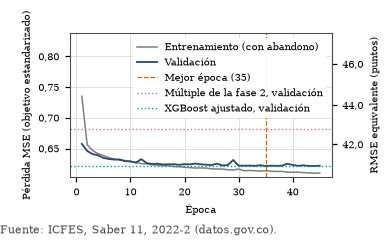

In [38]:
epocas = np.arange(1, red.epocas_corridas + 1)
figura, eje = plt.subplots(figsize=(graficos.ANCHO_COLUMNA, 1.85))
eje.plot(epocas, red.perdidas_entrenamiento, color=graficos.COLOR_APOYO, linewidth=1.0, label="Entrenamiento (con abandono)")
eje.plot(epocas, red.perdidas_validacion, color=graficos.COLOR_PRINCIPAL, linewidth=1.2, label="Validación")
eje.axvline(red.epoca_mejor, color=graficos.PALETA_CATEGORICA[1], linestyle="--", linewidth=0.8, label=f"Mejor época ({red.epoca_mejor})")
for etiqueta, rmse, color in (("Múltiple de la fase 2", rmse_multiple, graficos.PALETA_CATEGORICA[3]), ("XGBoost ajustado", resultados_regresion["xgboostRegresion"]["rmse validación"], graficos.PALETA_CATEGORICA[2])):
    eje.axhline((rmse / red.escala) ** 2, color=color, linestyle=":", linewidth=0.9, label=f"{etiqueta}, validación")
eje.set(xlabel="Época", ylabel="Pérdida MSE (objetivo estandarizado)")
eje.xaxis.set_major_formatter(graficos.FORMATO_MILES)
eje.yaxis.set_major_formatter(graficos.formato_fijo(2))
derecho = eje.secondary_yaxis("right", functions=(lambda m: np.sqrt(np.clip(m, 0, None)) * red.escala, lambda r: (np.asarray(r) / red.escala) ** 2))
derecho.set_ylabel("RMSE equivalente (puntos)")
derecho.yaxis.set_major_formatter(graficos.formato_fijo(1))
# Margen arriba para la leyenda, que así no tapa las líneas de referencia.
inferior, superior = eje.get_ylim()
eje.set_ylim(inferior, superior + 0.7 * (superior - inferior))
eje.legend(loc="upper right", fontsize=6.5, frameon=True, framealpha=0.95, edgecolor="none")
figura.tight_layout()
graficos.anotar_fuente(eje, FUENTE)
figuras.guardar(figura, "mlp-perdida")
plt.show()

La tabla compara la red con la base lineal y con los mejores modelos de §9 y §10, con las mismas métricas en las filas de ajuste y en validación.

In [39]:
frente_a_red = pd.concat([bases_tabla.loc[["Múltiple (base)"]], pd.DataFrame(resultados_regresion).T.rename(index=NOMBRE_MODELO)])
frente_a_red = frente_a_red.loc[["Múltiple (base)", *(NOMBRE_MODELO[n] for n in (mejor_regularizado, "randomForestRegresion", "xgboostRegresion", "mlpRegresion"))]]
frente_a_red["Brecha de RMSE"] = frente_a_red["rmse validación"] - frente_a_red["rmse entrenamiento"]
frente_a_red["RMSE frente a la múltiple"] = frente_a_red["rmse validación"] - rmse_multiple
tabla(frente_a_red.drop(columns="Filas de ajuste"), 3)
rmse_red = resultados_regresion["mlpRegresion"]["rmse validación"]
cifra("brechaRmseMlp", frente_a_red.loc["MLP", "Brecha de RMSE"], 2)
cifra("mejoraRmseMlp", rmse_multiple - rmse_red, 2)
comprobar("El MLP queda a menos de 0,1 puntos de RMSE de XGBoost en validación", abs(rmse_red - resultados_regresion["xgboostRegresion"]["rmse validación"]) < 0.1)
comprobar("La brecha de RMSE del MLP es menor que la de los dos ensambles", frente_a_red.loc["MLP", "Brecha de RMSE"] < frente_a_red.loc[[NOMBRE_MODELO["randomForestRegresion"], NOMBRE_MODELO["xgboostRegresion"]], "Brecha de RMSE"].min())
cifra("diferenciaRmseMlpXgboost", rmse_red - resultados_regresion["xgboostRegresion"]["rmse validación"], 2);

                       r2 entrenamiento rmse entrenamiento mae entrenamiento r2 validación rmse validación mae validación Brecha de RMSE RMSE frente a la múltiple
Múltiple (base)                   0,318             42,803            34,716         0,319          42,811         34,708          0,008                         0
Lasso                             0,318             42,803            34,716         0,319          42,811         34,709          0,008                    -0,000
Random Forest ajustado            0,461             38,058            30,726         0,354          41,676         33,720          3,619                    -1,135
XGBoost ajustado                  0,451             38,398            30,851         0,380          40,836         32,919          2,438                    -1,975
MLP                               0,397             40,240            32,436         0,379          40,858         32,950          0,618                    -1,953
[ok] El MLP queda a me

**Lectura.** La parada temprana actuó en la época 45: la pérdida de validación tocó su mínimo en la 35 (0,621, unos 40,9 puntos de RMSE) y no volvió a bajar en las diez siguientes, así que la red quedó con los pesos de esa época; la comprobación confirma que la pérdida con los pesos restaurados es la mínima de la curva. Casi todo el aprendizaje ocurre en las primeras diez épocas, y después la pérdida de validación oscila en una franja de centésimas, con saltos aislados que se corrigen en la época siguiente. La de entrenamiento sigue bajando hasta el final y la de validación ya no: la red empieza a ajustarse a sus propios datos, y la parada temprana lo corta. Con 20.609 parámetros y 0,26 s por época en la RTX 5080, el entrenamiento completo dura unos 12 segundos.

En validación, el MLP queda prácticamente empatado con XGBoost: RMSE de 40,86 frente a 40,84 puntos (R² de 0,379 frente a 0,380), 1,95 puntos por debajo de la múltiple. Llega ahí por otro camino: su brecha entre entrenamiento y validación es de 0,62 puntos, frente a 2,44 de XGBoost y 3,62 del Random Forest, porque la parada temprana y el abandono lo detienen antes de memorizar. Que dos modelos tan distintos coincidan en unos 40,8 puntos sugiere que ese es el techo de lo que estas 19 variables dicen del puntaje global: para S1, lo que falta no es capacidad del modelo sino información sobre el estudiante y su colegio que el Saber 11 no recoge.

## 14. Interpretabilidad: SHAP y permutación

La importancia de las variables se mide sobre el mejor modelo de árboles de §10.4, XGBoost, con dos métodos que responden preguntas distintas. SHAP reparte cada predicción entre las variables: la contribución de una variable es lo que, en promedio sobre los órdenes posibles de entrada, cambia la predicción al conocer su valor, y las contribuciones de un estudiante más un valor base suman exactamente su predicción. `TreeExplainer` las calcula de forma exacta para los árboles. La permutación mide otra cosa: cuánto empeora el RMSE si se baraja una variable y se rompe su relación con el puntaje (5 repeticiones). Los dos se expresan por variable original: las contribuciones SHAP de las columnas codificadas (los niveles del one-hot y el indicador de faltante) se suman en su variable, y la permutación baraja la columna antes del `Pipeline`, así que mueve a la vez la variable y su indicador.

Los dos corren sobre 10.000 estudiantes de validación, elegidos al azar con estratificación por naturaleza del colegio, como la partición, y nunca sobre la prueba: describen el modelo ya elegido y no estiman su error. La correlación de Spearman entre los dos ordenamientos dice si coinciden en qué variables pesan más.

In [40]:
FILAS_INTERPRETACION = 10_000
comprobar("El mejor modelo de árboles en validación es XGBoost, el que explican SHAP y la permutación", mejor_ensamble == "xgboostRegresion")
elegidas, _ = train_test_split(np.arange(len(X_validacion)), train_size=FILAS_INTERPRETACION, stratify=y_validacion[v.OBJETIVO_CLASIFICACION], random_state=ajuste.SEMILLA)
elegidas = np.sort(elegidas)
X_interpretacion, y_interpretacion = X_validacion.iloc[elegidas], y_val_regresion.iloc[elegidas]
codificado = xgboost_regresion[:-1].transform(X_interpretacion)
contribuciones = interpretabilidad.contribuciones_shap(xgboost_regresion.named_steps["modelo"], codificado)
shap_por_variable = interpretabilidad.por_variable(contribuciones, PREDICTORES)
valor_base = xgboost_regresion.predict(X_interpretacion) - contribuciones.sum(axis=1).to_numpy()
comprobar("SHAP es aditivo: las contribuciones más un valor base constante reproducen cada predicción (a 0,01 puntos)", float(np.ptp(valor_base)) < 0.01)
comprobar("Sumar por variable original conserva la contribución total de cada estudiante", np.allclose(shap_por_variable.sum(axis=1), contribuciones.sum(axis=1), atol=1e-3))
importancia_shap = interpretabilidad.importancia_media(shap_por_variable)

inicio = time.perf_counter()
permutada = interpretabilidad.permutacion(xgboost_regresion, X_interpretacion, y_interpretacion, ajuste.PUNTUACION["regresion"])
segundos_permutacion = time.perf_counter() - inicio
comprobar("SHAP y la permutación miden las mismas variables originales, las 19 predictoras", set(importancia_shap.index) == set(permutada.index) == set(PREDICTORES))
rho_importancias = interpretabilidad.spearman(importancia_shap, permutada["importancia"])
ranking = pd.DataFrame({
    "SHAP (puntos)": importancia_shap,
    "Puesto SHAP": importancia_shap.rank(ascending=False, method="min"),
    "Permutación (puntos)": permutada["importancia"],
    "Desviación": permutada["desviacion"],
    "Puesto permutación": permutada["importancia"].rank(ascending=False, method="min"),
}).loc[importancia_shap.index]
tabla(ranking.rename(index=ETIQUETA_VARIABLE), 2)
print(f"\nValor base de SHAP: {en_espanol(float(np.mean(valor_base)), 2)} puntos; Spearman entre los dos ordenamientos: {en_espanol(rho_importancias, 3)}")
print(f"Permutación: {en_espanol(segundos_permutacion, 1)} s")
ORDINALES = ("Primera", "Segunda", "Tercera")
comprobar("La edad y el departamento encabezan los dos ordenamientos", set(importancia_shap.index[:2]) == set(permutada.index[:2]) == {v.EDAD, v.DEPARTAMENTO})
for puesto, variable in zip(ORDINALES, importancia_shap.index, strict=False):
    cifra(f"variableShap{puesto}", ETIQUETA_VARIABLE[variable])
    cifra(f"importanciaShap{puesto}", importancia_shap[variable], 1)
for puesto, variable in zip(ORDINALES, permutada.index, strict=False):
    cifra(f"variablePermutacion{puesto}", ETIQUETA_VARIABLE[variable])
    cifra(f"aumentoRmsePermutacion{puesto}", permutada.loc[variable, "importancia"], 2)
cifra("spearmanShapPermutacion", rho_importancias, 3)
cifra("valorBaseShap", float(np.mean(valor_base)), 1)
cifra("filasInterpretacion", FILAS_INTERPRETACION)
cifra("repeticionesPermutacion", interpretabilidad.REPETICIONES_PERMUTACION);

[ok] El mejor modelo de árboles en validación es XGBoost, el que explican SHAP y la permutación


[ok] SHAP es aditivo: las contribuciones más un valor base constante reproducen cada predicción (a 0,01 puntos)
[ok] Sumar por variable original conserva la contribución total de cada estudiante


[ok] SHAP y la permutación miden las mismas variables originales, las 19 predictoras
                      SHAP (puntos) Puesto SHAP Permutación (puntos) Desviación Puesto permutación
Edad                           9,80           1                 3,03       0,12                  1
Departamento                   6,98           2                 3,02       0,13                  2
Computador                     5,59           3                 0,83       0,06                  9
Naturaleza                     4,73           4                 1,66       0,07                  4
Jornada                        4,59           5                 2,34       0,07                  3
Educación de la madre          4,40           6                 1,12       0,05                  6
Género                         3,86           7                 0,57       0,04                 12
Educación del padre            3,79           8                 0,97       0,07                  7
Cuartos                 

La figura pone los dos ordenamientos lado a lado, con las variables en el orden de SHAP: a la izquierda, la contribución absoluta media; a la derecha, el aumento medio del RMSE al barajar cada variable, con su desviación entre repeticiones.

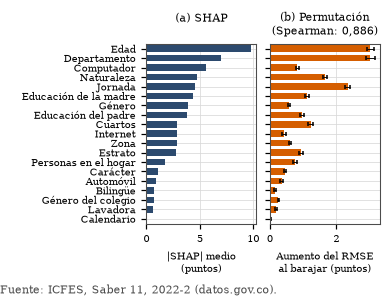

In [41]:
orden_variables = list(importancia_shap.index[::-1])
posiciones = np.arange(len(orden_variables))
figura, (eje_shap, eje_permutacion) = plt.subplots(1, 2, figsize=(graficos.ANCHO_COLUMNA, 2.6), sharey=True)
eje_shap.barh(posiciones, importancia_shap.loc[orden_variables], color=graficos.COLOR_PRINCIPAL, height=0.7)
eje_permutacion.barh(
    posiciones, permutada.loc[orden_variables, "importancia"], xerr=permutada.loc[orden_variables, "desviacion"],
    color=graficos.PALETA_CATEGORICA[1], height=0.7, error_kw={"elinewidth": 0.6, "capsize": 1.5},
)
eje_shap.set_yticks(posiciones, [ETIQUETA_VARIABLE[x] for x in orden_variables], fontsize=6.5)
# El título de (a) lleva una línea en blanco para alinearse con el de (b), que ocupa dos.
eje_shap.set(xlabel="|SHAP| medio\n(puntos)", title="(a) SHAP\n")
eje_permutacion.set(xlabel="Aumento del RMSE\nal barajar (puntos)", title=f"(b) Permutación\n(Spearman: {en_espanol(rho_importancias, 3)})")
for eje in (eje_shap, eje_permutacion):
    eje.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
    eje.margins(y=0.01)
figura.tight_layout(w_pad=0.6)
graficos.anotar_fuente(eje_shap, FUENTE)
figuras.guardar(figura, "importancia-variables")
plt.show()

**Lectura.** Los dos métodos coinciden en lo grueso (Spearman de 0,886) y en las dos primeras variables: la edad y el departamento. La edad es la que más mueve las predicciones (9,8 puntos de contribución absoluta media) y la que más empeora el RMSE al barajarla (3,0 puntos); el departamento la sigue de cerca en la permutación (3,0) aunque su contribución media es menor (7,0). Después se separan. El computador es la tercera en SHAP (5,6) y la novena en la permutación (0,8): está asociado con el internet, el estrato y la educación de los padres, y SHAP le asigna parte del efecto que comparten, mientras que al barajarlo el modelo lo suple con esas otras variables. La jornada hace el camino contrario (quinta en SHAP y tercera en la permutación): barajarla cuesta más de lo que su contribución media haría pensar, señal de que las demás variables no la sustituyen. El estrato queda duodécimo en SHAP y octavo en la permutación: con el departamento, la naturaleza del colegio, los bienes del hogar y la educación de los padres en el modelo, le queda poco que aportar por sí solo, porque comparte con ellas buena parte de lo que dice del hogar. En los dos métodos, importante quiere decir que el modelo usa la variable con las demás presentes; no dice que la variable cause el puntaje.

Una importancia media no dice en qué sentido empuja cada nivel. La figura siguiente da, para las cinco variables con mayor importancia SHAP, la contribución media de cada nivel a la predicción, en puntos y frente al valor base: positiva, el modelo sube la predicción de quienes tienen ese nivel; negativa, la baja. La edad va en años cumplidos. Solo aparecen los niveles con 10 o más estudiantes en la muestra, y ninguna barra es un estudiante.

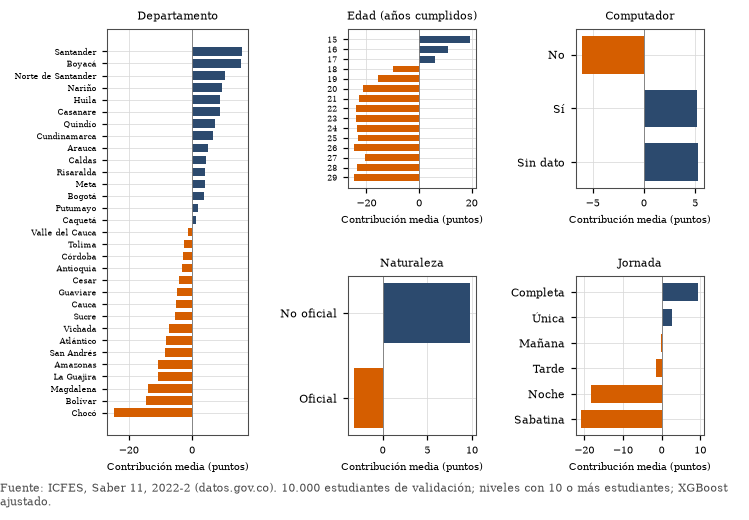

Edad: 15 niveles con 10 o más estudiantes
      n media
15   77  19,5
16 2195  11,1
17 4249   6,0
18 2063  -9,8
19  824 -15,5
20  225 -21,3
21   90 -22,9
22   45 -23,9
23   37 -23,9
24   19 -23,6
25   21 -23,0
26   14 -24,6
27   14 -20,6
28   14 -23,6
29   11 -24,8
Departamento: 31 niveles con 10 o más estudiantes
                      n media
Santander           481  15,8
Boyacá              304  15,4
Norte de Santander  284  10,3
Nariño              322   9,4
Huila               264   9,0
Casanare             94   8,8
Quindío             103   7,3
Cundinamarca        659   6,6
Arauca               66   5,2
Caldas              196   4,4
Risaralda           181   4,3
Meta                239   4,2
Bogotá             1411   3,9
Putumayo             73   2,0
Caquetá              77   1,1
Valle del Cauca     742  -1,4
Tolima              280  -2,7
Córdoba             448  -3,0
Antioquia          1353  -3,0
Cesar               252  -4,1
Guaviare             18  -4,7
Cauca               270 

In [42]:
VARIABLES_POR_NIVEL = list(importancia_shap.index[:5])
def niveles(variable: str, X: pd.DataFrame) -> pd.Series:
    """Nivel de cada estudiante como texto: la edad en años cumplidos y, en las demás, la categoría; los faltantes, «Sin dato»."""
    if variable == v.EDAD:
        return np.floor(X[variable]).map(lambda edad: SIN_DATO if pd.isna(edad) else str(int(edad)))
    return X[variable].astype(object).fillna(SIN_DATO)


def en_orden(tabla_niveles: pd.DataFrame, variable: str, columna: str) -> pd.DataFrame:
    """Niveles en el orden de su escala (la edad, de menor a mayor) y, los demás, de mayor a menor según `columna`."""
    if variable == v.EDAD:
        escala = sorted((n for n in tabla_niveles.index if n.isdigit()), key=int)
    else:
        escala = [n for n in v.ESCALAS.get(variable, ()) if n in tabla_niveles.index]
    return pd.concat([tabla_niveles.loc[escala], tabla_niveles.drop(index=escala).sort_values(columna, ascending=False)])


medias_shap = {
    variable: en_orden(interpretabilidad.media_por_categoria(shap_por_variable[variable], niveles(variable, X_interpretacion)), variable, "media")
    for variable in VARIABLES_POR_NIVEL
}
mas_niveles = max(medias_shap, key=lambda x: len(medias_shap[x]))
figura = plt.figure(figsize=(7.0, 4.8))
rejilla = figura.add_gridspec(2, 3, width_ratios=[1.1, 1, 1], hspace=0.55, wspace=0.75)
ejes_por_variable = {mas_niveles: figura.add_subplot(rejilla[:, 0])}
for i, variable in enumerate(x for x in medias_shap if x != mas_niveles):
    ejes_por_variable[variable] = figura.add_subplot(rejilla[i // 2, 1 + i % 2])
for variable, eje in ejes_por_variable.items():
    filas = medias_shap[variable].iloc[::-1]
    eje.barh(np.arange(len(filas)), filas["media"], color=[graficos.COLOR_PRINCIPAL if m >= 0 else graficos.PALETA_CATEGORICA[1] for m in filas["media"]], height=0.7)
    eje.set_yticks(np.arange(len(filas)), [nivel_legible(variable, n) for n in filas.index], fontsize=5.5 if len(filas) > 12 else 7)
    eje.axvline(0, color=graficos.COLOR_APOYO, linewidth=0.6)
    eje.set(title=ETIQUETA_VARIABLE[variable] + (" (años cumplidos)" if variable == v.EDAD else ""), xlabel="Contribución media (puntos)")
    eje.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
graficos.anotar_fuente(ejes_por_variable[mas_niveles], f"{FUENTE} {en_espanol(FILAS_INTERPRETACION)} estudiantes de validación; niveles con 10 o más estudiantes; XGBoost ajustado.")
figuras.guardar(figura, "shap-por-categoria")
plt.show()
for variable, medias in medias_shap.items():
    print(f"{ETIQUETA_VARIABLE[variable]}: {len(medias)} niveles con 10 o más estudiantes")
    tabla(medias.rename(index=lambda n, x=variable: nivel_legible(x, n)), 1)
comprobar("Los niveles de las medias SHAP tienen 10 o más estudiantes", all((m["n"] >= interpretabilidad.MINIMO_POR_GRUPO).all() for m in medias_shap.values()))
edades = medias_shap[v.EDAD]["media"].drop(index=SIN_DATO, errors="ignore")
comprobar("La contribución de la edad es positiva hasta los 17 años y negativa desde los 18", (edades[[int(n) <= 17 for n in edades.index]] > 0).all() and (edades[[int(n) >= 18 for n in edades.index]] < 0).all())

**Lectura.** Las contribuciones dicen en qué sentido empuja cada nivel, siempre con las demás variables presentes. La edad es la más marcada: a los 15 y 16 años el modelo sube la predicción (19,5 y 11,1 puntos) y desde los 18 la baja con fuerza (-9,8 a los 18, -15,5 a los 19 y entre -21 y -25 desde los 20). Quien presenta el Saber 11 con 18 años o más suele venir de repetir grados o de interrumpir sus estudios (extraedad), y el modelo lo registra como una desventaja que el hogar no explica. La jornada apunta a lo mismo: la nocturna y la sabatina, que atienden sobre todo la educación de jóvenes y adultos, restan 18,3 y 20,7 puntos, y la completa suma 9,5. Entre los departamentos, Santander y Boyacá suman unos 15 puntos, Chocó resta 24,8 y Bolívar y Magdalena, unos 14: una brecha territorial que el modelo atribuye al departamento además de lo que explican el hogar y el colegio. Estudiar en un colegio no oficial suma 9,8 puntos y en uno oficial resta 3,2; tener computador suma 5,2 y no tenerlo resta 6,1 (quienes no respondieron se parecen a quienes sí lo tienen). Para las secretarías de educación, el rezago escolar y el territorio son señales de alerta tan claras como el nivel socioeconómico del hogar.

Como pide el cuadernillo de la clase, la última pregunta es cuánto del poder predictivo se conserva con pocas variables. XGBoost se vuelve a entrenar con la configuración elegida en §10.3, sobre todo el entrenamiento, solo con las 3 y con las 4 variables de mayor importancia SHAP, y se mide su R² en validación frente al del modelo con las 19.

In [43]:
diferencias_cpu_reducido: list[float] = []


def xgboost_con(predictores: tuple[str, ...]):
    """XGBoost con la configuración de §10.3, entrenado en la GPU solo con `predictores`; predice en la CPU."""
    tuberia = ajustado(modelos.pipeline(predictores, clone(mejores_regresion["xgboostRegresion"].named_steps["modelo"])), X_entrenamiento, y_ent_regresion).modelo
    diferencias_cpu_reducido.append(predecir_en_cpu(tuberia))
    return tuberia


r2_completo = resultados_regresion["xgboostRegresion"]["r2 validación"]
filas_reducidas = {}
for k in (3, 4):
    r2 = interpretabilidad.r2_con_las_mas_importantes(xgboost_con, importancia_shap, k, (X_validacion, y_val_regresion))
    variables_k = ", ".join(ETIQUETA_VARIABLE[x] for x in interpretabilidad.mas_importantes(importancia_shap, k))
    filas_reducidas[k] = {"Variables": variables_k, "R² validación": r2, "Parte del R² completo": r2 / r2_completo}
filas_reducidas[len(PREDICTORES)] = {"Variables": "todas", "R² validación": r2_completo, "Parte del R² completo": 1.0}
reducidos = pd.DataFrame(filas_reducidas).T.rename_axis("Variables usadas")
tabla(reducidos, 3)
comprobar("La predicción en la CPU de los XGBoost reducidos coincide con la de la GPU a menos de 0,01 puntos", max(diferencias_cpu_reducido) < 0.01)
for k, nombre in ((3, "Tres"), (4, "Cuatro")):
    cifra(f"rCuadradoMasImportantes{nombre}", reducidos.loc[k, "R² validación"], 3)
    cifra(f"parteRCuadradoMasImportantes{nombre}", 100 * reducidos.loc[k, "Parte del R² completo"], 0)
    cifra(f"variablesMasImportantes{nombre}", reducidos.loc[k, "Variables"]);

                                                  Variables R² validación Parte del R² completo
Variables usadas                                                                               
3                            Edad, Departamento, Computador         0,229                 0,603
4                Edad, Departamento, Computador, Naturaleza         0,266                 0,699
19                                                    todas         0,380                     1
[ok] La predicción en la CPU de los XGBoost reducidos coincide con la de la GPU a menos de 0,01 puntos


**Lectura.** Con solo la edad, el departamento y el computador, XGBoost conserva un R² de 0,229, el 60 % del que logra con las 19 variables (0,380); al sumar la naturaleza del colegio llega a 0,266, el 70 %. El 30 % restante se reparte entre quince variables, ninguna decisiva por sí sola: la jornada, la educación de los padres, el estrato y los bienes dicen cosas parecidas sobre el hogar y se sustituyen entre sí. Para una secretaría de educación, esto quiere decir que la edad del estudiante, el territorio y el acceso a un computador ya señalan buena parte de las diferencias de puntaje que el modelo alcanza a explicar.

## 15. Análisis de errores por grupo

El error global puede esconder grupos donde el modelo falla más. Esta sección lo desagrega en validación (la prueba ya no se toca hasta §22) para los dos mejores modelos: los residuos de XGBoost en la regresión (observado menos predicho: positivo, el modelo subestima) y los errores de XGBoost en la clasificación, con su umbral. Los grupos son el estrato, la zona, la naturaleza del colegio y el departamento; en la clasificación, la naturaleza es la clase que se predice, así que su error por grupo es la matriz de confusión de §12.3. Las tablas solo dejan grupos con 10 o más estudiantes y los faltantes van como «Sin dato».

In [44]:
GRUPOS_REGRESION = {v.ESTRATO: "Estrato", "COLE_AREA_UBICACION": "Zona", "COLE_NATURALEZA": "Naturaleza", v.DEPARTAMENTO: "Departamento"}
GRUPOS_CLASIFICACION = {v.ESTRATO: "Estrato", "COLE_AREA_UBICACION": "Zona", v.DEPARTAMENTO: "Departamento"}
NEGATIVA = "OFICIAL"
comprobar("La clase de validación solo toma los valores «NO OFICIAL» y «OFICIAL»", set(y_validacion[v.OBJETIVO_CLASIFICACION].unique()) == {POSITIVA, NEGATIVA})


prediccion_xgboost_validacion = xgboost_regresion.predict(X_validacion)
clase_predicha = np.where(puntajes_validacion["xgboostClasificacion"] >= umbrales["xgboostClasificacion"], POSITIVA, NEGATIVA)
errores_reg_por_grupo = {
    variable: en_orden(interpretabilidad.errores_regresion(y_val_regresion, prediccion_xgboost_validacion, niveles(variable, X_validacion)), variable, "rmse")
    for variable in GRUPOS_REGRESION
}
errores_clase_por_grupo = {
    variable: en_orden(interpretabilidad.errores_clasificacion(y_validacion[v.OBJETIVO_CLASIFICACION], clase_predicha, niveles(variable, X_validacion)), variable, "error")
    for variable in GRUPOS_CLASIFICACION
}
rmse_xgboost = resultados_regresion["xgboostRegresion"]["rmse validación"]
for variable, nombre in GRUPOS_REGRESION.items():
    print(f"Regresión, XGBoost, por {nombre.lower()}:")
    tabla(errores_reg_por_grupo[variable].rename(index=lambda n, x=variable: nivel_legible(x, n)), 2)
    print()
for variable, nombre in GRUPOS_CLASIFICACION.items():
    print(f"Clasificación, XGBoost, por {nombre.lower()}:")
    errores = errores_clase_por_grupo[variable].rename(index=lambda n, x=variable: nivel_legible(x, n))
    tabla(errores.astype(object).where(errores.notna(), "n. d."), 3)
    print()
print("n. d.: el grupo no tiene estudiantes de esa clase en validación.")
comprobar(
    "Los grupos de los errores tienen 10 o más estudiantes",
    all((t["n"] >= interpretabilidad.MINIMO_POR_GRUPO).all() for t in (*errores_reg_por_grupo.values(), *errores_clase_por_grupo.values())),
)
comprobar(
    "El RMSE de los grupos de estrato, combinado, reproduce el RMSE de validación de XGBoost",
    errores_reg_por_grupo[v.ESTRATO]["n"].sum() == len(X_validacion)
    and np.isclose(np.sqrt((errores_reg_por_grupo[v.ESTRATO]["n"] * errores_reg_por_grupo[v.ESTRATO]["rmse"] ** 2).sum() / len(X_validacion)), rmse_xgboost),
)

[ok] La clase de validación solo toma los valores «NO OFICIAL» y «OFICIAL»


Regresión, XGBoost, por estrato:
                 n residuo_medio  rmse   mae
Estrato 1   21.902         -0,14 40,21 32,53
Estrato 2   26.848          0,01 41,12 33,28
Estrato 3   16.562          0,25 41,92 33,89
Estrato 4     4168          1,06 41,50 33,15
Estrato 5     1304         -1,33 41,46 32,43
Estrato 6      580          0,74 40,52 31,97
Sin dato      5534         -0,09 39,92 31,87
Sin estrato   2986          0,81 37,11 29,18

Regresión, XGBoost, por zona:
            n residuo_medio  rmse   mae
Urbano 66.224          0,05 41,58 33,61
Rural  13.660          0,20 37,00 29,57

Regresión, XGBoost, por naturaleza:
                n residuo_medio  rmse   mae
No oficial 18.066          0,14 42,37 34,11
Oficial    61.818          0,06 40,38 32,57

Regresión, XGBoost, por departamento:
                        n residuo_medio  rmse   mae
Valle del Cauca      5924         -0,10 43,17 35,12
Norte de Santander   2455         -1,50 43,03 34,94
Santander            3745          0,24 42,84 3

La primera figura, la del informe, resume las tablas: a la izquierda, el RMSE de la regresión por estrato, zona y naturaleza, como puntos unidos a la línea del RMSE global para que se vea cuánto se apartan de él; a la derecha, las dos tasas de error de la clasificación por estrato y zona (no oficiales tomados por oficiales y oficiales tomados por no oficiales), como porcentaje de su clase real. «Sin estrato» son los hogares que declararon no tener estrato y «Sin dato», los que no respondieron. La segunda figura da el RMSE por departamento, con los 33 nombres; queda en el cuaderno, porque a la letra de impresión no cabe en una columna, y el informe cita sus extremos.

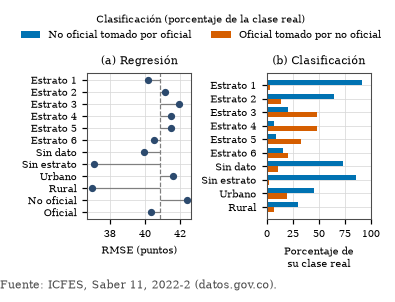

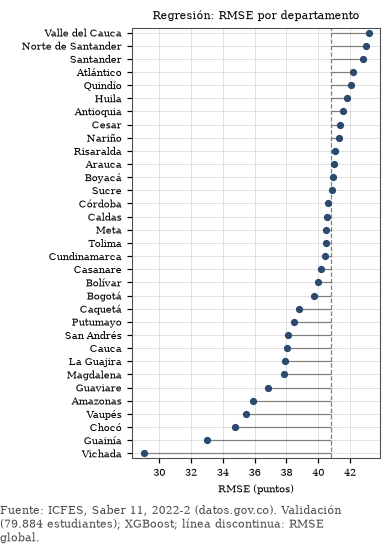

[ok] Los RMSE de los estratos 1 a 6 quedan a menos de 2 puntos del global, y el del grupo sin estrato, por debajo de todos ellos


In [45]:
COLOR_FN, COLOR_FP = graficos.PALETA_CATEGORICA[0], graficos.PALETA_CATEGORICA[1]


def filas_apiladas(tablas: dict[str, pd.DataFrame], variables: list[str]) -> pd.DataFrame:
    """Une las tablas de varias variables con la etiqueta legible de cada nivel, en orden de arriba abajo."""
    return pd.concat([tablas[x].rename(index=lambda n, y=x: nivel_legible(y, n)) for x in variables])


def puntos_frente_al_global(eje: plt.Axes, rmse: pd.Series, tamano_letra: float) -> None:
    """RMSE de cada grupo como un punto unido a la línea del RMSE global, de arriba abajo en el orden recibido."""
    filas = rmse.iloc[::-1]
    posiciones_grupo = np.arange(len(filas))
    eje.hlines(posiciones_grupo, rmse_xgboost, filas, color=graficos.COLOR_APOYO, linewidth=0.8)
    eje.scatter(filas, posiciones_grupo, color=graficos.COLOR_PRINCIPAL, s=14, zorder=3)
    eje.axvline(rmse_xgboost, color=graficos.COLOR_APOYO, linestyle="--", linewidth=0.8)
    eje.set_yticks(posiciones_grupo, filas.index, fontsize=tamano_letra)
    eje.set(xlabel="RMSE (puntos)")


figura, (eje_reg, eje_clase) = plt.subplots(1, 2, figsize=(graficos.ANCHO_COLUMNA, 2.15))
puntos_frente_al_global(eje_reg, filas_apiladas(errores_reg_por_grupo, [v.ESTRATO, "COLE_AREA_UBICACION", "COLE_NATURALEZA"])["rmse"], 6.5)
eje_reg.set_title("(a) Regresión")
apiladas_clase = filas_apiladas(errores_clase_por_grupo, [v.ESTRATO, "COLE_AREA_UBICACION"]).iloc[::-1]
posiciones = np.arange(len(apiladas_clase))
eje_clase.barh(posiciones + 0.19, 100 * apiladas_clase["falsos_negativos"], height=0.38, color=COLOR_FN, label="No oficial tomado por oficial")
eje_clase.barh(posiciones - 0.19, 100 * apiladas_clase["falsos_positivos"], height=0.38, color=COLOR_FP, label="Oficial tomado por no oficial")
eje_clase.set_yticks(posiciones, apiladas_clase.index)
eje_clase.set(xlabel="Porcentaje de\nsu clase real", title="(b) Clasificación", xlim=(0, 100), xticks=range(0, 101, 25))
for eje in (eje_reg, eje_clase):
    eje.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
figura.tight_layout(w_pad=1.0)
figura.legend(*eje_clase.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=2, title="Clasificación (porcentaje de la clase real)")
graficos.anotar_fuente(eje_clase, FUENTE)
figuras.guardar(figura, "errores-por-grupo")
plt.show()

departamentos = errores_reg_por_grupo[v.DEPARTAMENTO].sort_values("rmse", ascending=False)
figura, eje_depto = plt.subplots(figsize=(graficos.ANCHO_COLUMNA, 4.6))
puntos_frente_al_global(eje_depto, departamentos["rmse"].rename(index=lambda n: nivel_legible(v.DEPARTAMENTO, n)), 6.5)
eje_depto.set_title("Regresión: RMSE por departamento")
eje_depto.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_depto.margins(y=0.01)
figura.tight_layout()
graficos.anotar_fuente(eje_depto, f"{FUENTE} Validación ({en_espanol(len(X_validacion))} estudiantes); XGBoost; línea discontinua: RMSE global.")
figuras.guardar(figura, "errores-por-departamento")
plt.show()

por_estrato = errores_reg_por_grupo[v.ESTRATO].loc[list(v.ESTRATOS)]
cifra("rmseEstratoUno", por_estrato.loc["Estrato 1", "rmse"], 1)
cifra("rmseEstratoSeis", por_estrato.loc["Estrato 6", "rmse"], 1)
cifra("rmseSinEstrato", errores_reg_por_grupo[v.ESTRATO].loc[limpieza.SIN_ESTRATO, "rmse"], 1)
comprobar(
    "Los RMSE de los estratos 1 a 6 quedan a menos de 2 puntos del global, y el del grupo sin estrato, por debajo de todos ellos",
    (abs(por_estrato["rmse"] - rmse_xgboost) < 2).all() and errores_reg_por_grupo[v.ESTRATO].loc[limpieza.SIN_ESTRATO, "rmse"] < por_estrato["rmse"].min(),
)
cifra("residuoEstratoSeis", por_estrato.loc["Estrato 6", "residuo_medio"], 1)
for variable, nivel, clave in (("COLE_AREA_UBICACION", "RURAL", "Rural"), ("COLE_AREA_UBICACION", "URBANO", "Urbano"), ("COLE_NATURALEZA", "OFICIAL", "Oficial"), ("COLE_NATURALEZA", "NO OFICIAL", "NoOficial")):
    cifra(f"rmse{clave}", errores_reg_por_grupo[variable].loc[nivel, "rmse"], 1)
    cifra(f"residuo{clave}", errores_reg_por_grupo[variable].loc[nivel, "residuo_medio"], 1)
for extremo, fila in (("Mayor", departamentos.iloc[0]), ("Menor", departamentos.iloc[-1])):
    cifra(f"departamentoRmse{extremo}", nivel_legible(v.DEPARTAMENTO, fila.name))
    cifra(f"rmseDepartamento{extremo}", fila["rmse"], 1)
clase_estrato = errores_clase_por_grupo[v.ESTRATO].loc[list(v.ESTRATOS)]
for nivel, clave in (("Estrato 1", "Uno"), ("Estrato 6", "Seis")):
    cifra(f"falsosNegativosEstrato{clave}", 100 * clase_estrato.loc[nivel, "falsos_negativos"], 1)
    cifra(f"falsosPositivosEstrato{clave}", 100 * clase_estrato.loc[nivel, "falsos_positivos"], 1)
cifra("departamentosConErrores", len(departamentos));

**Lectura.** En la regresión, el error se reparte de forma pareja. Por estrato, el RMSE va de 37,1 (sin estrato) a 41,9 puntos (estrato 3) y el residuo medio de ningún estrato pasa de 1,4 puntos en valor absoluto: el modelo no subestima ni sobrestima de forma sistemática a ningún nivel socioeconómico. Las diferencias de RMSE siguen sobre todo la dispersión del puntaje en cada grupo: es menor en la zona rural (37,0 frente a 41,6 en la urbana) y en departamentos con puntajes más homogéneos, como Vichada (29,0), Guainía (33,0) y Chocó (34,8), y mayor en Valle del Cauca (43,2), Norte de Santander (43,0) y Santander (42,8). Un RMSE menor allí no quiere decir que el modelo explique mejor esos departamentos, sino que hay menos variación que explicar. Los residuos medios más grandes por departamento (Vaupés, -7,1, y San Andrés, -5,1) son de grupos de menos de 100 estudiantes.

En la clasificación el patrón es otro, y responde a S2 con más precisión que el AUC. El modelo se apoya en el hogar como lo haría una regla por estrato: en el estrato 1 toma por oficiales al 91,3 % de los estudiantes de colegios no oficiales y casi no se equivoca con los oficiales (2,6 %), y en los estratos 3 y 4 hace lo contrario: marca como no oficiales a cerca de la mitad de los estudiantes de colegios oficiales (48,1 % y 48,5 %). Los errores se concentran donde el hogar y la naturaleza del colegio no coinciden con lo típico: estudiantes de estrato bajo en colegios privados y de estrato medio en colegios públicos, que son muchos. Para las secretarías de educación, esto dice que el colegio oficial no atiende solo a los hogares más pobres: en los estratos medios convive con el privado, y la naturaleza del colegio no se infiere del hogar.

## 16. Análisis de componentes principales

El análisis multivariante responde S3 con los puntajes de las cinco áreas (lectura crítica, matemáticas, ciencias naturales, sociales y ciudadanas, e inglés) de los estudiantes de entrenamiento que tienen las cinco. Cada área se estandariza con su media y su desviación de entrenamiento, para que ninguna pese más por su escala, y el puntaje global queda fuera porque es una combinación lineal de las cinco. La validación y la prueba no se usan en esta parte. El PCA (`segmentacion.pca`) orienta cada componente para que la suma de sus cargas sea positiva: un valor alto del primer componente quiere decir puntajes altos.

In [46]:
AREAS = list(segmentacion.AREAS)
AREA_LEGIBLE = {
    "PUNT_LECTURA_CRITICA": "Lectura crítica", "PUNT_MATEMATICAS": "Matemáticas", "PUNT_C_NATURALES": "Ciencias naturales",
    "PUNT_SOCIALES_CIUDADANAS": "Sociales y ciudadanas", "PUNT_INGLES": "Inglés",
}
# Nombre de cada área en las claves de las cifras.
AREA_CLAVE = {"PUNT_LECTURA_CRITICA": "lectura", "PUNT_MATEMATICAS": "matematicas", "PUNT_C_NATURALES": "naturales", "PUNT_SOCIALES_CIUDADANAS": "sociales", "PUNT_INGLES": "ingles"}
EN_LETRAS = ("Cero", "Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis", "Siete", "Ocho", "Nueve", "Diez")
COMPONENTES = [f"Componente {j}" for j in range(1, len(AREAS) + 1)]


def en_letras(numero: int) -> str:
    """Número en letras para las claves de las cifras, que solo admiten letras."""
    return EN_LETRAS[int(numero)]


con_cinco_areas = limpio.loc[es_ent, AREAS].notna().all(axis=1)
areas_entrenamiento = limpio.loc[es_ent, AREAS][con_cinco_areas].astype(float)
z_areas = segmentacion.estandarizar(areas_entrenamiento)
en_muestra_areas = muestra.loc[z_areas.index].to_numpy()
pca_areas = segmentacion.pca(z_areas)
plano = pca_areas.transform(z_areas)[:, :2]
varianza_pca = pd.DataFrame(
    {"Valor propio": pca_areas.explained_variance_, "Varianza (%)": 100 * pca_areas.explained_variance_ratio_, "Acumulada (%)": 100 * np.cumsum(pca_areas.explained_variance_ratio_)},
    index=COMPONENTES,
)
cargas = pd.DataFrame(pca_areas.components_.T, index=[AREA_LEGIBLE[a] for a in AREAS], columns=COMPONENTES)
print(f"Estudiantes de entrenamiento con las cinco áreas: {en_espanol(len(z_areas))} de {en_espanol(int(es_ent.sum()))}; en la muestra, {en_espanol(int(en_muestra_areas.sum()))}")
tabla(varianza_pca, 3)
print("\nCargas (vectores propios):")
tabla(cargas, 3)
filas_z = len(z_areas)
comprobar("Las áreas estandarizadas tienen media 0 y desviación 1 en entrenamiento", np.allclose(z_areas.mean(), 0) and np.allclose(z_areas.std(ddof=0), 1))
comprobar("Los valores propios suman la varianza total de las cinco áreas estandarizadas", np.isclose(pca_areas.explained_variance_.sum(), len(AREAS) * filas_z / (filas_z - 1)))
comprobar("Todas las áreas cargan con el mismo signo en el primer componente", (pca_areas.components_[0] > 0).all())
cifra("filasMultivariante", filas_z)
cifra("muestraMultivariante", int(en_muestra_areas.sum()))
cifra("filasSinCincoAreas", int((~con_cinco_areas).sum()))
for j, nombre in enumerate(("Primer", "Segundo", "Tercer"), start=1):
    cifra(f"varianza{nombre}Componente", varianza_pca.loc[f"Componente {j}", "Varianza (%)"], 1)
    cifra(f"valorPropio{nombre}Componente", varianza_pca.loc[f"Componente {j}", "Valor propio"], 2)
cifra("varianzaDosComponentes", varianza_pca.loc["Componente 2", "Acumulada (%)"], 1)
cifra("cargaMinimaPrimerComponente", cargas["Componente 1"].min(), 2)
cifra("cargaMaximaPrimerComponente", cargas["Componente 1"].max(), 2)
cifra("cargaInglesSegundoComponente", cargas.loc["Inglés", "Componente 2"], 2);

Estudiantes de entrenamiento con las cinco áreas: 371.411 de 372.792; en la muestra, 19.932
             Valor propio Varianza (%) Acumulada (%)
Componente 1        4,007       80,149        80,149
Componente 2        0,352        7,041        87,190
Componente 3        0,267        5,343        92,533
Componente 4        0,209        4,176        96,708
Componente 5        0,165        3,292           100

Cargas (vectores propios):
                      Componente 1 Componente 2 Componente 3 Componente 4 Componente 5
Lectura crítica              0,453       -0,148       -0,472        0,654       -0,350
Matemáticas                  0,447       -0,325        0,647        0,310        0,424
Ciencias naturales           0,459       -0,179        0,264       -0,516       -0,649
Sociales y ciudadanas        0,454       -0,184       -0,528       -0,458        0,521
Inglés                       0,422        0,898        0,101        0,023        0,073
[ok] Las áreas estandarizadas tienen med

El plano de los dos primeros componentes se dibuja por celdas, nunca con un punto por estudiante. La rejilla tiene los bordes exteriores abiertos (quien queda más allá del último borde va a la celda del extremo) y es la más fina de la lista 60, 50, 40, 30, 25, 20, 15 y 10 celdas por eje en la que toda celda no vacía tiene 10 o más estudiantes, sin suprimir ninguna. El plan fijaba los bordes en los percentiles 0,5 y 99,5 de cada eje, pero con ellos ninguna rejilla de la lista cumple la regla: las colas del plano dejan celdas con uno o dos estudiantes. Con los bordes en los percentiles 2 y 98 (`segmentacion.PERCENTILES_REJILLA`, el ajuste aprobado al ejecutar esta fase) cumple la rejilla de 10 por eje. La tabla da, para cada rejilla y cada juego de bordes, la celda no vacía más pequeña.

In [47]:
JUEGOS_DE_BORDES = {"Percentiles 0,5 y 99,5 (plan)": (0.5, 99.5), "Percentiles 2 y 98 (ajuste)": segmentacion.PERCENTILES_REJILLA}
menores_celdas = pd.DataFrame(
    {nombre: {por_eje: segmentacion.menor_celda(plano, *segmentacion.bordes_rejilla(plano, por_eje, percentiles)) for por_eje in segmentacion.CELDAS_POR_EJE} for nombre, percentiles in JUEGOS_DE_BORDES.items()}
).rename_axis("Celdas por eje")
tabla(menores_celdas)
bordes_x, bordes_y = segmentacion.rejilla(plano)
celdas_por_eje = len(bordes_x) - 1
celdas_densidad = segmentacion.celdas_plano(plano, np.ones(filas_z, dtype=int))
print(f"\nRejilla elegida: {celdas_por_eje} celdas por eje; {len(celdas_densidad)} celdas no vacías, la menor con {en_espanol(int(celdas_densidad['n'].min()))} estudiantes")
comprobar("Con los percentiles 0,5 y 99,5, ninguna rejilla de la lista deja todas las celdas con 10 o más", (menores_celdas.iloc[:, 0] < segmentacion.MINIMO_POR_GRUPO).all())
comprobar(
    "La rejilla del plano es la más fina de la lista con toda celda no vacía de 10 o más, y suma a todos los estudiantes",
    menores_celdas.iloc[:, 1].loc[celdas_por_eje] >= segmentacion.MINIMO_POR_GRUPO
    and (menores_celdas.iloc[:, 1].loc[[c for c in segmentacion.CELDAS_POR_EJE if c > celdas_por_eje]] < segmentacion.MINIMO_POR_GRUPO).all()
    and celdas_densidad["n"].sum() == filas_z,
)
cifra("celdasPorEje", celdas_por_eje)
cifra("celdasPlano", len(celdas_densidad))
cifra("menorCeldaPlano", int(celdas_densidad["n"].min()))
cifra("menorCeldaPercentilesPlan", int(menores_celdas.iloc[:, 0].max()));

               Percentiles 0,5 y 99,5 (plan) Percentiles 2 y 98 (ajuste)
Celdas por eje                                                          
60                                         1                           1
50                                         1                           1
40                                         1                           1
30                                         1                           1
25                                         1                           1
20                                         2                           2
15                                         1                           1
10                                         2                          77



Rejilla elegida: 10 celdas por eje; 99 celdas no vacías, la menor con 77 estudiantes
[ok] Con los percentiles 0,5 y 99,5, ninguna rejilla de la lista deja todas las celdas con 10 o más
[ok] La rejilla del plano es la más fina de la lista con toda celda no vacía de 10 o más, y suma a todos los estudiantes


La figura tiene dos paneles: a la izquierda, la varianza que explica cada componente y la acumulada; a la derecha, el biplot por celdas: cada celda del plano, sombreada según cuántos estudiantes tiene, y encima las flechas de las cargas de cada área en los dos primeros componentes, multiplicadas por un mismo factor para que la más larga quepa en el plano. Lectura crítica, ciencias naturales y sociales tienen cargas casi iguales y comparten una etiqueta.

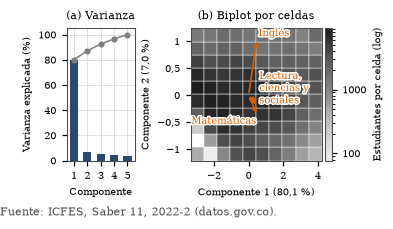

In [48]:
# Etiqueta de cada flecha y su alineación vertical y horizontal; tres áreas con cargas casi iguales comparten una.
ETIQUETA_FLECHA = {"PUNT_INGLES": ("Inglés", "bottom", "left"), "PUNT_MATEMATICAS": ("Matemáticas", "top", "right"), "PUNT_C_NATURALES": ("Lectura,\nciencias y\nsociales", "bottom", "left")}


def rectangulos(eje: plt.Axes, celdas: pd.DataFrame, colores: list) -> None:
    """Dibuja cada celda del plano como un rectángulo entre sus bordes, con su color."""
    for (_, celda), color in zip(celdas.iterrows(), colores, strict=True):
        eje.add_patch(Rectangle((celda["x_inferior"], celda["y_inferior"]), celda["x_superior"] - celda["x_inferior"], celda["y_superior"] - celda["y_inferior"], facecolor=color, edgecolor="white", linewidth=0.3))
    eje.set(xlim=(celdas["x_inferior"].min(), celdas["x_superior"].max()), ylim=(celdas["y_inferior"].min(), celdas["y_superior"].max()))


def titulo_componente(j: int) -> str:
    return f"Componente {j} ({en_espanol(varianza_pca.iloc[j - 1]['Varianza (%)'], 1)} %)"


figura, (eje_varianza, eje_biplot) = plt.subplots(1, 2, figsize=(graficos.ANCHO_COLUMNA, 1.9), gridspec_kw={"width_ratios": [0.9, 2.1]})
posiciones_componentes = np.arange(1, len(AREAS) + 1)
eje_varianza.bar(posiciones_componentes, varianza_pca["Varianza (%)"], color=graficos.COLOR_PRINCIPAL, width=0.6, label="Del componente")
eje_varianza.plot(posiciones_componentes, varianza_pca["Acumulada (%)"], color=graficos.COLOR_APOYO, marker="o", markersize=3, linewidth=1, label="Acumulada")
eje_varianza.set(xticks=posiciones_componentes, xlabel="Componente", ylabel="Varianza explicada (%)", ylim=(0, 105), title="(a) Varianza")
norma_densidad = LogNorm(celdas_densidad["n"].min(), celdas_densidad["n"].max())
mapa_densidad = plt.get_cmap("Greys")
rectangulos(eje_biplot, celdas_densidad, [mapa_densidad(0.15 + 0.75 * norma_densidad(n)) for n in celdas_densidad["n"]])
cargas_plano = cargas[["Componente 1", "Componente 2"]].to_numpy()
limites_plano = np.array([eje_biplot.get_xlim(), eje_biplot.get_ylim()])
escala_flechas = 0.85 * min(np.abs(limites_plano[j, int(c > 0)]) / abs(c) for j in range(2) for c in cargas_plano[:, j] if c != 0)
for area, (x_carga, y_carga) in zip(AREAS, escala_flechas * cargas_plano, strict=True):
    eje_biplot.annotate("", xy=(x_carga, y_carga), xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": graficos.COLOR_NO_OFICIAL, "linewidth": 1.1})
    if area in ETIQUETA_FLECHA:
        texto, vertical, horizontal = ETIQUETA_FLECHA[area]
        # Con un borde blanco, la etiqueta se lee sobre las celdas oscuras.
        eje_biplot.text(x_carga + (0.08 if horizontal == "left" else -0.08), y_carga, texto, fontsize=6.5, color=graficos.COLOR_NO_OFICIAL, ha=horizontal, va=vertical, path_effects=[withStroke(linewidth=2, foreground="white")])
eje_biplot.set(xlabel=titulo_componente(1), ylabel=titulo_componente(2), title="(b) Biplot por celdas")
eje_biplot.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_biplot.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_biplot.grid(False)
barra = figura.colorbar(plt.cm.ScalarMappable(norm=norma_densidad, cmap=ListedColormap(mapa_densidad(np.linspace(0.15, 0.9, 256)))), ax=eje_biplot, pad=0.02)
barra.set_label("Estudiantes por celda (log)")
barra.ax.yaxis.set_major_formatter(graficos.FORMATO_MILES)
figura.tight_layout(w_pad=0.6)
graficos.anotar_fuente(eje_varianza, FUENTE)
figuras.guardar(figura, "pca-biplot")
plt.show()

**Lectura.** El primer componente explica el 80,1 % de la varianza de las cinco áreas y todas cargan casi igual en él (entre 0,42 y 0,46): es el nivel general del estudiante, la dirección en la que suben a la vez los cinco puntajes. Quien rinde bien en un área tiende a rendir bien en las demás, y por eso el puntaje global resume tan bien la prueba. El segundo componente explica solo el 7,0 % y está dominado por inglés (carga de 0,90, frente a cargas negativas y pequeñas, de -0,15 a -0,33, en las otras cuatro): separa a quienes rinden en inglés por encima de lo que su nivel general haría esperar de quienes rinden por debajo. Los tres restantes suman el 12,8 % y contrastan áreas entre sí sin un patrón dominante. En el biplot, los estudiantes forman una sola nube alargada sobre el primer componente, más densa a la izquierda del centro y sin grupos separados ni zonas vacías; las flechas de lectura crítica, ciencias naturales y sociales casi se superponen, la de matemáticas se aparta un poco hacia abajo y la de inglés se abre hacia arriba. El plano queda en 10 celdas por eje porque es la rejilla más fina de la lista en la que ninguna celda tiene menos de 10 estudiantes con los bordes en los percentiles 2 y 98 (la menor tiene 77); con los percentiles 0,5 y 99,5 que fijaba el plan, las colas de la nube dejaban celdas de uno o dos estudiantes en todos los tamaños.

## 17. Segmentación: K-Means, Ward y DBSCAN

### 17.1. K-Means: codo y silueta

K-Means (10 inicios, semilla 42) se ajusta con todo el entrenamiento para K de 2 a 10. La inercia se mide con todo el entrenamiento y la silueta en la muestra de la fase 2 (los estudiantes con las cinco áreas), porque su costo crece con el cuadrado de las filas. La regla del plan elige K como el de mayor silueta y, si otro K queda a menos de 0,01 de ella, el menor. El codo se calcula aparte, como el K más lejano de la recta que une K = 2 y K = 10 en la curva de inercia, y se dice si coincide. El K elegido queda fijado en `segmentacion.K_KMEANS`, que usa `saber11.intermedios --fase 3` para escribir lo que lee el script de R, y una comprobación lo ata a la regla. Los clústeres se numeran de 1 a K de menor a mayor promedio de las cinco áreas estandarizadas.

In [49]:
barrido_kmeans = ajuste.en_cache(segmentacion.barrido_kmeans)(z_areas, en_muestra_areas)
k_elegido, k_codo = segmentacion.k_por_silueta(barrido_kmeans), segmentacion.codo(barrido_kmeans)
tabla(barrido_kmeans.set_index("k"), 3)
print(f"\nK por silueta: {k_elegido}; K del codo: {k_codo}")
comprobar("segmentacion.K_KMEANS es el K de mayor silueta (regla del plan)", segmentacion.K_KMEANS == k_elegido)
comprobar("La inercia baja al aumentar K", barrido_kmeans["inercia"].is_monotonic_decreasing)
silueta_por_k = barrido_kmeans.set_index("k")["silueta"]
cifra("kElegido", k_elegido)
cifra("kElegidoPalabra", en_letras(k_elegido).lower())
cifra("kCodo", k_codo)
cifra("siluetaKmeans", silueta_por_k[k_elegido], 3)
cifra("siluetaKmeansCodo", silueta_por_k[k_codo], 3)
cifra("siluetaKmeansSegunda", silueta_por_k.drop(k_elegido).max(), 3)
cifra("kSiluetaSegunda", int(silueta_por_k.drop(k_elegido).idxmax()))
cifra("siluetaKmeansDiez", silueta_por_k[max(segmentacion.K_CANDIDATOS)], 3);

       inercia silueta
k                     
2  831.079,376   0,443
3  593.688,985   0,337
4  498.545,061   0,276
5  451.903,817   0,230
6  424.687,355   0,216
7  399.165,056   0,191
8  381.595,295   0,179
9  367.058,765   0,177
10 353.788,994   0,163

K por silueta: 2; K del codo: 4
[ok] segmentacion.K_KMEANS es el K de mayor silueta (regla del plan)
[ok] La inercia baja al aumentar K


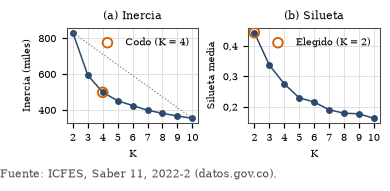

In [50]:
figura, (eje_inercia, eje_silueta) = plt.subplots(1, 2, figsize=(graficos.ANCHO_COLUMNA, 1.55))
eje_inercia.plot(barrido_kmeans["k"], barrido_kmeans["inercia"] / 1e3, color=graficos.COLOR_PRINCIPAL, marker="o", markersize=3.5, linewidth=1)
eje_inercia.plot(barrido_kmeans["k"].iloc[[0, -1]], barrido_kmeans["inercia"].iloc[[0, -1]] / 1e3, color=graficos.COLOR_APOYO, linestyle=":", linewidth=0.8)
eje_inercia.scatter([k_codo], [barrido_kmeans.set_index("k").loc[k_codo, "inercia"] / 1e3], s=40, facecolor="none", edgecolor=graficos.COLOR_NO_OFICIAL, linewidth=1.2, zorder=3, label=f"Codo (K = {k_codo})")
eje_inercia.set(xlabel="K", ylabel="Inercia (miles)", title="(a) Inercia", xticks=barrido_kmeans["k"])
eje_inercia.yaxis.set_major_formatter(graficos.FORMATO_MILES)
eje_inercia.legend()
eje_silueta.plot(barrido_kmeans["k"], barrido_kmeans["silueta"], color=graficos.COLOR_PRINCIPAL, marker="o", markersize=3.5, linewidth=1)
eje_silueta.scatter([k_elegido], [silueta_por_k[k_elegido]], s=40, facecolor="none", edgecolor=graficos.COLOR_NO_OFICIAL, linewidth=1.2, zorder=3, label=f"Elegido (K = {k_elegido})")
eje_silueta.set(xlabel="K", ylabel="Silueta media", title="(b) Silueta", xticks=barrido_kmeans["k"])
eje_silueta.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_silueta.legend()
figura.tight_layout(w_pad=0.8)
graficos.anotar_fuente(eje_inercia, FUENTE)
figuras.guardar(figura, "kmeans-codo-silueta")
plt.show()

**Lectura.** La silueta más alta es la de K = 2 (0,443), con mucha distancia sobre la de K = 3 (0,338), y sigue bajando hasta 0,161 con K = 10: la regla elige K = 2. El codo de la inercia está en K = 4, así que los dos criterios no coinciden. No es una contradicción: la inercia siempre baja al partir más una nube continua, y el codo marca dónde empieza a bajar más despacio, mientras que la silueta mide si los grupos quedan separados entre sí, y con una sola nube alargada (§16) la partición más nítida es la que la corta en dos. Una silueta de 0,44 indica una estructura débil: los grupos existen como partición útil del nivel, no como poblaciones separadas. Con K = 4 la silueta cae a 0,276 y los cuatro grupos serían cuatro tramos del mismo eje.

### 17.2. Asignaciones con el K elegido

Con `K_KMEANS` fijado, `intermedios.multivariante` ajusta K-Means sobre todo el entrenamiento y Ward sobre la muestra, extiende Ward al resto por el centroide más cercano de sus grupos, numera los clústeres por nivel y calcula las celdas del plano con el clúster mayoritario de cada una. Es la misma función que escribe el intermedio que lee R, así que aquí se comprueba que el archivo tenga exactamente estas asignaciones.

In [51]:
multivariante, celdas_clusteres = intermedios.multivariante(limpio, conjuntos, muestra, segmentacion.K_KMEANS)
multivariante_por_posicion = multivariante.set_index("posicion")
intermedio_r = pd.read_parquet(intermedios.RUTA_MULTIVARIANTE)
celdas_r = pd.read_parquet(intermedios.RUTA_PCA_CELDAS)
COLUMNAS_Z = [f"{intermedios.PREFIJO_ESTANDARIZADA}{a}" for a in AREAS]
comprobar(
    "El intermedio que lee R tiene los mismos estudiantes, áreas estandarizadas y clústeres que este cuaderno",
    intermedio_r["posicion"].equals(multivariante["posicion"]) and intermedio_r[["kmeans", "ward"]].equals(multivariante[["kmeans", "ward"]])
    and np.allclose(intermedio_r[COLUMNAS_Z], z_areas.to_numpy()) and intermedio_r["muestra"].to_numpy().tolist() == en_muestra_areas.tolist(),
)
comprobar(
    "Las celdas del plano que lee R son las de este cuaderno, todas con 10 o más",
    celdas_r[["celda_x", "celda_y", "n", "cluster"]].equals(celdas_clusteres[["celda_x", "celda_y", "n", "cluster"]]) and (celdas_r["n"] >= segmentacion.MINIMO_POR_GRUPO).all()
    and celdas_r[["celda_x", "celda_y", "n"]].equals(celdas_densidad[["celda_x", "celda_y", "n"]]),
)
clusteres_kmeans = multivariante_por_posicion["kmeans"]
tamanos_clusteres = clusteres_kmeans.value_counts().sort_index()
tabla(pd.DataFrame({"Estudiantes": tamanos_clusteres, "Porcentaje": 100 * tamanos_clusteres / filas_z}).rename_axis("Clúster de K-Means"), 1)
for cluster, n in tamanos_clusteres.items():
    cifra(f"porcentajeCluster{en_letras(cluster)}", 100 * n / filas_z, 1)
    cifra(f"estudiantesCluster{en_letras(cluster)}", int(n))

[ok] El intermedio que lee R tiene los mismos estudiantes, áreas estandarizadas y clústeres que este cuaderno
[ok] Las celdas del plano que lee R son las de este cuaderno, todas con 10 o más
                   Estudiantes Porcentaje
Clúster de K-Means                       
1                      208.671       56,2
2                      162.740       43,8


### 17.3. Ward y DBSCAN

Ward es jerárquico y su matriz de distancias crece con el cuadrado de las filas, así que corre en la muestra; el árbol se corta en el mismo K que K-Means. El dendrograma se trunca en el mayor número de hojas, hasta 30, en el que cada hoja reúne 10 o más estudiantes, y cada hoja dice cuántos tiene. DBSCAN, también en la muestra, usa `min_samples` de 10 y toma `eps` del punto de la curva ordenada de k-distancias (la distancia de cada estudiante al décimo punto más cercano, contándose a sí mismo, como cuenta `min_samples`) más lejano de la recta entre sus extremos. La figura dibuja esa curva por percentiles, no estudiante por estudiante. El índice de Rand ajustado (ARI) compara los tres agrupamientos sobre la muestra: 1 es la misma partición y 0, el acuerdo que daría el azar.

In [52]:
z_muestra = z_areas.loc[en_muestra_areas]
enlace_ward = segmentacion.ward(z_muestra)
corte_ward = segmentacion.ordenar(segmentacion.cortar(enlace_ward, k_elegido), z_muestra.mean(axis=1).to_numpy())
silueta_ward = float(silhouette_score(z_muestra, corte_ward))
kmeans_muestra = clusteres_kmeans.loc[z_muestra.index].to_numpy()
ward_extendido_muestra = multivariante_por_posicion.loc[z_muestra.index, "ward"].to_numpy()
concordancia_centroides = float((ward_extendido_muestra == corte_ward).mean())
hojas = segmentacion.hojas_truncadas(enlace_ward)
k_distancias = segmentacion.k_distancias(z_muestra)
eps_dbscan = segmentacion.eps_por_k_distancias(k_distancias)
etiquetas_dbscan = segmentacion.dbscan(z_muestra, eps_dbscan)
grupos_dbscan = pd.Series(etiquetas_dbscan).value_counts()
ruido_dbscan = float((etiquetas_dbscan == -1).mean())
tamanos_dbscan = grupos_dbscan.drop(index=-1, errors="ignore").sort_values(ascending=False)
ari_tabla = segmentacion.ari({"K-Means": kmeans_muestra, "Ward": corte_ward, "DBSCAN": etiquetas_dbscan})
print(f"Ward en la muestra: silueta {en_espanol(silueta_ward, 3)}; la asignación por centroides reproduce el corte en el {en_espanol(100 * concordancia_centroides, 1)} % de la muestra")
print(f"Dendrograma truncado en {hojas} hojas")
print(f"DBSCAN: eps = {en_espanol(eps_dbscan, 3)}; {len(tamanos_dbscan)} grupos de {', '.join(en_espanol(int(n)) for n in tamanos_dbscan)} estudiantes y {en_espanol(100 * ruido_dbscan, 1)} % de ruido")
tabla(ari_tabla.set_index(["a", "b"]), 3)
comprobar("Cada hoja del dendrograma truncado tiene 10 o más estudiantes", np.bincount(fcluster(enlace_ward, hojas, criterion="maxclust"))[1:].min() >= segmentacion.MINIMO_POR_GRUPO)
comprobar("Ward y K-Means se comparan con el mismo K y sobre la misma muestra", len(np.unique(corte_ward)) == k_elegido == len(np.unique(kmeans_muestra)) and len(corte_ward) == len(kmeans_muestra))
ari_par = ari_tabla.set_index(["a", "b"])["ari"]
cifra("siluetaWard", silueta_ward, 3)
cifra("concordanciaWardCentroides", 100 * concordancia_centroides, 1)
cifra("hojasDendrograma", hojas)
cifra("ariKmeansWard", ari_par[("K-Means", "Ward")], 3)
cifra("ariKmeansDbscan", ari_par[("K-Means", "DBSCAN")], 3)
cifra("ariWardDbscan", ari_par[("Ward", "DBSCAN")], 3)
cifra("epsDbscan", eps_dbscan, 2)
cifra("gruposDbscan", len(tamanos_dbscan))
cifra("gruposMenoresDbscanPalabra", en_letras(len(tamanos_dbscan) - 1).lower())
cifra("mayorGrupoDbscan", 100 * tamanos_dbscan.iloc[0] / len(etiquetas_dbscan), 1)
cifra("ruidoDbscan", 100 * ruido_dbscan, 1)
cifra("altoWardMuestra", 100 * (corte_ward == k_elegido).mean(), 1)
cifra("altoKmeansMuestra", 100 * (kmeans_muestra == k_elegido).mean(), 1)
cifra("altoWardExtendido", 100 * multivariante["ward"].eq(k_elegido).mean(), 1)
cifra("alturaUltimaUnionWard", enlace_ward[-1, 2], 0)
cifra("alturaPenultimaUnionWard", enlace_ward[-2, 2], 0)
cifra("percentilEps", 100 * np.searchsorted(k_distancias, eps_dbscan) / len(k_distancias), 1);

Ward en la muestra: silueta 0,412; la asignación por centroides reproduce el corte en el 92,5 % de la muestra
Dendrograma truncado en 30 hojas
DBSCAN: eps = 0,661; 3 grupos de 19.526, 72, 10 estudiantes y 1,6 % de ruido
                 ari
a       b           
K-Means Ward   0,436
        DBSCAN 0,004
Ward    DBSCAN 0,016
[ok] Cada hoja del dendrograma truncado tiene 10 o más estudiantes
[ok] Ward y K-Means se comparan con el mismo K y sobre la misma muestra


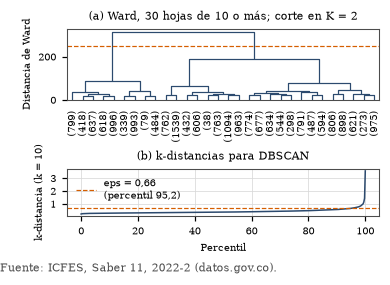

In [53]:
PERCENTILES_K_DISTANCIA = np.linspace(0, 100, 401)
# Los dos paneles, uno sobre otro, para que las hojas del dendrograma tengan todo el ancho de la columna.
figura, (eje_dendrograma, eje_k_distancia) = plt.subplots(2, 1, figsize=(graficos.ANCHO_COLUMNA, 2.4), gridspec_kw={"height_ratios": [1.5, 1]})
# El corte en K grupos queda entre la altura de la unión que pasa de K + 1 a K grupos y la que pasa de K a K - 1.
umbral_corte = (enlace_ward[-k_elegido, 2] + enlace_ward[-(k_elegido - 1), 2]) / 2
with plt.rc_context({"lines.linewidth": 0.8}):
    dendrogram(enlace_ward, truncate_mode="lastp", p=hojas, show_leaf_counts=True, leaf_font_size=6.5, leaf_rotation=90, color_threshold=0, above_threshold_color=graficos.COLOR_PRINCIPAL, ax=eje_dendrograma)
eje_dendrograma.axhline(umbral_corte, color=graficos.COLOR_NO_OFICIAL, linestyle="--", linewidth=0.8)
eje_dendrograma.set(ylabel="Distancia de Ward", title=f"(a) Ward, {hojas} hojas de 10 o más; corte en K = {k_elegido}")
eje_dendrograma.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_dendrograma.grid(False)
percentil_eps = 100 * np.searchsorted(k_distancias, eps_dbscan) / len(k_distancias)
eje_k_distancia.plot(PERCENTILES_K_DISTANCIA, np.percentile(k_distancias, PERCENTILES_K_DISTANCIA), color=graficos.COLOR_PRINCIPAL, linewidth=1)
eje_k_distancia.axhline(eps_dbscan, color=graficos.COLOR_NO_OFICIAL, linestyle="--", linewidth=0.8, label=f"eps = {en_espanol(eps_dbscan, 2)}\n(percentil {en_espanol(percentil_eps, 1)})")
# NearestNeighbors cuenta al propio estudiante como su primer vecino, como min_samples de DBSCAN.
eje_k_distancia.set(xlabel="Percentil", ylabel="k-distancia (k = 10)", title="(b) k-distancias para DBSCAN")
eje_k_distancia.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje_k_distancia.legend(loc="upper left")
figura.tight_layout(h_pad=0.8)
graficos.anotar_fuente(eje_k_distancia, FUENTE)
figuras.guardar(figura, "ward-dbscan")
plt.show()

**Lectura.** Ward también parte la muestra por nivel, pero no en el mismo lugar. Con K = 2 su silueta es 0,412 (frente a 0,443 de K-Means) y el ARI entre los dos es 0,436, un acuerdo moderado. La diferencia está en la frontera: Ward deja en su grupo alto al 26,9 % de la muestra y K-Means al 43,8 %, y todos los estudiantes del grupo alto de Ward están también en el de K-Means. En una nube continua, dónde cae el corte depende del criterio de cada algoritmo: K-Means minimiza la distancia de cada estudiante a su centroide y Ward une en cada paso los dos grupos que menos aumentan la varianza interna. Extender Ward al resto del entrenamiento por el centroide más cercano reproduce el corte en el 92,5 % de la muestra; los que cambian están en la frontera, y con la extensión el grupo alto de Ward pasa al 34,1 % del entrenamiento. El dendrograma explica por qué la silueta prefiere dos grupos: la última unión (altura 313) casi duplica la anterior (188), y por debajo las ramas se dividen de forma gradual. DBSCAN da la evidencia de por qué no sirve aquí: con el `eps` de la regla (0,66, en el percentil 95,2 de las k-distancias) junta al 98,0 % de la muestra en un solo grupo, deja dos grupos de 72 y 10 estudiantes en el borde de la nube y marca como ruido al 1,6 %. Su ARI con los otros dos es casi cero (0,004 y 0,016). DBSCAN separa regiones densas por zonas vacías, y en estos datos no hay zonas vacías: hay una sola nube de densidad continua. Se descarta como segmentación y queda como prueba de que los clústeres de K-Means y Ward son cortes de un continuo, no grupos naturales.

### 17.4. Plano PCA por clúster

El plano de §16 se colorea ahora por el clúster de K-Means mayoritario en cada celda; la intensidad del color sigue la proporción de ese clúster dentro de la celda. Es la figura que se dibuja también en ggplot2 (§19) y la que se compara entre herramientas en §20.

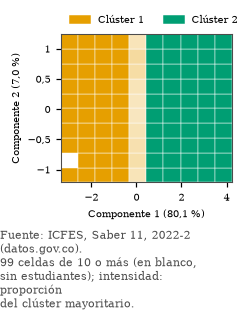

Celdas con el clúster mayoritario por debajo del 90 %: 10 de 99, con 47.485 estudiantes
[ok] Toda celda del plano tiene un clúster mayoritario de los K elegidos


In [54]:
# Tamaño de un panel de la comparación de herramientas (§20), como TAMANO_INTERACCION; el mismo en el script de R.
TAMANO_PLANO = (2.0, 1.75)
# Colores de los clústeres, distintos de los de la naturaleza del colegio; los mismos en el script de R.
COLORES_CLUSTER = tuple(graficos.PALETA_CATEGORICA[i] for i in (5, 2, 3, 4, 6))


def alfa_por_proporcion(proporcion: pd.Series) -> np.ndarray:
    """Opacidad de 0,25 a 1, lineal entre la menor y la mayor proporción (como `scale_alpha` de ggplot2)."""
    rango = proporcion.max() - proporcion.min()
    return 0.25 + 0.75 * ((proporcion - proporcion.min()) / rango if rango > 0 else 1.0)


def plano_matplotlib(celdas: pd.DataFrame) -> plt.Figure:
    """Plano de los dos primeros componentes por celdas: color del clúster mayoritario, intensidad según su proporción."""
    figura, eje = plt.subplots(figsize=TAMANO_PLANO)
    rectangulos(eje, celdas, [to_rgba(COLORES_CLUSTER[c - 1], a) for c, a in zip(celdas["cluster"], alfa_por_proporcion(celdas["proporcion"]), strict=True)])
    eje.legend(handles=[Patch(color=COLORES_CLUSTER[c - 1], label=f"Clúster {c}") for c in sorted(celdas["cluster"].unique())], loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4)
    eje.set(xlabel=titulo_componente(1), ylabel=titulo_componente(2))
    eje.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
    eje.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
    eje.grid(False)
    return figura


figura = plano_matplotlib(celdas_clusteres)
graficos.anotar_fuente(figura.axes[0], f"{FUENTE}\n{len(celdas_clusteres)} celdas de 10 o más (en blanco, sin estudiantes); intensidad: proporción\ndel clúster mayoritario.")
figuras.guardar(figura, "plano-clusteres")
plt.show()
mixtas = celdas_clusteres[celdas_clusteres["proporcion"] < 0.9]
print(f"Celdas con el clúster mayoritario por debajo del 90 %: {len(mixtas)} de {len(celdas_clusteres)}, con {en_espanol(int(mixtas['n'].sum()))} estudiantes")
comprobar("Toda celda del plano tiene un clúster mayoritario de los K elegidos", celdas_clusteres["cluster"].isin(range(1, k_elegido + 1)).all() and (celdas_clusteres["proporcion"] >= 1 / k_elegido).all())
cifra("celdasMixtasPlano", len(mixtas))
cifra("porcentajeCeldasMixtas", 100 * mixtas["n"].sum() / filas_z, 1);

**Lectura.** Los dos clústeres parten el plano con una frontera vertical: el clúster 1 ocupa la izquierda (puntajes bajos en el primer componente) y el clúster 2 la derecha. El segundo componente, el del inglés, no interviene en la frontera, que es la marca de una partición por nivel. Las celdas mixtas, de color más claro, son una sola columna de 10 celdas en el centro, donde el clúster mayoritario no llega al 90 %; reúnen al 12,8 % del entrenamiento. Allí los estudiantes de uno y otro clúster tienen puntajes casi iguales, y asignarlos a uno u otro es una convención del algoritmo. Esta es la lectura que el plan anticipaba si el primer componente dominaba: los clústeres son franjas de nivel, no perfiles distintos de fortalezas.

### 17.5. Perfil relativo

Como los clústeres de K-Means son franjas de nivel, el perfil relativo pregunta por la forma: a cada estudiante se le resta su propio promedio de las cinco áreas estandarizadas, de modo que solo queda en qué áreas está por encima o por debajo de su nivel. K-Means se repite sobre ese perfil con la misma regla (K de 2 a 10, silueta en la muestra).

In [55]:
perfil_relativo = segmentacion.perfil_relativo(z_areas)
barrido_relativo = ajuste.en_cache(segmentacion.barrido_kmeans)(perfil_relativo, en_muestra_areas)
k_relativo = segmentacion.k_por_silueta(barrido_relativo)
tabla(barrido_relativo.set_index("k"), 3)
clusteres_relativos = pd.Series(segmentacion.kmeans(perfil_relativo, k_relativo).labels_, index=z_areas.index)
# Se numeran por su media relativa en inglés, el área que más separa los perfiles (segundo componente).
clusteres_relativos = pd.Series(segmentacion.ordenar(clusteres_relativos.to_numpy(), perfil_relativo["PUNT_INGLES"].to_numpy()), index=z_areas.index)
centros_relativos = perfil_relativo.groupby(clusteres_relativos).mean().rename(columns=AREA_LEGIBLE)
naturaleza_areas = limpio.loc[z_areas.index, v.OBJETIVO_CLASIFICACION]
resumen_relativo = pd.DataFrame({
    "Estudiantes": clusteres_relativos.value_counts().sort_index(),
    "Nivel medio (z)": z_areas.mean(axis=1).groupby(clusteres_relativos).mean(),
    "No oficial (%)": 100 * naturaleza_areas.eq(POSITIVA).groupby(clusteres_relativos).mean(),
    f"Clúster {k_elegido} de K-Means (%)": 100 * clusteres_kmeans.loc[z_areas.index].eq(k_elegido).groupby(clusteres_relativos).mean(),
}).rename_axis("Perfil relativo")
ingles_bajo_por_naturaleza = 100 * clusteres_relativos.eq(1).groupby(naturaleza_areas).mean()
print(f"\nK del perfil relativo por silueta: {k_relativo}")
tabla(centros_relativos, 3)
print()
tabla(resumen_relativo, 2)
print(f"\nCon el inglés por debajo de su promedio (perfil 1): {en_espanol(ingles_bajo_por_naturaleza['OFICIAL'], 1)} % de los estudiantes de colegios oficiales y {en_espanol(ingles_bajo_por_naturaleza[POSITIVA], 1)} % de los no oficiales")
comprobar("El perfil relativo de cada estudiante suma cero", np.allclose(perfil_relativo.sum(axis=1), 0))
comprobar("Los perfiles relativos se separan sobre todo por inglés, con el perfil 1 por debajo", centros_relativos.abs().idxmax(axis=1).eq("Inglés").all() and centros_relativos.loc[1, "Inglés"] < 0)
cifra("inglesBajoOficial", ingles_bajo_por_naturaleza["OFICIAL"], 1)
cifra("inglesBajoNoOficial", ingles_bajo_por_naturaleza[POSITIVA], 1)
cifra("kPerfilRelativo", k_relativo)
cifra("kPerfilRelativoPalabra", en_letras(k_relativo).lower())
cifra("siluetaPerfilRelativo", barrido_relativo.set_index("k").loc[k_relativo, "silueta"], 3)
for perfil, fila in centros_relativos.iterrows():
    sufijo = en_letras(perfil)
    cifra(f"inglesPerfilRelativo{sufijo}", fila["Inglés"], 2)
    cifra(f"porcentajePerfilRelativo{sufijo}", 100 * resumen_relativo.loc[perfil, "Estudiantes"] / filas_z, 1)
    cifra(f"noOficialPerfilRelativo{sufijo}", resumen_relativo.loc[perfil, "No oficial (%)"], 1)
    cifra(f"nivelPerfilRelativo{sufijo}", resumen_relativo.loc[perfil, "Nivel medio (z)"], 2);

       inercia silueta
k                     
2  289.977,080   0,200
3  248.827,156   0,180
4  224.361,629   0,169
5  203.637,030   0,168
6  187.796,802   0,170
7  177.386,819   0,163
8  167.690,315   0,165
9  160.285,764   0,156
10 153.672,331   0,158



K del perfil relativo por silueta: 2
  Lectura crítica Matemáticas Ciencias naturales Sociales y ciudadanas Inglés
1           0,085       0,163              0,083                 0,087 -0,418
2          -0,082      -0,157             -0,080                -0,084  0,403

                Estudiantes Nivel medio (z) No oficial (%) Clúster 2 de K-Means (%)
Perfil relativo                                                                    
1                   182.194            0,09          17,54                    47,58
2                   189.217           -0,08          27,64                    40,20

Con el inglés por debajo de su promedio (perfil 1): 52,3 % de los estudiantes de colegios oficiales y 37,9 % de los no oficiales
[ok] El perfil relativo de cada estudiante suma cero
[ok] Los perfiles relativos se separan sobre todo por inglés, con el perfil 1 por debajo


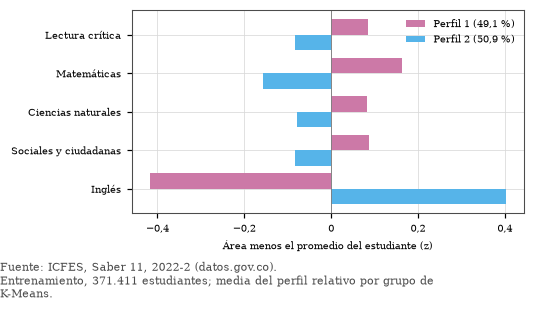

In [56]:
figura, eje = plt.subplots(figsize=(4.6, 2.4))
posiciones_areas = np.arange(len(AREAS))
ancho_barra = 0.8 / k_relativo
for i, (perfil, fila) in enumerate(centros_relativos.iterrows()):
    eje.barh(posiciones_areas + (i - (k_relativo - 1) / 2) * ancho_barra, fila.to_numpy(), height=ancho_barra, color=COLORES_CLUSTER[2 + i], label=f"Perfil {perfil} ({en_espanol(100 * resumen_relativo.loc[perfil, 'Estudiantes'] / filas_z, 1)} %)")
eje.set_yticks(posiciones_areas, centros_relativos.columns)
eje.invert_yaxis()
eje.axvline(0, color=graficos.COLOR_APOYO, linewidth=0.6)
eje.set(xlabel="Área menos el promedio del estudiante (z)")
eje.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
eje.legend(loc="upper right")
graficos.anotar_fuente(eje, f"{FUENTE}\nEntrenamiento, {en_espanol(filas_z)} estudiantes; media del perfil relativo por grupo de K-Means.")
figuras.guardar(figura, "perfil-relativo")
plt.show()

**Lectura.** Sin el nivel general, la regla vuelve a elegir dos grupos, con una silueta de 0,200: una estructura todavía más débil que la de los clústeres de nivel. Lo que separa los dos perfiles es el inglés: en el perfil 1 (49,1 % del entrenamiento) el inglés queda 0,42 desviaciones por debajo del promedio propio del estudiante, y en el perfil 2 (50,9 %), 0,40 por encima; las otras cuatro áreas se mueven en sentido contrario y menos, sobre todo matemáticas (0,16). Es la misma dirección del segundo componente del PCA. Los dos perfiles casi no difieren en nivel general (0,09 y -0,08 desviaciones), pero sí en el tipo de colegio: el perfil con el inglés por encima tiene un 27,6 % de estudiantes de colegios no oficiales, frente al 17,5 % del otro. Visto desde el colegio, el inglés queda por debajo del promedio propio en el 52,3 % de los estudiantes de colegios oficiales y en el 37,9 % de los no oficiales. La fortaleza relativa en inglés sigue más al colegio que al nivel del estudiante. Para un colegio, esto dice que la diferencia de perfil más clara entre sus estudiantes no está entre las ciencias y las humanidades, sino entre el inglés y el resto.

## 18. Perfiles de los clústeres y su reparto

Cada clúster de K-Means se describe por sus medias en las cinco áreas (en la escala de la prueba y estandarizadas) y por su puntaje global medio, y se cruza con el estrato, la zona y la naturaleza del colegio. Cada cruce usa los estudiantes con la variable registrada, va con su χ² de independencia y su V de Cramér (con intervalo bootstrap, como en H4), y se lee por filas: qué parte de cada grupo cae en cada clúster. Todas las celdas de los cruces tienen 10 o más estudiantes, así que se pueden publicar como agregados.

In [57]:
perfiles_kmeans = multivariante.groupby("kmeans")[AREAS + COLUMNAS_Z].mean()
perfiles_kmeans.insert(0, "n", multivariante.groupby("kmeans").size())
global_por_cluster = limpio.loc[clusteres_kmeans.index, v.OBJETIVO_REGRESION].groupby(clusteres_kmeans).mean()
vista_perfiles = perfiles_kmeans[["n", *AREAS]].rename(columns=AREA_LEGIBLE).assign(**{"Puntaje global": global_por_cluster}).rename_axis("Clúster")
tabla(vista_perfiles, 1)
CRUCES = {v.ESTRATO: ("Estrato", intermedios.ESTRATOS_CON_SIN_ESTRATO), "COLE_AREA_UBICACION": ("Zona", ["URBANO", "RURAL"]), v.OBJETIVO_CLASIFICACION: ("Naturaleza", intermedios.NATURALEZAS)}
SUFIJO_CRUCE = {v.ESTRATO: "Estrato", "COLE_AREA_UBICACION": "Zona", v.OBJETIVO_CLASIFICACION: "Naturaleza"}
cruces_cluster, repartos, contrastes_cluster = {}, {}, {}
for variable, (nombre, orden) in CRUCES.items():
    cruce = pd.crosstab(multivariante["kmeans"], multivariante[variable]).reindex(columns=orden)
    cruces_cluster[variable] = cruce
    repartos[variable] = (100 * cruce / cruce.sum()).T
    contrastes_cluster[variable] = chi_cuadrado(cruce)
    contraste = contrastes_cluster[variable]
    print(f"\nClúster por {nombre.lower()} ({en_espanol(contraste.n)} estudiantes con el dato): χ² = {en_espanol(contraste.estadistico, 1)}, gl = {int(contraste.gl[0])}, p {texto_p(contraste.p)}; V = {en_espanol(contraste.valor, 3)} (IC del 95 %: {en_espanol(contraste.ic[0], 3)} a {en_espanol(contraste.ic[1], 3)})")
    tabla(repartos[variable].assign(Estudiantes=cruce.sum()).rename(index=lambda n, x=variable: nivel_legible(x, n), columns=lambda c: f"Clúster {c}" if isinstance(c, (int, np.integer)) else c), 1)
comprobar("Los cruces de clúster por estrato, zona y naturaleza tienen 10 o más estudiantes en cada celda", all((c >= segmentacion.MINIMO_POR_GRUPO).all().all() for c in cruces_cluster.values()))
comprobar("Los clústeres se numeran por nivel: cada uno tiene medias más altas que el anterior en las cinco áreas", (perfiles_kmeans[AREAS].diff().dropna() > 0).all().all())
for cluster, fila in vista_perfiles.iterrows():
    cifra(f"globalCluster{en_letras(cluster)}", fila["Puntaje global"], 1)
    for area in AREAS:
        cifra(f"{AREA_CLAVE[area]}Cluster{en_letras(cluster)}", fila[AREA_LEGIBLE[area]], 1)
for variable, contraste in contrastes_cluster.items():
    sufijo = SUFIJO_CRUCE[variable]
    cifra(f"chiCluster{sufijo}", contraste.estadistico, 1)
    cifra(f"vCluster{sufijo}", contraste.valor, 3)
    cifra(f"vInfCluster{sufijo}", contraste.ic[0], 3)
    cifra(f"vSupCluster{sufijo}", contraste.ic[1], 3)
# Parte de cada grupo que cae en el clúster de mayor nivel.
SUFIJO_NIVEL = {**SUFIJO_ESTRATO, "URBANO": "Urbano", "RURAL": "Rural", "OFICIAL": "Oficial", POSITIVA: "NoOficial"}
for variable in CRUCES:
    for nivel, porcentaje in repartos[variable][k_elegido].items():
        cifra(f"clusterAlto{SUFIJO_NIVEL[nivel]}", porcentaje, 1)
cifra("menorCeldaCruceCluster", int(min(c.min().min() for c in cruces_cluster.values())));

              n Lectura crítica Matemáticas Ciencias naturales Sociales y ciudadanas Inglés Puntaje global
Clúster                                                                                                   
1       208.671            45,7        42,8               42,1                  39,6   41,8          212,5
2       162.740            62,0        60,7               58,2                  58,2   60,2          298,9

Clúster por estrato (346.447 estudiantes con el dato): χ² = 12.622,5, gl = 6, p < 0,001; V = 0,191 (IC del 95 %: 0,188 a 0,194)
kmeans               Clúster 1 Clúster 2 Estudiantes
FAMI_ESTRATOVIVIENDA                                
Estrato 1                 63,9      36,1     101.937
Estrato 2                 53,2      46,8     125.786
Estrato 3                 44,9      55,1      76.948
Estrato 4                 42,9      57,1      19.654
Estrato 5                 48,8      51,2        5882
Estrato 6                 57,7      42,3        2661
Sin estrato        


Clúster por naturaleza (371.411 estudiantes con el dato): χ² = 13.983,4, gl = 1, p < 0,001; V = 0,194 (IC del 95 %: 0,191 a 0,197)
kmeans          Clúster 1 Clúster 2 Estudiantes
COLE_NATURALEZA                                
Oficial              61,4      38,6     287.153
No oficial           38,4      61,6      84.258
[ok] Los cruces de clúster por estrato, zona y naturaleza tienen 10 o más estudiantes en cada celda
[ok] Los clústeres se numeran por nivel: cada uno tiene medias más altas que el anterior en las cinco áreas


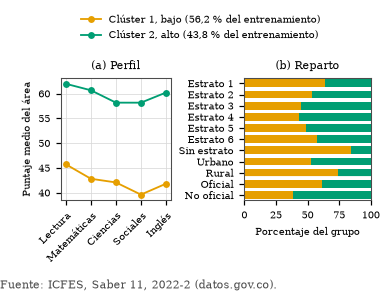

In [58]:
# Nombre de cada clúster en la leyenda: el de menor nivel es el bajo y el de mayor nivel, el alto.
NIVEL_CLUSTER = {1: "bajo", k_elegido: "alto"}
AREA_CORTA = {"Lectura crítica": "Lectura", "Ciencias naturales": "Ciencias", "Sociales y ciudadanas": "Sociales"}
figura, (eje_perfil, eje_reparto) = plt.subplots(1, 2, figsize=(graficos.ANCHO_COLUMNA, 2.05), gridspec_kw={"width_ratios": [1, 1.15]})
for cluster, fila in perfiles_kmeans.iterrows():
    nivel = f", {NIVEL_CLUSTER[cluster]}" if cluster in NIVEL_CLUSTER else ""
    eje_perfil.plot(range(len(AREAS)), fila[AREAS], color=COLORES_CLUSTER[cluster - 1], marker="o", markersize=3.5, linewidth=1.2, label=f"Clúster {cluster}{nivel} ({en_espanol(100 * fila['n'] / filas_z, 1)} % del entrenamiento)")
eje_perfil.set_xticks(range(len(AREAS)), [AREA_CORTA.get(AREA_LEGIBLE[a], AREA_LEGIBLE[a]) for a in AREAS], rotation=45, ha="right", rotation_mode="anchor")
eje_perfil.set(ylabel="Puntaje medio del área", title="(a) Perfil")
eje_perfil.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
filas_reparto = pd.concat([repartos[x].rename(index=lambda n, y=x: nivel_legible(y, n)) for x in CRUCES]).iloc[::-1]
posiciones_reparto = np.arange(len(filas_reparto))
izquierda = np.zeros(len(filas_reparto))
for cluster in filas_reparto.columns:
    eje_reparto.barh(posiciones_reparto, filas_reparto[cluster], left=izquierda, color=COLORES_CLUSTER[cluster - 1], height=0.7)
    izquierda += filas_reparto[cluster].to_numpy()
eje_reparto.set_yticks(posiciones_reparto, filas_reparto.index)
separadores = np.cumsum([len(repartos[x]) for x in reversed(CRUCES)])[:-1] - 0.5
for separador in separadores:
    eje_reparto.axhline(separador, color="white", linewidth=2.5)
eje_reparto.set(xlabel="Porcentaje del grupo", xlim=(0, 100), xticks=range(0, 101, 25), title="(b) Reparto")
eje_reparto.grid(False)
eje_reparto.margins(y=0.01)
figura.tight_layout(w_pad=0.6)
figura.legend(*eje_perfil.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=1)
graficos.anotar_fuente(eje_perfil, FUENTE)
figuras.guardar(figura, "perfiles-clusteres")
plt.show()

**Lectura.** Los dos clústeres son dos niveles con el mismo perfil. El clúster 1 reúne al 56,2 % del entrenamiento, con un puntaje global medio de 212,5, y el clúster 2 al 43,8 %, con 298,9; en cada área el clúster 2 supera al 1 por entre 16 y 19 puntos, y las dos líneas tienen casi la misma forma (lectura crítica es la más alta en los dos, y sociales, la más baja o empatada con ciencias naturales). La diferencia es de nivel general, no de áreas: un programa que quiera mover a los estudiantes del clúster bajo tiene que ser transversal y no de un área.

El reparto confirma lo que las pruebas de hipótesis anticipaban, ahora sobre el desempeño en las cinco áreas a la vez. Los tres cruces son significativos y sus V son pequeñas o moderadas: estrato 0,191, zona 0,161 y naturaleza 0,194. El 61,6 % de los estudiantes de colegios no oficiales cae en el clúster alto, frente al 38,6 % de los oficiales; en la zona rural, solo el 26,2 %, frente al 47,4 % en la urbana, y entre los hogares sin estrato, el 15,6 %. Por estrato, la parte en el clúster alto sube del 36,1 % en el estrato 1 al 57,1 % en el 4 y vuelve a bajar en el 5 (51,2 %) y el 6 (42,3 %), la misma caída de los estratos altos que H3 encontró en los colegios oficiales y que la fase 1 tomó como un posible cambio en el registro del estrato, no como un deterioro real. Que las V no pasen de 0,2 dice que el hogar y el colegio pesan, pero no determinan el clúster: más de un tercio de los estudiantes de colegios oficiales está en el grupo alto y más de un tercio de los no oficiales, en el bajo.

Para las secretarías de educación, el clúster bajo concentra a tres de cada cuatro estudiantes rurales y a más de cuatro de cada cinco de los hogares sin estrato: son la población donde un refuerzo general tendría más alcance. Para los colegios, el perfil plano de los clústeres dice que el rezago no está en un área sino en todas, y el perfil relativo de §17.5 agrega una excepción: el inglés, que en los colegios oficiales queda por debajo de las demás áreas con más frecuencia que en los no oficiales. Todo esto es asociación entre el desempeño y las condiciones del estudiante, no un efecto causal del estrato, la zona o el colegio.

## 19. Paridad del multivariante con R

`src/r/fase-3-multivariante.R` lee el intermedio de §17.2 y repite con `prcomp` el PCA de las cinco áreas estandarizadas, calcula las medias de cada clúster con las asignaciones de K-Means y de Ward que hizo Python (K-Means no se vuelve a ajustar en R, porque `kmeans` usa otro algoritmo y otra inicialización y no daría las mismas etiquetas) y repite con `chisq.test(correct = FALSE)` los tres cruces de §18. Los valores propios, las cargas, las medias, los χ² y las V se comparan con una diferencia relativa menor que 1e-6. El signo de un vector propio es arbitrario, así que antes de comparar las cargas cada componente de R se multiplica por el signo de su producto con el de Python. El script también dibuja en ggplot2 el plano por celdas y los perfiles, y mide el plano para la comparación de herramientas de §20.

In [59]:
RUTA_R_MULTIVARIANTE = RUTA_RESULTADOS / "r" / "fase-3-multivariante.json"
comprobar(f"Existe la salida del script de R ({relativa(RUTA_R_MULTIVARIANTE)})", RUTA_R_MULTIVARIANTE.is_file())
salida_r_multivariante = json.loads(RUTA_R_MULTIVARIANTE.read_text(encoding="utf-8"))
print(f"R {salida_r_multivariante['version_r']} y ggplot2 {salida_r_multivariante['version_ggplot2']}")
inicio_paridad_multivariante = len(filas_paridad)
pca_r = salida_r_multivariante["pca"]
cargas_r = np.array(pca_r["cargas"], dtype=float)
signos_cargas = np.sign((cargas_r * pca_areas.components_).sum(axis=1))
comprobar("Paridad con R: valores propios del PCA (prcomp)", salida_r_multivariante["n"] == filas_z and paridad("PCA: valores propios", pca_areas.explained_variance_, pca_r["valores_propios"]))
comprobar(
    "Paridad con R: cargas del PCA con el signo de cada componente alineado",
    salida_r_multivariante["areas"] == AREAS and paridad("PCA: cargas", pca_areas.components_.ravel(), (cargas_r * signos_cargas[:, None]).ravel()),
)
medias_cluster_r = {asignacion: pd.DataFrame(filas).set_index("cluster") for asignacion, filas in salida_r_multivariante["medias"].items()}
comprobar("Paridad con R: medias de las cinco áreas, crudas y estandarizadas, por clúster de K-Means y de Ward", all([
    all(medias_cluster_r[a]["n"].tolist() == multivariante.groupby(a).size().tolist() for a in medias_cluster_r),
    *(paridad(f"Medias por clúster ({a})", multivariante.groupby(a)[AREAS + COLUMNAS_Z].mean().to_numpy().ravel(), medias_cluster_r[a][AREAS + COLUMNAS_Z].to_numpy().ravel()) for a in ("kmeans", "ward")),
]))
chi_r = salida_r_multivariante["chi2"]
NOMBRE_R_CRUCE = {v.ESTRATO: "estrato", "COLE_AREA_UBICACION": "zona", v.OBJETIVO_CLASIFICACION: "naturaleza"}
comprobar("Paridad con R: χ² y V de Cramér del clúster por estrato, zona y naturaleza", all([
    all(chi_r[NOMBRE_R_CRUCE[x]]["n"] == contrastes_cluster[x].n and chi_r[NOMBRE_R_CRUCE[x]]["gl"] == contrastes_cluster[x].gl[0] for x in CRUCES),
    paridad("Clúster por perfil: χ²", [contrastes_cluster[x].estadistico for x in CRUCES], [chi_r[NOMBRE_R_CRUCE[x]]["chi2"] for x in CRUCES]),
    paridad("Clúster por perfil: V de Cramér", [contrastes_cluster[x].valor for x in CRUCES], [chi_r[NOMBRE_R_CRUCE[x]]["v"] for x in CRUCES]),
]))
comprobar(
    "R dibuja el plano con las mismas celdas (número, estudiantes y celda menor)",
    salida_r_multivariante["celdas"] == {"n": len(celdas_clusteres), "estudiantes": filas_z, "menor": int(celdas_clusteres["n"].min())},
)
tabla_paridad_multivariante = pd.DataFrame(filas_paridad[inicio_paridad_multivariante:]).set_index("comparación")
print(tabla_paridad_multivariante.to_string(formatters={"mayor diferencia": lambda x: f"{x:.1e}"}))
cifra("paridadValoresMultivariante", int(tabla_paridad_multivariante["valores"].sum()))
cifra("paridadComparacionesMultivariante", len(tabla_paridad_multivariante))
cifra("paridadMaxRelativaMultivariante", f"{tabla_paridad_multivariante['mayor diferencia'].max():.1e}".replace(".", ","));

[ok] Existe la salida del script de R (resultados/r/fase-3-multivariante.json)
R 4.6.1 y ggplot2 4.0.3
[ok] Paridad con R: valores propios del PCA (prcomp)
[ok] Paridad con R: cargas del PCA con el signo de cada componente alineado
[ok] Paridad con R: medias de las cinco áreas, crudas y estandarizadas, por clúster de K-Means y de Ward
[ok] Paridad con R: χ² y V de Cramér del clúster por estrato, zona y naturaleza
[ok] R dibuja el plano con las mismas celdas (número, estudiantes y celda menor)
                                 valores mayor diferencia      tipo
comparación                                                        
PCA: valores propios                   5          1.5e-13  relativa
PCA: cargas                           25          3.7e-12  relativa
Medias por clúster (kmeans)           20          7.2e-16  relativa
Medias por clúster (ward)             20          3.8e-15  relativa
Clúster por perfil: χ²                 3          1.2e-15  relativa
Clúster por perfil: V de C

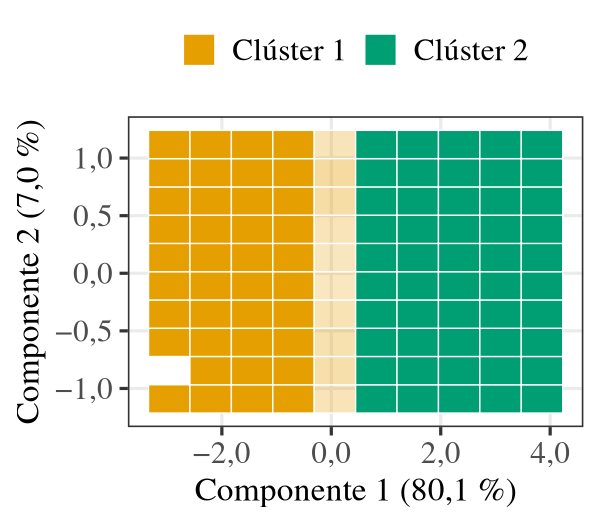

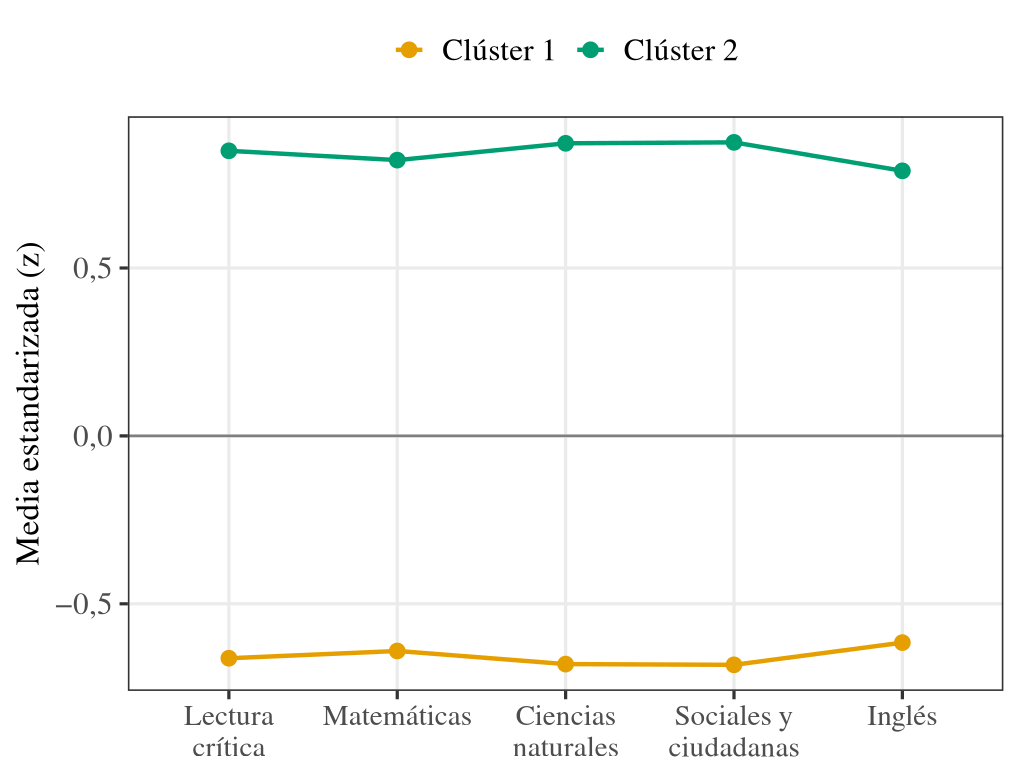

In [60]:
for nombre, ancho in (("plano-pca", 360), ("perfiles", 360)):
    ruta = RUTA_FIGURAS / "r" / f"{nombre}-ggplot2.png"
    figuras.registrar(ruta)
    display(Image(filename=ruta, width=ancho))

**Lectura.** R llega a los mismos números que Python: en los 76 valores de las seis comparaciones, la mayor diferencia relativa es de 3,7e-12 (las cargas, después de alinear el signo de cada componente), del orden del error de redondeo. Que coincidan las medias por clúster y los χ² confirma que R leyó las mismas filas, con los mismos clústeres y los mismos niveles de estrato, zona y naturaleza; que coincidan los valores propios y las cargas confirma que `prcomp` y scikit-learn descomponen la misma matriz. Las dos figuras de ggplot2 dibujan lo mismo que las de Python: el plano por celdas con la frontera vertical entre los dos clústeres y la columna de celdas mixtas, y los dos perfiles paralelos, ahora en desviaciones estándar, con el inglés un poco más cerca del centro en los dos clústeres.

## 20. Herramientas de visualización: comparación medida

### 20.1. Dos figuras de esta fase en cuatro herramientas

La fase 1 comparó Matplotlib, Seaborn, Plotly y ggplot2 con un histograma y un mapa de correlación, y la fase 2 con los coeficientes y los residuos de la regresión. Esta fase repite la comparación con dos figuras propias: la interacción de estrato y naturaleza de H3 (§5), que dibuja el resultado de una prueba de hipótesis, y el plano PCA por clúster (§17.4), que dibuja el resultado del análisis multivariante. Las cuatro versiones de cada figura parten de los mismos datos agregados (las 14 medias de H3 con su intervalo y las 99 celdas del plano), con el mismo tamaño (`TAMANO_INTERACCION` y `TAMANO_PLANO`, iguales en los scripts de R), los mismos títulos y los mismos colores. La versión en Plotly de la interacción es la de §5 y la versión en Matplotlib del plano es la de §17.4; las de ggplot2 las dibujan y las miden `fase-3-hipotesis.R` y `fase-3-multivariante.R`.

Cada versión se mide como en las fases anteriores, con `graficos.medir`: las instrucciones de la función que construye la figura (en ggplot2, una sola expresión encadenada con `+`, cuyos componentes se cuentan aparte), la mediana de tres tiempos de construirla y exportarla a PNG, el peso del PNG y el de una segunda salida, que es el PDF vectorial en Matplotlib, Seaborn y ggplot2 y el HTML interactivo en Plotly. Los tiempos y los pesos dependen de la máquina, así que sus cifras llevan el prefijo `medida`.

Tres fricciones aparecen antes de medir. Seaborn no dibuja intervalos ya calculados: como en la fase 2, la función le entrega a `pointplot` el límite inferior, la media y el límite superior de cada celda y le pide la mediana como punto y el mínimo y el máximo como barra. Seaborn tampoco tiene un rectángulo con color y opacidad propios: el plano se dibuja como un histograma bidimensional ponderado (`histplot` con `weights` y `hue`), en el que cada clúster recibe una rampa de color de claro a oscuro que Seaborn construye a partir del color dado y que no se puede fijar al color exacto. Plotly no tiene una traza de rectángulos: las celdas van como formas del diseño (`shapes`), que no responden al cursor, así que la función agrega en el centro de cada celda un marcador invisible con su n y su proporción; además, la plantilla `simple_white` les pone a las formas una opacidad de 0,3 por defecto y hay que fijarla en 1.

                        Instrucciones Tiempo a PNG (s) PNG (kB)   Segunda salida Segunda salida (kB)
Gráfico     Herramienta                                                                             
interaccion Matplotlib              7            0,061   41,848    PDF vectorial              15,552
            Seaborn                 7            0,077   41,086    PDF vectorial              14,708
            Plotly                  5            2,017   48,706 HTML interactivo              11,339
            ggplot2                 1            0,140   41,084    PDF vectorial               5,683
plano       Matplotlib              9            0,081   30,515    PDF vectorial              13,729
            Seaborn                11            0,060   28,921    PDF vectorial              13,965
            Plotly                  6            1,943   41,442 HTML interactivo              35,688
            ggplot2                 1            0,102   34,002    PDF vectorial           

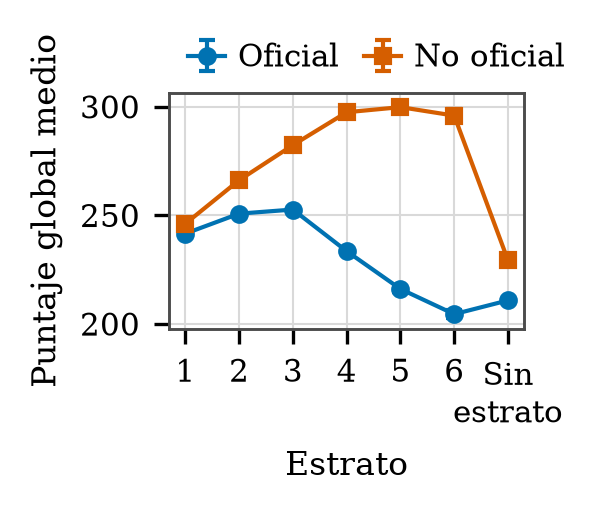

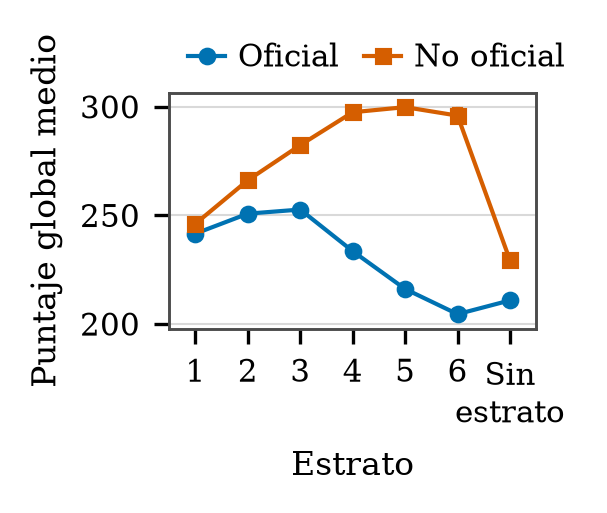

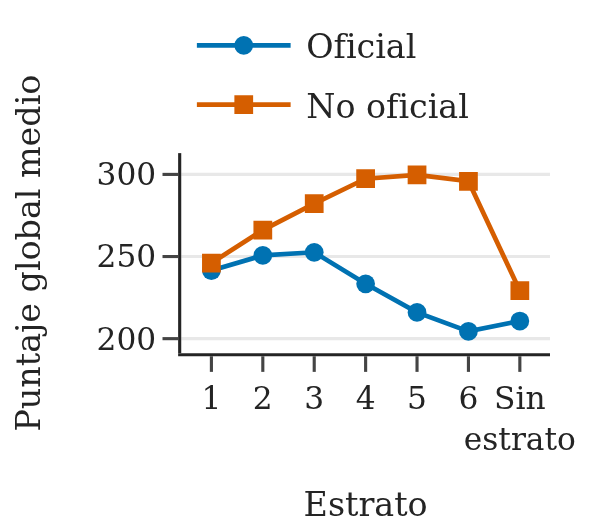

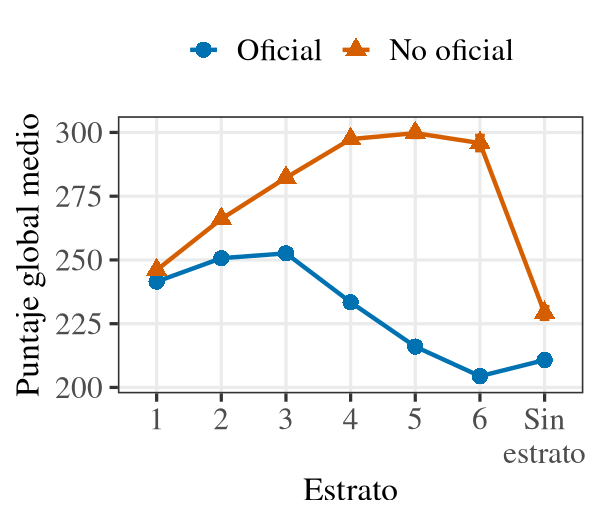

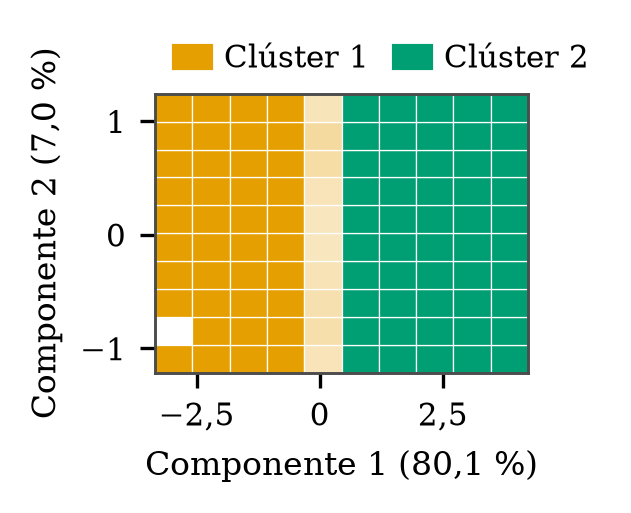

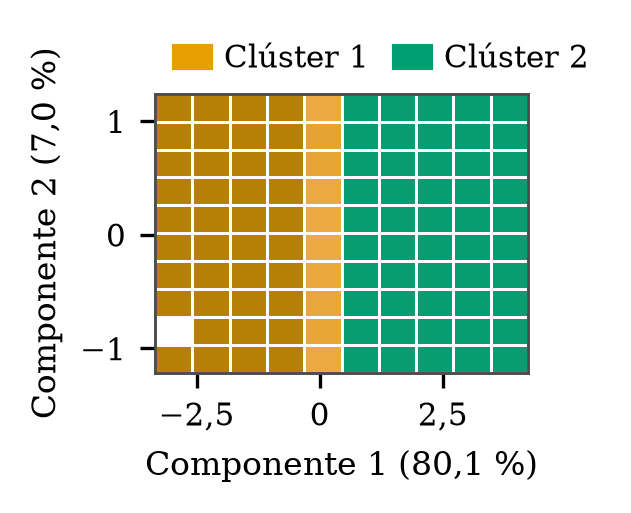

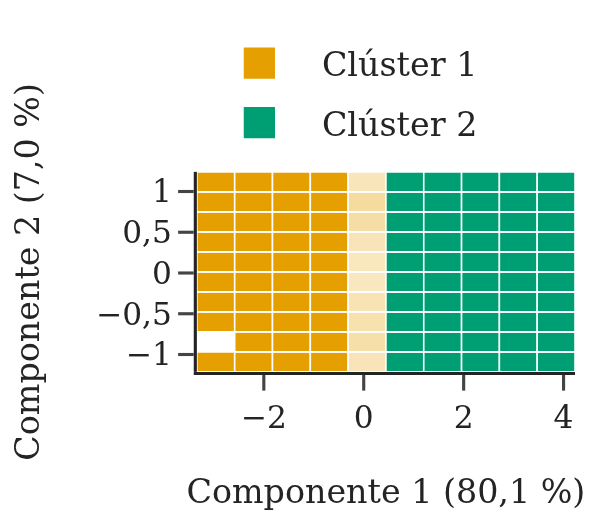

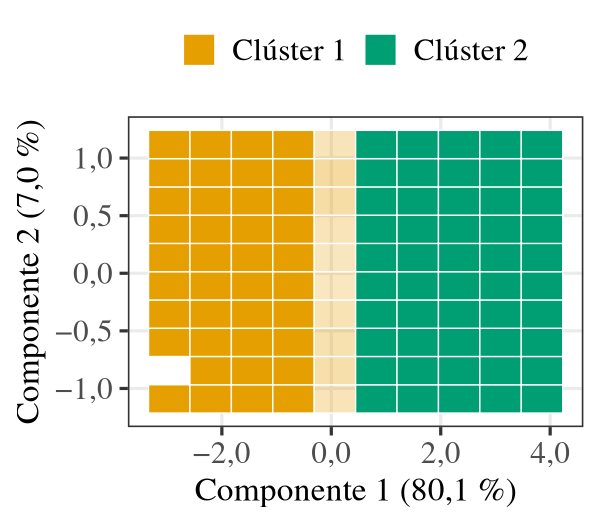

In [61]:
RUTA_HERRAMIENTAS = RUTA_FIGURAS / "herramientas"
RUTA_HERRAMIENTAS.mkdir(exist_ok=True)
# La misma letra en las cuatro herramientas: 8 puntos en los títulos de los ejes y 7,5 en las marcas y la
# leyenda (en ggplot2, `base_size = 8` y 7,5 en las marcas y la leyenda). El ajuste automático del diseño deja todo
# dentro del lienzo, como en Plotly y ggplot2, sin sumar instrucciones a las funciones que se miden.
ESTILO_HERRAMIENTAS = {
    "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5, "figure.autolayout": True,
    "legend.handlelength": 1.2, "legend.handletextpad": 0.4, "legend.columnspacing": 0.8, "legend.borderaxespad": 0.2,
}
ETIQUETAS_ESTRATO = [h3["etiquetas_a"][e].replace(" ", "\n") for e in h3["niveles_a"]]
SIMBOLOS_NATURALEZA = {REFERENCIA: "o", NIVEL: "s"}


def color_rgba(color: str, alfa: float) -> str:
    """Color de Matplotlib como texto `rgba(...)` de Plotly, con la opacidad dada."""
    rojo, verde, azul, _ = (round(255 * canal) for canal in to_rgba(color))
    return f"rgba({rojo},{verde},{azul},{alfa:.3f})"


def interaccion_matplotlib(medias: pd.DataFrame) -> plt.Figure:
    figura, eje = plt.subplots(figsize=TAMANO_INTERACCION)
    posiciones = np.arange(len(h3["niveles_a"]))
    for naturaleza_ in h3["niveles_b"]:
        celdas = medias.xs(naturaleza_, level="naturaleza").reindex(h3["niveles_a"])
        eje.errorbar(
            posiciones, celdas["media"], yerr=[celdas["media"] - celdas["inferior"], celdas["superior"] - celdas["media"]], fmt=f"-{SIMBOLOS_NATURALEZA[naturaleza_]}",
            markersize=3.5, linewidth=1, capsize=2, color=COLORES_NATURALEZA[naturaleza_], label=h3["etiquetas_b"][naturaleza_],
        )
    eje.set_xticks(posiciones, ETIQUETAS_ESTRATO)
    eje.set(xlabel="Estrato", ylabel="Puntaje global medio")
    eje.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
    return figura


def interaccion_seaborn(medias: pd.DataFrame) -> plt.Figure:
    largo = medias[["inferior", "media", "superior"]].reset_index().melt(id_vars=["estrato", "naturaleza"], value_name="puntaje")
    largo = largo.assign(estrato=largo["estrato"].map(dict(zip(h3["niveles_a"], ETIQUETAS_ESTRATO, strict=True))), naturaleza=largo["naturaleza"].map(h3["etiquetas_b"]))
    figura, eje = plt.subplots(figsize=TAMANO_INTERACCION)
    sns.pointplot(
        data=largo, x="estrato", y="puntaje", hue="naturaleza", order=ETIQUETAS_ESTRATO, hue_order=[h3["etiquetas_b"][n] for n in h3["niveles_b"]],
        palette=[COLORES_NATURALEZA[n] for n in h3["niveles_b"]], markers=[SIMBOLOS_NATURALEZA[n] for n in h3["niveles_b"]], estimator="median",
        errorbar=lambda valores: (valores.min(), valores.max()), capsize=0.15, markersize=3.5, linewidth=1, err_kws={"linewidth": 1}, ax=eje,
    )
    eje.set(xlabel="Estrato", ylabel="Puntaje global medio")
    sns.move_legend(eje, "lower left", bbox_to_anchor=(0, 1.0), ncol=2, title=None)
    return figura


def plano_seaborn(celdas: pd.DataFrame) -> plt.Figure:
    centros = celdas.assign(
        x=(celdas["x_inferior"] + celdas["x_superior"]) / 2, y=(celdas["y_inferior"] + celdas["y_superior"]) / 2,
        intensidad=alfa_por_proporcion(celdas["proporcion"]), grupo=[f"Clúster {c}" for c in celdas["cluster"]],
    )
    bordes = [np.union1d(celdas[f"{eje_}_inferior"], celdas[f"{eje_}_superior"]) for eje_ in ("x", "y")]
    figura, eje = plt.subplots(figsize=TAMANO_PLANO)
    # Con vmax en 2, la intensidad completa cae en el centro de la rampa que Seaborn arma para cada clúster.
    sns.histplot(
        data=centros, x="x", y="y", weights="intensidad", hue="grupo", hue_order=sorted(centros["grupo"].unique()), bins=bordes,
        palette={f"Clúster {c}": COLORES_CLUSTER[c - 1] for c in celdas["cluster"].unique()}, vmin=0, vmax=2, edgecolor="white", linewidth=0.3, ax=eje,
    )
    eje.set(xlabel=titulo_componente(1), ylabel=titulo_componente(2))
    eje.margins(0)
    eje.xaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
    eje.yaxis.set_major_formatter(graficos.FORMATO_DECIMAL)
    eje.grid(False)
    sns.move_legend(eje, "lower left", bbox_to_anchor=(0, 1.0), ncol=4, title=None)
    return figura


def plano_plotly(celdas: pd.DataFrame) -> go.Figure:
    """Cada celda es una forma del diseño; un marcador invisible en su centro da su n y su proporción al pasar el cursor."""
    formas = [
        {
            "type": "rect", "x0": celda["x_inferior"], "x1": celda["x_superior"], "y0": celda["y_inferior"], "y1": celda["y_superior"], "layer": "below", "opacity": 1,
            "line": {"color": "white", "width": 0.5}, "fillcolor": color_rgba(COLORES_CLUSTER[int(celda["cluster"]) - 1], alfa),
        }
        for (_, celda), alfa in zip(celdas.iterrows(), alfa_por_proporcion(celdas["proporcion"]), strict=True)
    ]
    figura = go.Figure(layout={"shapes": formas})
    for cluster, grupo in celdas.groupby("cluster"):
        figura.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=f"Clúster {cluster}", marker={"symbol": "square", "size": 10, "color": COLORES_CLUSTER[cluster - 1]}))
        figura.add_trace(go.Scatter(
            x=(grupo["x_inferior"] + grupo["x_superior"]) / 2, y=(grupo["y_inferior"] + grupo["y_superior"]) / 2, mode="markers", showlegend=False,
            marker={"symbol": "square", "size": 14, "opacity": 0}, customdata=grupo[["n", "proporcion"]].assign(proporcion=100 * grupo["proporcion"]),
            hovertemplate=f"Clúster {cluster} en el %{{customdata[1]:.0f}} % de %{{customdata[0]:,.0f}} estudiantes<extra></extra>",
        ))
    figura.update_layout(
        template="simple_white", width=TAMANO_PLANO[0] * graficos.PUNTOS_POR_PULGADA_PLOTLY, height=TAMANO_PLANO[1] * graficos.PUNTOS_POR_PULGADA_PLOTLY,
        xaxis={"title": {"text": titulo_componente(1), "font": LETRA_PLOTLY}, "range": [celdas["x_inferior"].min(), celdas["x_superior"].max()], "tickfont": MARCAS_PLOTLY, "zeroline": False},
        yaxis={"title": {"text": titulo_componente(2), "font": LETRA_PLOTLY}, "range": [celdas["y_inferior"].min(), celdas["y_superior"].max()], "tickfont": MARCAS_PLOTLY, "zeroline": False},
        separators=",.", font=LETRA_PLOTLY, margin={"l": 8, "r": 8, "t": 8, "b": 8}, legend={"orientation": "h", "x": 0, "y": 1.02, "yanchor": "bottom"},
    )
    return figura


GRAFICOS_HERRAMIENTAS = {
    "interaccion": (medias_h3, {"Matplotlib": interaccion_matplotlib, "Seaborn": interaccion_seaborn, "Plotly": interaccion_plotly}),
    "plano": (celdas_clusteres, {"Matplotlib": plano_matplotlib, "Seaborn": plano_seaborn, "Plotly": plano_plotly}),
}
MEDICION_R = {"interaccion": salida_r["medicion"]["interaccion"], "plano": salida_r_multivariante["medicion"]["plano"]}
PNG_GGPLOT = {"interaccion": "interaccion-ggplot2.png", "plano": "plano-pca-ggplot2.png"}
filas_medicion = []
with plt.rc_context(ESTILO_HERRAMIENTAS):
    for grafico, (datos_grafico, funciones) in GRAFICOS_HERRAMIENTAS.items():
        for herramienta, construir in funciones.items():
            ruta_png = RUTA_HERRAMIENTAS / f"{grafico}-{herramienta.lower()}.png"
            filas_medicion.append({"Gráfico": grafico, "Herramienta": herramienta, **graficos.medir(construir, datos_grafico, ruta_png)})
            figuras.registrar(ruta_png)
for grafico, medida in MEDICION_R.items():
    filas_medicion.append({
        "Gráfico": grafico, "Herramienta": "ggplot2", "Instrucciones": medida["instrucciones"], "Tiempo a PNG (s)": medida["tiempo_s"],
        "PNG (kB)": medida["png_kb"], "Segunda salida": "PDF vectorial", "Segunda salida (kB)": medida["pdf_kb"],
    })
medicion = pd.DataFrame(filas_medicion).set_index(["Gráfico", "Herramienta"]).sort_index(level=0, sort_remaining=False)
tabla(medicion, 3)
for grafico, medida in MEDICION_R.items():
    print(f"ggplot2 ({grafico}): {medida['componentes']} componentes encadenados con + en {medida['instrucciones']} instrucción")
guardar_plotly(plano_plotly(celdas_clusteres), "plano-clusteres")
RUTA_HTML_HERRAMIENTAS = {"interaccion": RUTA_INTERACTIVAS / "interaccion-h3.html", "plano": RUTA_INTERACTIVAS / "plano-clusteres.html"}
pesos_html = {grafico: ruta.stat().st_size / 1024 for grafico, ruta in RUTA_HTML_HERRAMIENTAS.items()}
print("HTML publicados: " + "; ".join(f"{relativa(RUTA_HTML_HERRAMIENTAS[g])}, {en_espanol(peso, 1)} kB" for g, peso in pesos_html.items()))

comprobar(
    "Comparación medida: cuatro herramientas en las dos figuras, con tiempo y pesos positivos",
    len(medicion) == 8 and (medicion[["Tiempo a PNG (s)", "PNG (kB)", "Segunda salida (kB)"]] > 0).all().all(),
)
comprobar("Comparación medida: las figuras de las tres bibliotecas de Python están en figuras/fase-3/herramientas/", all((RUTA_HERRAMIENTAS / f"{g}-{h.lower()}.png").is_file() for g, (_, f) in GRAFICOS_HERRAMIENTAS.items() for h in f))
comprobar("Comparación medida: los HTML de las dos figuras solo traen los agregados (pesan menos de 100 kB)", max(pesos_html.values()) < 100)
por_grafico = {grafico: medicion.loc[grafico] for grafico in GRAFICOS_HERRAMIENTAS}
comprobar(
    "La lectura de §20.1 coincide con la medición: instrucciones citadas, Plotly el más lento en exportar a PNG y los PDF de ggplot2 de menos de la mitad",
    medicion["Instrucciones"].tolist() == [7, 7, 5, 1, 9, 11, 6, 1]
    and all(m.loc["Plotly", "Tiempo a PNG (s)"] == m["Tiempo a PNG (s)"].max() for m in por_grafico.values())
    and all(m.loc["ggplot2", "Segunda salida (kB)"] < 0.5 * m.loc[["Matplotlib", "Seaborn"], "Segunda salida (kB)"].min() for m in por_grafico.values()),
)
SUFIJO_GRAFICO = {"interaccion": "Interaccion", "plano": "Plano"}
SUFIJO_HERRAMIENTA = {"Matplotlib": "Matplotlib", "Seaborn": "Seaborn", "Plotly": "Plotly", "ggplot2": "Ggplot"}
for (grafico, herramienta), fila in medicion.iterrows():
    sufijo = SUFIJO_GRAFICO[grafico] + SUFIJO_HERRAMIENTA[herramienta]
    cifra(f"medidaInstrucciones{sufijo}", fila["Instrucciones"])
    cifra(f"medidaTiempo{sufijo}", fila["Tiempo a PNG (s)"], 2)
    cifra(f"medidaPng{sufijo}", fila["PNG (kB)"], 0)
    cifra(f"medidaSegunda{sufijo}", fila["Segunda salida (kB)"], 0)
for grafico, medida in MEDICION_R.items():
    cifra(f"medidaComponentes{SUFIJO_GRAFICO[grafico]}Ggplot", medida["componentes"])
for grafico, peso in pesos_html.items():
    cifra(f"medidaHtml{SUFIJO_GRAFICO[grafico]}", peso, 0)

for grafico in GRAFICOS_HERRAMIENTAS:
    for herramienta in ("matplotlib", "seaborn", "plotly"):
        display(Image(filename=RUTA_HERRAMIENTAS / f"{grafico}-{herramienta}.png", width=300))
    display(Image(filename=RUTA_FIGURAS / "r" / PNG_GGPLOT[grafico], width=300))

**Lectura.** Las cuatro herramientas llegan a las mismas dos figuras y a la misma lectura: en la interacción, la brecha entre las dos líneas se abre con el estrato, y el plano queda partido por una frontera vertical, con la columna de celdas mixtas en el centro. Sus diferencias están en cómo se escribe cada figura y en lo que cuesta su salida.

- **Matplotlib** pide declarar cada elemento (7 instrucciones en la interacción y 9 en el plano, que además se apoya en la función `rectangulos` de §16), pero dibuja sin rodeos lo que ya viene calculado: los intervalos con `errorbar` y cada celda como un rectángulo con su color y su opacidad.
- **Seaborn** no ahorra código cuando los datos ya están agregados (7 y 11 instrucciones): hay que darles a los intervalos una forma artificial para que `pointplot` los dibuje, y el plano solo sale como un histograma ponderado, con una rampa de color propia que oscurece el ámbar del clúster 1. Su terreno es la estimación sobre los datos crudos, como el histograma bidimensional de los residuos en la fase 2.
- **Plotly** escribe las dos figuras con menos instrucciones (5 y 6), pero tarda segundos en exportar cada PNG, frente a décimas en las demás, porque lo hace a través de un navegador sin interfaz (Kaleido), y en el plano hubo que resolver con formas y marcadores invisibles lo que en las otras es un rectángulo. A cambio, su HTML es la única salida interactiva: al pasar el cursor da el n y el intervalo de cada celda de la interacción, o el n y la proporción del clúster en cada celda del plano, y pesa decenas de kB porque carga la biblioteca desde la CDN y solo trae los agregados.
- **ggplot2** escribe cada figura en una sola expresión de 8 componentes encadenados con `+`, la forma más compacta de las cuatro, y sus PDF pesan menos de la mitad que los de Matplotlib y Seaborn.

### 20.2. Interactividad, facetas y elección

La medición dice cuánto cuesta cada figura; la tabla dice qué puede hacer cada herramienta con ella. Las cuatro hacen facetas, y esta fase las usa en la figura de medias de H1 y H2, que tiene un panel por hipótesis en Matplotlib (`plt.subplots`), en Plotly (`make_subplots`) y en ggplot2 (`facet_wrap`). Solo Plotly produce una salida interactiva sin instalar nada más.

| Herramienta | Salida interactiva | Al pasar el cursor | Facetas | Uso en esta fase |
| --- | --- | --- | --- | --- |
| Matplotlib | No: PNG y PDF estáticos; sus *backends* interactivos solo funcionan con el cuaderno abierto | Nada | Rejilla de ejes armada a mano con `plt.subplots` | Las figuras del informe: medias, Tukey, modelos, PCA y perfiles |
| Seaborn | No: dibuja sobre Matplotlib y hereda sus salidas | Nada | `FacetGrid` y los parámetros `col` y `row` de `relplot`, `catplot` y `displot` | El mapa de calor anotado de los residuos de H4 |
| Plotly | Sí: un HTML autónomo que carga la biblioteca desde la CDN, y las pestañas del dashboard | n, media e intervalo de cada grupo o celda; además, acercar, desplazar y ocultar series desde la leyenda | `make_subplots`, o `facet_col` y `facet_row` en Plotly Express | La interacción de H3 en el informe y las versiones interactivas de §3 a §6 y §17.4 |
| ggplot2 | No sin paquetes adicionales (`plotly::ggplotly` o `ggiraph`, que el proyecto no instala) | Nada | `facet_wrap` y `facet_grid`, un solo componente de la expresión | La réplica en R de las medias, la interacción, el plano y los perfiles |

La celda siguiente revisa los HTML publicados: cada uno tiene texto para el cursor y carga Plotly desde la CDN en lugar de incrustarlo.

In [62]:
interactivas = sorted(RUTA_INTERACTIVAS.glob("*.html"))
textos_html = {ruta.name: ruta.read_text(encoding="utf-8") for ruta in interactivas}
resumen_interactivas = pd.DataFrame({
    "kB": [ruta.stat().st_size / 1024 for ruta in interactivas],
    "Texto al pasar el cursor": ["hovertemplate" in textos_html[ruta.name] for ruta in interactivas],
    "Plotly desde la CDN": ['src="https://cdn.plot.ly/' in textos_html[ruta.name] for ruta in interactivas],
}, index=[relativa(ruta) for ruta in interactivas])
tabla(resumen_interactivas, 1)
comprobar(f"Los {len(interactivas)} HTML interactivos tienen texto para el cursor y cargan Plotly desde la CDN", len(interactivas) >= 5 and resumen_interactivas[["Texto al pasar el cursor", "Plotly desde la CDN"]].all().all())
cifra("interactivasFaseTres", len(interactivas))

                                                   kB Texto al pasar el cursor Plotly desde la CDN
figuras/fase-3/interactivas/interaccion-h3.html  11,3                     True                True
figuras/fase-3/interactivas/medias-ic.html       13,6                     True                True
figuras/fase-3/interactivas/plano-clusteres.html 35,7                     True                True
figuras/fase-3/interactivas/residuos-h4.html     11,3                     True                True
figuras/fase-3/interactivas/tukey-h2.html        19,8                     True                True
[ok] Los 5 HTML interactivos tienen texto para el cursor y cargan Plotly desde la CDN


'5'

**Lectura.** La elección sigue el uso de cada figura. Para el informe impreso, Matplotlib es la herramienta principal: controla cada elemento, sus PDF son vectoriales y livianos y exporta en décimas de segundo. Seaborn se reserva para lo que resuelve en una llamada, como el mapa de calor anotado de los residuos de H4, y la interacción de H3 va en Plotly porque es la misma figura que se explora en el dashboard. Plotly es la biblioteca de todo lo interactivo: los cinco HTML de `figuras/fase-3/interactivas/` y las pestañas «Pruebas de hipótesis» y «Segmentación» del dashboard, donde el lector puede pasar el cursor por cada grupo o celda. ggplot2 queda para la réplica en R, donde su gramática compacta y sus facetas hacen corto el código que acompaña la paridad. Ninguna herramienta gana en todo: la que más escribe, Matplotlib, es la que más controla, y la única interactiva, Plotly, es la más lenta para exportar una imagen.

## 21. Agregados para el dashboard

El dashboard (`dashboard/app.py`) solo lee `data/agregados/`, nunca los recortes con filas individuales. Esta fase agrega diez archivos del 2022-2 con la regla de las fases 1 y 2: **cada archivo es un cruce completo con 10 o más estudiantes en cada celda, sin supresión.** Las pruebas de hipótesis resumen los casos de cada prueba, y el multivariante, a los estudiantes de entrenamiento con las cinco áreas.

- **`hipotesis-medias-20224.csv`:** media del puntaje global con su desviación y su intervalo t del 95 % para cada grupo de H1 (internet) y de H2 (educación de la madre), con los grupos descriptivos marcados (`probado` en falso).
- **`hipotesis-interaccion-20224.csv`:** lo mismo para cada celda de estrato y naturaleza del colegio (H3).
- **`hipotesis-tukey-20224.csv`:** los 45 pares de niveles de H2 con la diferencia de medias, el intervalo simultáneo y el p ajustado de Tukey y de Games-Howell; su `n` es el del menor de los dos grupos.
- **`hipotesis-residuos-20224.csv`:** las celdas de las dos tablas de H4 con su número de estudiantes y su residuo estandarizado ajustado.
- **`pca-celdas-20224.csv`:** las celdas del plano PCA de §16 y §17.4 con sus bordes, su `n`, el clúster mayoritario y su proporción. La rejilla tiene 10 celdas por eje; las vacías no tienen estudiantes y no se escriben.
- **`pca-cargas-20224.csv`:** las cargas de las cinco áreas en los cinco componentes y la varianza que explica cada uno; su `n` es el de los estudiantes de entrenamiento con las cinco áreas.
- **`cluster-perfiles-20224.csv`:** por clúster de K-Means, sus estudiantes y su porcentaje, la media de cada área en la escala de la prueba y estandarizada, y el puntaje global medio.
- **`cluster-estrato-20224.csv`, `cluster-zona-20224.csv` y `cluster-naturaleza-20224.csv`:** estudiantes de cada nivel en cada clúster y el porcentaje del nivel que cae en cada uno.

Antes de escribir cada archivo se comprueba que sea un cruce completo (cada combinación de sus dimensiones aparece una vez) con 10 o más estudiantes en cada celda, y que los conteos sumen los estudiantes que resumen, para que ninguna celda haya quedado por fuera. Si un archivo no cumpliera, el cuaderno se detendría y el dashboard diría que ese cruce no está publicado. Los valores se redondean a cuatro decimales y no a dos, como en las fases 1 y 2, porque el dashboard los muestra con uno o dos y un doble redondeo puede mover la última cifra: la varianza del primer componente, 80,149 %, guardada como 80,15, se mostraría como 80,2 y no como el 80,1 de §16.

In [63]:
RUTA_AGREGADOS = datos.DESTINO / "agregados"
DECIMALES_AGREGADO = 4
NOMBRE_AREA_AGREGADO = {
    "PUNT_LECTURA_CRITICA": "lectura_critica", "PUNT_MATEMATICAS": "matematicas", "PUNT_C_NATURALES": "ciencias_naturales",
    "PUNT_SOCIALES_CIUDADANAS": "sociales_ciudadanas", "PUNT_INGLES": "ingles",
}


def es_cruce_completo(marco: pd.DataFrame, dimensiones: list[str], por: str | None = None) -> bool:
    """Cada combinación de las dimensiones aparece una vez (dentro de cada valor de `por`, si se da)."""
    partes = marco.groupby(por) if por else [(None, marco)]
    return all(len(parte) == int(np.prod([parte[d].nunique() for d in dimensiones])) and not parte.duplicated(dimensiones).any() for _, parte in partes)


def medias_agregado(hipotesis_: str, variable: str, medias: pd.DataFrame, etiquetas: dict, probados: list[str]) -> pd.DataFrame:
    """Medias por grupo de una hipótesis, en el orden de su figura, con su etiqueta y si el grupo entra en la prueba."""
    marco = medias.rename_axis("grupo").reset_index()
    marco = marco.assign(hipotesis=hipotesis_, variable=variable, orden=range(len(marco)), etiqueta=marco["grupo"].map(etiquetas), probado=marco["grupo"].isin(probados))
    return marco[["hipotesis", "variable", "orden", "grupo", "etiqueta", "probado", "n", "media", "desviacion", "inferior", "superior"]]


hipotesis_medias = pd.concat([
    medias_agregado("H1", "Internet en el hogar", medias_h1, h1["etiquetas"], h1["grupos"]),
    medias_agregado("H2", "Educación de la madre", medias_h2, {**h2["etiquetas"], SIN_DATO: SIN_DATO}, h2["niveles"]),
], ignore_index=True)
hipotesis_interaccion = medias_h3.reset_index()[["estrato", "naturaleza", "n", "media", "desviacion", "inferior", "superior"]]

pares_h2 = pd.concat({"Tukey": tukey_h2, "Games-Howell": games_howell_h2}, names=["metodo"]).reset_index(level="metodo").reset_index(drop=True)
hipotesis_tukey = pares_h2.assign(
    par=[f"{h2['etiquetas'][a]} → {h2['etiquetas'][b]}" for a, b in zip(pares_h2["grupo_a"], pares_h2["grupo_b"], strict=True)],
    consecutivo=[(a, b) in consecutivos for a, b in zip(pares_h2["grupo_a"], pares_h2["grupo_b"], strict=True)],
    n=np.minimum(pares_h2["grupo_a"].map(medias_h2["n"]), pares_h2["grupo_b"].map(medias_h2["n"])),
)[["metodo", "grupo_a", "grupo_b", "par", "consecutivo", "diferencia", "inferior", "superior", "p", "n"]]

hipotesis_residuos = pd.concat([
    pd.DataFrame({"n": tablas_h4[nombre].stack(), "residuo": residuos_h4[nombre].stack()}).rename_axis(["fila", "columna"]).reset_index().assign(tabla=nombre)
    for nombre in h4
], ignore_index=True)[["tabla", "fila", "columna", "n", "residuo"]]

pca_celdas = celdas_clusteres.copy()
pca_cargas = cargas.rename_axis("area").reset_index().melt(id_vars="area", var_name="componente", value_name="carga")
pca_cargas = pca_cargas.assign(
    varianza=pca_cargas["componente"].map(varianza_pca["Varianza (%)"]), componente=pca_cargas["componente"].str.removeprefix("Componente ").astype(int), n=filas_z,
)[["componente", "area", "carga", "varianza", "n"]]

cluster_perfiles = pd.DataFrame({
    "n": perfiles_kmeans["n"],
    "porcentaje": 100 * perfiles_kmeans["n"] / filas_z,
    **{NOMBRE_AREA_AGREGADO[a]: perfiles_kmeans[a] for a in AREAS},
    **{f"z_{NOMBRE_AREA_AGREGADO[a]}": perfiles_kmeans[z] for a, z in zip(AREAS, COLUMNAS_Z, strict=True)},
    "puntaje_global": global_por_cluster,
}).rename_axis("cluster").reset_index()

cruces_agregados = {}
for variable, cruce in cruces_cluster.items():
    dimension = NOMBRE_R_CRUCE[variable]
    largo = cruce.T.rename_axis(index=dimension, columns="cluster").stack().rename("n").reset_index()
    largo["porcentaje"] = 100 * largo["n"] / largo.groupby(dimension)["n"].transform("sum")
    cruces_agregados[f"cluster-{dimension}-20224.csv"] = (largo, es_cruce_completo(largo, [dimension, "cluster"]))

comprobar(
    "Los conteos de los agregados de las pruebas suman los estudiantes de cada prueba",
    hipotesis_medias.groupby("hipotesis")["n"].sum().eq(len(y)).all() and hipotesis_interaccion["n"].sum() == len(datos_h3)
    and all(hipotesis_residuos.loc[hipotesis_residuos["tabla"].eq(nombre), "n"].sum() == contrastes_h4[nombre].n for nombre in h4),
)
comprobar(
    "Los conteos de los agregados del multivariante suman los estudiantes de entrenamiento con las cinco áreas (o los que tienen el dato de cada cruce)",
    pca_celdas["n"].sum() == cluster_perfiles["n"].sum() == filas_z and (pca_cargas["n"] == filas_z).all()
    and all(cruces_agregados[f"cluster-{NOMBRE_R_CRUCE[x]}-20224.csv"][0]["n"].sum() == contrastes_cluster[x].n for x in CRUCES),
)
comprobar("El n de cada par de Tukey es el del menor de sus dos grupos, y cada método tiene los 45 pares", hipotesis_tukey.groupby("metodo").size().eq(45).all() and hipotesis_tukey["n"].le(hipotesis_tukey["grupo_a"].map(medias_h2["n"])).all())

AGREGADOS_FASE_3 = {
    "hipotesis-medias-20224.csv": (hipotesis_medias, es_cruce_completo(hipotesis_medias, ["grupo"], por="hipotesis")),
    "hipotesis-interaccion-20224.csv": (hipotesis_interaccion, es_cruce_completo(hipotesis_interaccion, ["estrato", "naturaleza"])),
    "hipotesis-tukey-20224.csv": (hipotesis_tukey, es_cruce_completo(hipotesis_tukey, ["par"], por="metodo")),
    "hipotesis-residuos-20224.csv": (hipotesis_residuos, es_cruce_completo(hipotesis_residuos, ["fila", "columna"], por="tabla")),
    # La rejilla no es un producto: sus celdas vacías no tienen estudiantes. Que no falte ninguna lo prueba la suma de arriba.
    "pca-celdas-20224.csv": (pca_celdas, not pca_celdas.duplicated(["celda_x", "celda_y"]).any()),
    "pca-cargas-20224.csv": (pca_cargas, es_cruce_completo(pca_cargas, ["componente", "area"])),
    "cluster-perfiles-20224.csv": (cluster_perfiles, es_cruce_completo(cluster_perfiles, ["cluster"])),
    **cruces_agregados,
}
RUTA_AGREGADOS.mkdir(parents=True, exist_ok=True)
for nombre, (agregado, completo) in AGREGADOS_FASE_3.items():
    comprobar(f"{nombre}: cruce completo, con {segmentacion.MINIMO_POR_GRUPO} o más estudiantes en cada una de sus {len(agregado)} celdas", completo and agregado["n"].min() >= segmentacion.MINIMO_POR_GRUPO)
    agregado.round(DECIMALES_AGREGADO).to_csv(RUTA_AGREGADOS / nombre, index=False)
    print(f"Escrito {relativa(RUTA_AGREGADOS / nombre)}: {len(agregado)} filas, la menor celda con {en_espanol(int(agregado['n'].min()))} estudiantes")
comprobar(
    "Fuera del plano, la menor celda de los agregados es el grupo descriptivo «No Aplica» de H2",
    min(agregado["n"].min() for nombre, (agregado, _) in AGREGADOS_FASE_3.items() if nombre != "pca-celdas-20224.csv") == medias_h2.loc["No Aplica", "n"],
)
cifra("archivosAgregadosNuevos", len(AGREGADOS_FASE_3))
cifra("celdaMinimaAgregados", int(min(agregado["n"].min() for agregado, _ in AGREGADOS_FASE_3.values())));

[ok] Los conteos de los agregados de las pruebas suman los estudiantes de cada prueba
[ok] Los conteos de los agregados del multivariante suman los estudiantes de entrenamiento con las cinco áreas (o los que tienen el dato de cada cruce)
[ok] El n de cada par de Tukey es el del menor de sus dos grupos, y cada método tiene los 45 pares
[ok] hipotesis-medias-20224.csv: cruce completo, con 10 o más estudiantes en cada una de sus 16 celdas
Escrito data/agregados/hipotesis-medias-20224.csv: 16 filas, la menor celda con 1098 estudiantes
[ok] hipotesis-interaccion-20224.csv: cruce completo, con 10 o más estudiantes en cada una de sus 14 celdas
Escrito data/agregados/hipotesis-interaccion-20224.csv: 14 filas, la menor celda con 1727 estudiantes
[ok] hipotesis-tukey-20224.csv: cruce completo, con 10 o más estudiantes en cada una de sus 90 celdas
Escrito data/agregados/hipotesis-tukey-20224.csv: 90 filas, la menor celda con 10.258 estudiantes
[ok] hipotesis-residuos-20224.csv: cruce completo, co

**Lectura.** Los diez archivos cumplen la regla sin suprimir ninguna celda: la menor de todas tiene 77 estudiantes (una celda del borde del plano PCA) y, fuera del plano, la menor es la del grupo descriptivo «No aplica» de H2, con 1098. Ninguno contiene filas individuales: son medias, conteos, residuos y cargas de grupos de 77 estudiantes o más, y las celdas del plano son las mismas que dibujan las figuras de §16 y §17.4. Con ellos, la pestaña «Pruebas de hipótesis» del dashboard dibuja en Plotly las medias de H1 y H2 con sus intervalos, los pares de Tukey y de Games-Howell, la interacción de H3 y los residuos de H4, y la pestaña «Segmentación» dibuja el plano por celdas con las cargas de los dos primeros componentes, los perfiles de los clústeres y su reparto por estrato, zona y naturaleza. Si en una nueva ejecución algún cruce dejara una celda por debajo de 10, el cuaderno se detendría antes de escribirlo, y el dashboard, al no encontrar el archivo, diría que ese cruce no está publicado.

## 22. Evaluación única en prueba

Esta es la única celda que toca la prueba, como pide la clase («la prueba se toca una sola vez»). Cada modelo final de esta fase (`modelos.FINALES_FASE_3`) se evalúa una vez, con lo que quedó fijado en validación: los hiperparámetros, el modelo reajustado y, en la clasificación, el umbral de F1. `modelos.predecir_en_prueba` revisa el registro antes de predecir y falla si el modelo ya se evaluó; luego guarda sus métricas en `resultados/evaluaciones-prueba-fase-3.json` y devuelve las predicciones sin escribirlas en ningún archivo. Las bases de la fase 2 no se vuelven a evaluar: sus métricas de prueba se leen de su registro. Los clasificadores reciben solo las once columnas del hogar y del estudiante.

Con las predicciones de la misma celda, la prueba de McNemar compara los dos clasificadores de mayor AUC de validación. Cuenta los estudiantes que uno clasifica bien y el otro mal, en cada sentido; si los dos modelos acertaran igual, esos dos conteos serían parecidos, y el estadístico, con corrección de continuidad, mide cuánto se apartan.

In [64]:
y_prueba_regresion = y_prueba[OBJETIVO]
y_prueba_clase = y_prueba[v.OBJETIVO_CLASIFICACION].eq(POSITIVA).astype(int)
X_prueba_clase = X_prueba[COLUMNAS_CLASE]
finales_regresion = {**regularizados, "randomForestRegresion": bosque_regresion, "xgboostRegresion": xgboost_regresion, "mlpRegresion": red_regresion}
comprobar("Los modelos finales son los de regresión y clasificación ajustados en este cuaderno", set(modelos.FINALES_FASE_3) == set(finales_regresion) | set(clasificadores))
predicciones_prueba: dict[str, np.ndarray] = {}
for nombre in modelos.FINALES_FASE_3:
    if nombre in finales_regresion:
        predicciones_prueba[nombre] = modelos.predecir_en_prueba(
            RUTA_PRUEBA, nombre, lambda m=finales_regresion[nombre]: m.predict(X_prueba), lambda p: modelos.metricas_regresion(y_prueba_regresion, p)
        )
    else:
        predicciones_prueba[nombre] = modelos.predecir_en_prueba(
            RUTA_PRUEBA, nombre, lambda m=clasificadores[nombre]: puntaje(m, X_prueba_clase), lambda p, u=umbrales[nombre]: metricas_con_umbral(y_prueba_clase, p, u)
        )
metricas_prueba = {fila["modelo"]: fila["metricas"] for fila in json.loads(RUTA_PRUEBA.read_text(encoding="utf-8"))}
comprobar(
    "El registro de prueba de la fase 3 tiene un modelo por nombre, exactamente los de FINALES_FASE_3",
    sorted(metricas_prueba) == sorted(modelos.FINALES_FASE_3) and len(json.loads(RUTA_PRUEBA.read_text(encoding="utf-8"))) == len(modelos.FINALES_FASE_3),
)
comprobar("Ningún modelo de la fase 3 repite un nombre del registro de prueba de la fase 2", not set(metricas_prueba) & set(registro_fase_2))

prueba_regresion = pd.DataFrame({
    "Múltiple (base)": {"R² validación": de_la_fase_2("rCuadradoValidacionMultiple"), "R² prueba": registro_fase_2["regresionMultiple"]["r2"], "RMSE validación": rmse_multiple, "RMSE prueba": registro_fase_2["regresionMultiple"]["rmse"], "MAE prueba": registro_fase_2["regresionMultiple"]["mae"]},
    **{
        NOMBRE_MODELO[n]: {"R² validación": resultados_regresion[n]["r2 validación"], "R² prueba": metricas_prueba[n]["r2"], "RMSE validación": resultados_regresion[n]["rmse validación"], "RMSE prueba": metricas_prueba[n]["rmse"], "MAE prueba": metricas_prueba[n]["mae"]}
        for n in finales_regresion
    },
}).T
prueba_regresion["RMSE prueba menos validación"] = prueba_regresion["RMSE prueba"] - prueba_regresion["RMSE validación"]
prueba_clasificacion = pd.DataFrame({
    "Logística (base, umbral 0,5)": {"AUC validación": auc_logistica_fase_2, "AUC prueba": registro_fase_2["logisticaBase"]["auc"], "F1 validación": de_la_fase_2("fUnoValidacionLogistica"), "F1 prueba": registro_fase_2["logisticaBase"]["f1"], "Exactitud prueba": registro_fase_2["logisticaBase"]["accuracy"], "AUC-PR prueba": np.nan},
    **{
        NOMBRE_MODELO[n]: {"AUC validación": resultados_clasificacion[n]["auc validación"], "AUC prueba": metricas_prueba[n]["auc"], "F1 validación": resultados_clasificacion[n]["f1 validación"], "F1 prueba": metricas_prueba[n]["f1"], "Exactitud prueba": metricas_prueba[n]["accuracy"], "AUC-PR prueba": metricas_prueba[n]["aucPr"]}
        for n in clasificadores
    },
}).T
tabla(prueba_regresion, 3)
print()
tabla(prueba_clasificacion.astype(object).where(prueba_clasificacion.notna(), "n. d."), 3)
PREFIJO_PRUEBA = {"r2": "rCuadrado", "rmse": "rmse", "mae": "mae", **PREFIJO_METRICA}
for nombre, fila in metricas_prueba.items():
    sufijo = SUFIJO_REGRESION.get(nombre) or SUFIJO_CLASIFICACION[nombre]
    for metrica, valor in fila.items():
        cifra(f"{PREFIJO_PRUEBA[metrica]}Prueba{sufijo}", valor, 2 if metrica in ("rmse", "mae") else 3)
mejor_en_prueba = min(finales_regresion, key=lambda n: metricas_prueba[n]["rmse"])
cifra("mejorRegresionPrueba", NOMBRE_MODELO[mejor_en_prueba])
cifra("cambioMaximoRmsePrueba", prueba_regresion["RMSE prueba menos validación"].abs().max(), 2)
comprobar("Ningún RMSE de prueba se aparta más de 0,05 puntos del de validación", prueba_regresion["RMSE prueba menos validación"].abs().max() < 0.05)
comprobar("En prueba, los clasificadores quedan en el orden de AUC-ROC de validación", sorted(clasificadores, key=lambda n: -metricas_prueba[n]["auc"]) == orden_clasificacion)
cifra("filasPrueba", len(y_prueba))

primero, segundo = orden_clasificacion[:2]
aciertos_mcnemar = {n: (predicciones_prueba[n] >= umbrales[n]).astype(int) for n in (primero, segundo)}
tabla_mcnemar = comparacion.tabla_aciertos(y_prueba_clase.to_numpy(), aciertos_mcnemar[primero], aciertos_mcnemar[segundo])
contraste_mcnemar = comparacion.mcnemar(y_prueba_clase.to_numpy(), aciertos_mcnemar[primero], aciertos_mcnemar[segundo])
print(f"\nMcNemar, {NOMBRE_MODELO[primero]} frente a {NOMBRE_MODELO[segundo]} (cada uno con su umbral), en prueba:")
tabla(pd.DataFrame(tabla_mcnemar, index=[f"{ETIQUETA_CORTA[primero]} acierta", f"{ETIQUETA_CORTA[primero]} falla"], columns=[f"{ETIQUETA_CORTA[segundo]} acierta", f"{ETIQUETA_CORTA[segundo]} falla"]))
print(f"χ² = {en_espanol(contraste_mcnemar.estadistico, 2)}, gl = 1, p = {texto_p(contraste_mcnemar.p)}")
comprobar("McNemar compara los dos clasificadores de mayor AUC de validación sobre toda la prueba", contraste_mcnemar.n == len(y_prueba) and {primero, segundo} <= set(clasificadores))
cifra("pMcnemar", texto_p(contraste_mcnemar.p))
cifra("estadisticoMcnemar", contraste_mcnemar.estadistico, 2)
cifra("mcnemarPrimero", NOMBRE_MODELO[primero])
cifra("mcnemarSegundo", NOMBRE_MODELO[segundo])
cifra("soloAciertaPrimeroMcnemar", contraste_mcnemar.detalle["solo_acierta_a"])
cifra("soloAciertaSegundoMcnemar", contraste_mcnemar.detalle["solo_acierta_b"]);

[ok] Los modelos finales son los de regresión y clasificación ajustados en este cuaderno


[ok] El registro de prueba de la fase 3 tiene un modelo por nombre, exactamente los de FINALES_FASE_3
[ok] Ningún modelo de la fase 3 repite un nombre del registro de prueba de la fase 2
                       R² validación R² prueba RMSE validación RMSE prueba MAE prueba RMSE prueba menos validación
Múltiple (base)                0,319     0,319          42,811      42,783     34,755                       -0,028
Ridge                          0,319     0,319          42,811      42,783     34,755                       -0,028
Lasso                          0,319     0,319          42,811      42,783     34,756                       -0,029
ElasticNet                     0,319     0,319          42,811      42,783     34,756                       -0,029
Random Forest ajustado         0,354     0,353          41,676      41,684     33,776                        0,008
XGBoost ajustado               0,380     0,379          40,836      40,832     32,931                       -0,004
MLP     

**Lectura.** La prueba confirma lo que se eligió en validación. En la regresión, XGBoost tiene el menor RMSE de prueba (40,83 puntos, R² de 0,379), seguido de cerca por el MLP (40,84) y después por el Random Forest (41,68); los tres regularizados repiten la múltiple de la fase 2 (42,78). Ningún RMSE de prueba se aparta más de 0,03 puntos del de validación, así que elegir modelos en validación no la sobreajustó. En la clasificación se mantiene el orden de validación: XGBoost (AUC-ROC de 0,774 y F1 de la clase no oficial de 0,524), Random Forest (0,771 y 0,522), SVM (0,762) y LDA (0,759), frente al 0,765 de la logística base de la fase 2. El F1 de prueba no cae frente al de validación aunque los umbrales se eligieron allí: con casi 80.000 estudiantes de validación, el optimismo de elegir el umbral resulta despreciable.

McNemar compara los aciertos de XGBoost y Random Forest estudiante por estudiante. De los 79.885 de prueba, 2069 quedan bien clasificados por XGBoost y mal por el bosque, y 1318 al revés; χ² = 166,08 con p < 0,001. XGBoost acierta más de forma sistemática, pero la ventaja neta es de 751 estudiantes, menos del 1 % de la prueba (exactitud de 0,772 frente a 0,763). Con este n, la prueba detecta diferencias que no cambian la respuesta a S2: los dos ensambles separan los colegios casi igual, y los dos fallan en los mismos estudiantes, los de hogares que no se parecen a los típicos de su tipo de colegio.

## 23. Cifras y comprobaciones

Última sección del cuaderno: escribe las cifras para el informe y confirma que cada figura existe.

In [65]:
for ruta in figuras.escritas:
    comprobar(f"Existe {relativa(ruta)}", ruta.is_file())
ruta_json, ruta_tex = cifras.volcar(RUTA_RESULTADOS, "cifras-fase-3")
comprobar(f"Cifras volcadas ({len(cifras)}) en {relativa(ruta_json)} y {relativa(ruta_tex)}", ruta_json.is_file() and ruta_tex.is_file())
print(control.resumen())

[ok] Existe figuras/fase-3/supuestos-qq.png
[ok] Existe figuras/fase-3/medias-ic.png
[ok] Existe figuras/fase-3/interactivas/medias-ic.html
[ok] Existe figuras/fase-3/tukey-h2.png
[ok] Existe figuras/fase-3/interactivas/tukey-h2.html
[ok] Existe figuras/fase-3/interaccion-h3.png
[ok] Existe figuras/fase-3/interactivas/interaccion-h3.html
[ok] Existe figuras/fase-3/residuos-h4.png
[ok] Existe figuras/fase-3/interactivas/residuos-h4.html
[ok] Existe figuras/fase-3/r/medias-ic-ggplot2.png
[ok] Existe figuras/fase-3/r/interaccion-ggplot2.png
[ok] Existe figuras/fase-3/regularizacion-trayectorias.png
[ok] Existe figuras/fase-3/regresion-comparacion.png
[ok] Existe figuras/fase-3/clasificacion-curvas.png
[ok] Existe figuras/fase-3/clasificacion-confusion.png
[ok] Existe figuras/fase-3/mlp-perdida.png
[ok] Existe figuras/fase-3/importancia-variables.png
[ok] Existe figuras/fase-3/shap-por-categoria.png
[ok] Existe figuras/fase-3/errores-por-grupo.png
[ok] Existe figuras/fase-3/errores-por-dep